In [17]:
import os, gc, json, time, glob, math, random, shutil, warnings
from pathlib import Path
from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

QUICK_RUN = False          # True = tiny end-to-end smoke test (~10-20 min). False = full experiment.

CFG = dict(
    seed=42,
    # ---- data / pre-processing ----
    crop=192,                    # centre crop of the 240x240 axial slice (brain lies inside)
    img_size=128,                # network resolution (192 -> 128, i.e. 1.5 mm pixels)
    n_patients=150,              # patients used (of 369) -> 60% train / 15% val / 25% test
    split=(0.60, 0.15, 0.25),
    slices_per_patient=32,       # 2D slices cached per train/val patient
    tumour_slice_frac=0.75,      # fraction of cached slices that contain tumour
    # ---- U-Net / training ----
    base_ch=16, batch_size=32, lr=2e-3, weight_decay=1e-4,
    proxy_epochs=6,              # low-fidelity training used inside the optimiser
    final_epochs=30,             # full training of the selected models (Phase 7)
    # ---- optimisation ----
    region_weights=(0.25, 0.35, 0.40),  # CWRD weights for WT, TC, ET
    pop_size=10, n_generations=6,       # budget = pop_size * (1 + n_generations) evaluations per run
    surrogate_pool=4,            # R2S: candidates generated per offspring slot before pre-screening
    redundancy_tau=0.70,         # R2S: |corr| above which two DIP features are "redundant" (conventional 'strong correlation')
    mri_copy_tau=0.95,           # R2S: |corr| with a raw MRI channel above which a feature is a near-copy and never selected
    opt_seeds=(0,),              # use (0, 1, 2) for the paper if you have GPU time
    run_optimizer_ablation=True,
    # ---- evaluation ----
    n_test_eval=None,            # None = all test patients
    n_jobs=4,                    # CPU workers (Kaggle has 4 vCPUs)
)
if QUICK_RUN:
    CFG.update(n_patients=12, slices_per_patient=8, proxy_epochs=1, final_epochs=2,
               pop_size=4, n_generations=1, surrogate_pool=3, n_test_eval=2,
               run_optimizer_ablation=False)

# ---------------- paths ----------------
INPUT_ROOT = Path(os.environ.get("BRATS_INPUT", "/kaggle/input"))
WORK = Path(os.environ.get("WORK_DIR", "/kaggle/working"))
CACHE, RES, FIG, CKPT = WORK/"brats_cache", WORK/"results", WORK/"figures", WORK/"checkpoints"
for d in (CACHE, RES, FIG, CKPT):
    d.mkdir(parents=True, exist_ok=True)

def _prior_bases():
    """Outputs of an earlier run of this notebook attached as input (for resuming)."""
    hits = []
    for depth in ("*", "*/*", "*/*/*"):
        hits += glob.glob(str(INPUT_ROOT / depth / "brats_cache" / "meta.csv"))
    return [Path(h).parent.parent for h in sorted(set(hits))]
PRIOR_BASES = _prior_bases()

def locate(rel):
    """Return the path of a saved artefact in /kaggle/working or in an attached earlier output."""
    for b in [WORK] + PRIOR_BASES:
        p = b / rel
        if p.exists():
            return p
    return None

def bring_to_work(rel):
    """Copy a small artefact (csv/json) from an attached earlier output into /kaggle/working."""
    p = locate(rel)
    if p is not None and not str(p).startswith(str(WORK)):
        (WORK/rel).parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(p, WORK/rel)
    return locate(rel)

# ---------------- torch / reproducibility ----------------
import torch, torch.nn as nn, torch.nn.functional as F
import cv2, nibabel as nib
from joblib import Parallel, delayed
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
torch.backends.cudnn.benchmark = True

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed(CFG["seed"])

plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 150, "font.size": 9})
def show_save(fig, name):
    """Save a figure to /kaggle/working/figures, show it once, then free its memory (keeps the notebook light)."""
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show(); plt.close(fig)

T_START = time.time()
def log(msg):
    print(f"[{(time.time()-T_START)/60:6.1f} min] {msg}", flush=True)

def label_rgba(lab):
    """(3,H,W) WT/TC/ET masks -> RGBA overlay: WT green, TC blue, ET red, transparent elsewhere."""
    lab = np.asarray(lab).astype(bool); o = np.zeros(lab.shape[1:] + (4,))
    o[lab[0]] = (0.1, 0.8, 0.1, 0.45); o[lab[1]] = (0.1, 0.3, 1.0, 0.55); o[lab[2]] = (1.0, 0.1, 0.1, 0.65)
    return o

def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("QUICK_RUN =", QUICK_RUN, "| device =", device, "| torch", torch.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Earlier outputs found for resuming:", [str(p) for p in PRIOR_BASES] or "none")

QUICK_RUN = False | device = cuda | torch 2.10.0+cu128
GPU: Tesla T4
Earlier outputs found for resuming: none


It initializes the experiment: imports libraries, defines hyperparameters, selects Kaggle paths, configures GPU/CPU execution, sets reproducibility, and defines helper functions for saving results, visualization, logging, and memory management.

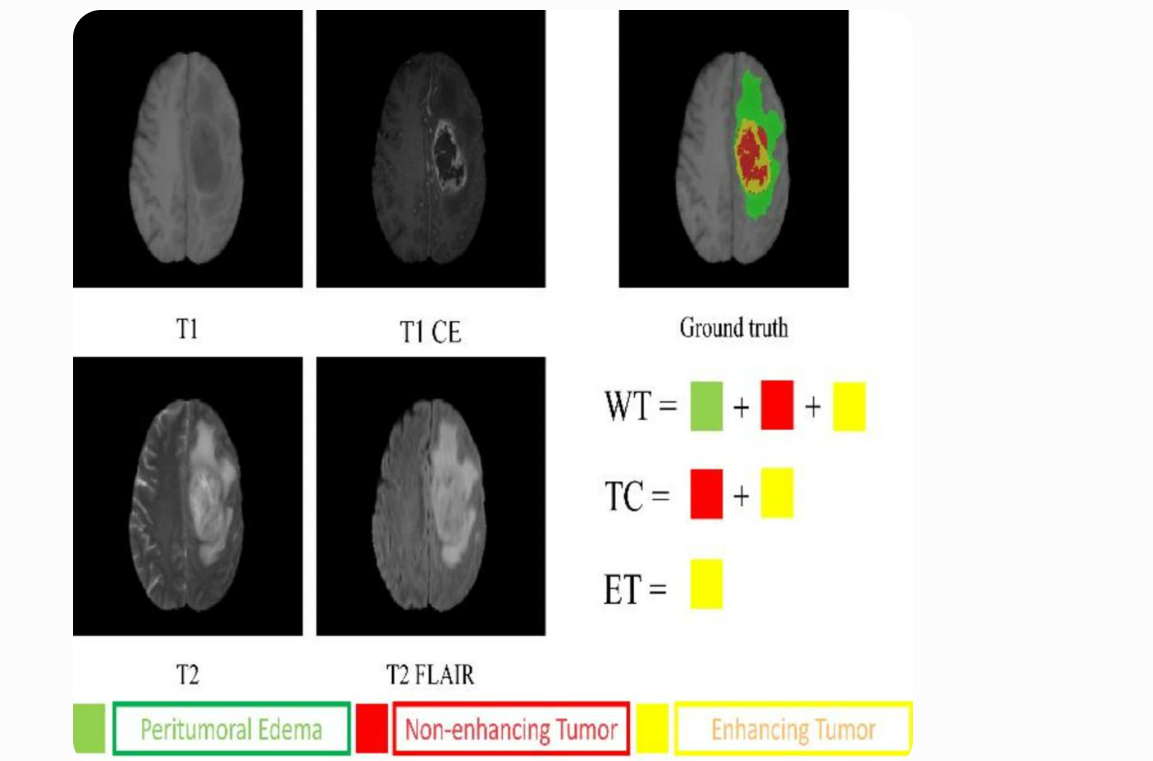

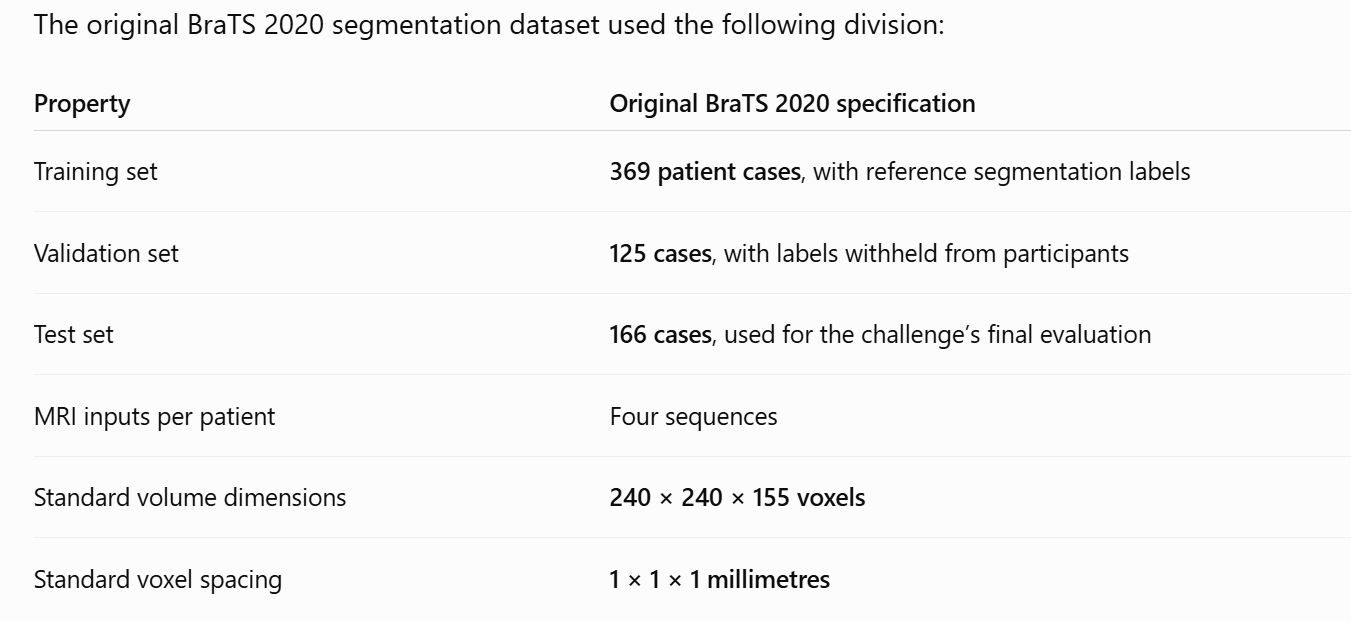

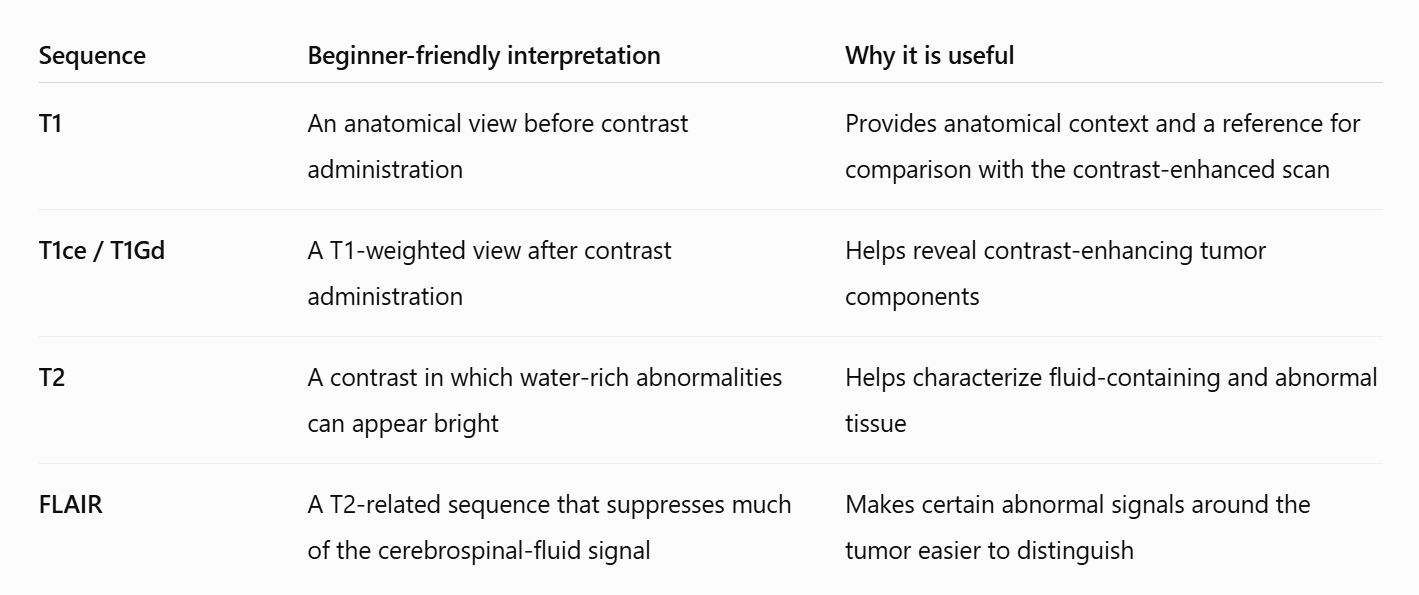

In [18]:
import nibabel as nib
import cv2

MODS = ["flair", "t1", "t1ce", "t2"]
FL, T1, T1CE, T2 = 0, 1, 2, 3
REGIONS = ["WT", "TC", "ET"]

def case_files(d):
    out = {}
    for f in glob.glob(os.path.join(d, "*.nii*")):
        n = os.path.basename(f).lower()
        if n.endswith(("_flair.nii", "_flair.nii.gz")): out["flair"] = f
        elif n.endswith(("_t1ce.nii", "_t1ce.nii.gz")): out["t1ce"] = f
        elif n.endswith(("_t1.nii", "_t1.nii.gz")):     out["t1"] = f
        elif n.endswith(("_t2.nii", "_t2.nii.gz")):     out["t2"] = f
        elif "seg" in n:                                out["seg"] = f   # also catches "..._Segm.nii" (patient 355)
    return out

def discover_cases(root):
    flairs = glob.glob(str(root/"**"/"*_flair.nii"), recursive=True) + \
             glob.glob(str(root/"**"/"*_flair.nii.gz"), recursive=True)
    cases = {}
    for f in sorted(flairs):
        d = os.path.dirname(f); cid = os.path.basename(d)
        if cid in cases:
            continue
        files = case_files(d)
        if all(m in files for m in MODS) and "seg" in files:   # labelled training cases only
            cases[cid] = files
    return cases

CASES = discover_cases(INPUT_ROOT)
print(f"Labelled patients found: {len(CASES)}")
assert len(CASES) > 0, "No BraTS training cases found - add the dataset 'awsaf49/brats20-dataset-training-validation' as input."
print("Example:", sorted(CASES)[0], {k: os.path.basename(v) for k, v in CASES[sorted(CASES)[0]].items()})

def load_case(files):
    img = np.stack([nib.load(files[m]).get_fdata(dtype=np.float32) for m in MODS], 0)   # (4,240,240,155)
    seg = np.rint(nib.load(files["seg"]).get_fdata(dtype=np.float32)).astype(np.uint8)  # (240,240,155)
    return img, seg

def seg_to_regions(seg):
    return np.stack([seg > 0, (seg == 1) | (seg == 4), seg == 4], 0).astype(np.uint8)  # WT, TC, ET

Labelled patients found: 369
Example: BraTS20_Training_001 {'flair': 'BraTS20_Training_001_flair.nii', 'seg': 'BraTS20_Training_001_seg.nii', 't1': 'BraTS20_Training_001_t1.nii', 't1ce': 'BraTS20_Training_001_t1ce.nii', 't2': 'BraTS20_Training_001_t2.nii'}


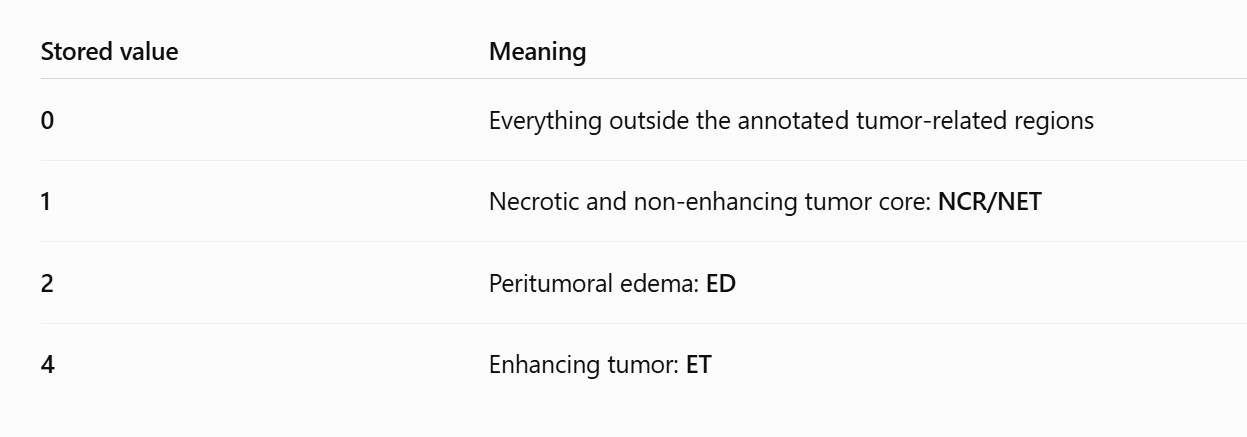

volume shape: (4, 240, 240, 155) | voxel size (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | labels: [0 1 2 4]


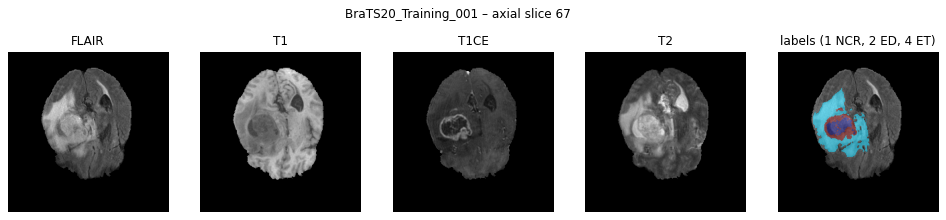

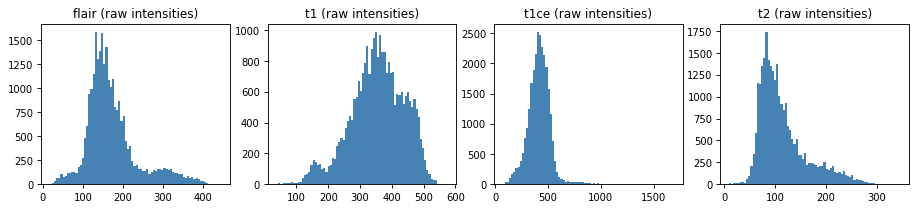

In [3]:
# ---- Look at one patient ----
cid0 = sorted(CASES)[0]
img0, seg0 = load_case(CASES[cid0])
hdr = nib.load(CASES[cid0]["flair"]).header
print("volume shape:", img0.shape, "| voxel size (mm):", hdr.get_zooms(), "| labels:", np.unique(seg0))
z0 = int(np.argmax((seg0 > 0).sum((0, 1))))

fig, ax = plt.subplots(1, 5, figsize=(15, 3.2))
for i, m in enumerate(MODS):
    ax[i].imshow(np.rot90(img0[i, :, :, z0]), cmap="gray"); ax[i].set_title(m.upper())
lab = np.rot90(seg0[:, :, z0]).astype(float); lab[lab == 0] = np.nan
ax[4].imshow(np.rot90(img0[FL, :, :, z0]), cmap="gray"); ax[4].imshow(lab, cmap="jet", alpha=0.5, vmin=1, vmax=4)
ax[4].set_title("labels (1 NCR, 2 ED, 4 ET)")
for a in ax: a.axis("off")
fig.suptitle(f"{cid0} – axial slice {z0}")
show_save(fig, "p1_example_case")

# intensity histograms inside the brain -> motivates per-patient z-score normalisation
brain0 = np.any(img0 != 0, 0)
fig, ax = plt.subplots(1, 4, figsize=(14, 2.6))
for i, m in enumerate(MODS):
    ax[i].hist(img0[i][brain0][::50], bins=80, color="steelblue"); ax[i].set_title(f"{m} (raw intensities)")
show_save(fig, "p1_intensity_hist")
del img0, seg0, brain0; free_memory()

Across several BraTS patients, how large are the Whole Tumor, Tumor Core, and Enhancing Tumor regions, and across how many axial slices does the tumor appear?

for every patient, i will add the record
{
    "case": "BraTS20_Training_001",
    "WT_ml": 48.2,
    "TC_ml": 19.6,
    "ET_ml": 7.4,
    "tumour_slices": 61
}
and at the end, this will become a pandas dataframe

       WT_ml  TC_ml  ET_ml  tumour_slices
count   30.0   30.0   30.0           30.0
mean    81.7   24.3   13.0           66.3
std     53.1   24.1   10.6           13.2
min     20.9    1.4    1.2           43.0
25%     41.8    8.6    6.0           55.0
50%     66.8   16.6    9.5           64.5
75%    102.8   30.1   18.0           79.0
max    212.0  118.7   50.9           89.0

Tumour occupies on average 0.92% of the whole volume -> strong class imbalance (motivates Dice loss and tumour-rich slice sampling).


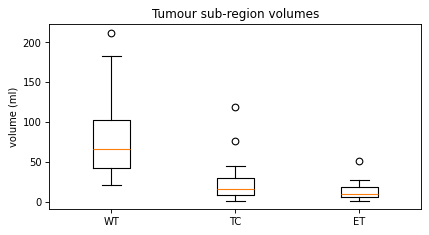

h5 dataset found: {'image': (240, 240, 4), 'mask': (240, 240, 3)} (not used - see markdown above)


In [9]:
# ---- Label statistics on a sample of patients (only the small label files are read) ----
stats = []
for cid in sorted(CASES)[: (30 if not QUICK_RUN else 5)]:
    s = np.rint(nib.load(CASES[cid]["seg"]).get_fdata(dtype=np.float32)).astype(np.uint8)
    r = seg_to_regions(s)
    stats.append(dict(case=cid, WT_ml=r[0].sum()/1000, TC_ml=r[1].sum()/1000, ET_ml=r[2].sum()/1000,
                      tumour_slices=int((r[0].sum((0, 1)) > 0).sum())))
stats = pd.DataFrame(stats)
print(stats.describe().round(1).to_string())
print(f"\nTumour occupies on average {stats.WT_ml.mean()/ (240*240*155/1e3) * 100:.2f}% of the whole volume -> strong class imbalance "
      "(motivates Dice loss and tumour-rich slice sampling).")
fig, ax = plt.subplots(figsize=(6, 3))
ax.boxplot([stats.WT_ml, stats.TC_ml, stats.ET_ml]); ax.set_xticks([1, 2, 3]); ax.set_xticklabels(REGIONS); ax.set_ylabel("volume (ml)")
ax.set_title("Tumour sub-region volumes")
show_save(fig, "p1_region_volumes")
stats.to_csv(RES/"p1_label_stats.csv", index=False)

# ---- Optional: peek at the pre-sliced .h5 dataset if it is attached ----
try:
    import h5py
    h5 = glob.glob(str(INPUT_ROOT/"**"/"volume_1_slice_80.h5"), recursive=True)
    if h5:
        with h5py.File(h5[0], "r") as f:
            print("h5 dataset found:", {k: f[k].shape for k in f.keys()}, "(not used - see markdown above)")
except Exception as e:
    print("h5 peek skipped:", e)

preprocessing

In [19]:
from joblib import Parallel, delayed
S, CROP = CFG["img_size"], CFG["crop"]
C0 = (240 - CROP) // 2
PX_MM = CROP / S                      # physical size of one network pixel (mm)

def zscore_normalise(img):
    brain = np.any(img != 0, 0)
    out = np.zeros_like(img, dtype=np.float32)
    for c in range(img.shape[0]):
        v = img[c][brain]
        lo, hi = np.percentile(v, [0.5, 99.5])
        v = np.clip(v, lo, hi)
        out[c][brain] = (v - v.mean()) / (v.std() + 1e-8)
    return out, brain

def prep_slice(a, is_mask=False):
    """a: (C,240,240) -> (C,S,S) after centre crop and resize."""
    a = a[:, C0:C0+CROP, C0:C0+CROP]
    interp = cv2.INTER_NEAREST if is_mask else cv2.INTER_AREA
    return np.stack([cv2.resize(np.ascontiguousarray(ch), (S, S), interpolation=interp) for ch in a])

def select_slices(brain, regions, n, frac, rng):
    brain_z = np.where(brain.sum((0, 1)) > 0.02 * 240 * 240)[0]
    tum_z = np.intersect1d(np.where(regions[0].sum((0, 1)) >= 20)[0], brain_z)
    non_z = np.setdiff1d(brain_z, tum_z)
    n_t = min(len(tum_z), int(round(n * frac)))
    sel = list(rng.choice(tum_z, n_t, replace=False)) if n_t else []
    n_n = min(len(non_z), n - n_t)
    sel += list(rng.choice(non_z, n_n, replace=False)) if n_n else []
    rest = np.setdiff1d(brain_z, sel)
    if len(sel) < n:                                 # rare: not enough slices of one kind
        sel += list(rng.choice(rest if len(rest) else brain_z, n - len(sel), replace=len(rest) < n - len(sel)))
    return np.sort(np.array(sel[:n], dtype=int))

def process_case(files, seed):
    img, seg = load_case(files)
    x, brain = zscore_normalise(img); del img
    reg = seg_to_regions(seg)
    zs = select_slices(brain, reg, CFG["slices_per_patient"], CFG["tumour_slice_frac"], np.random.default_rng(seed))
    X = np.stack([prep_slice(x[..., z]) for z in zs]).astype(np.float16)
    Y = np.stack([prep_slice(reg[..., z], True) for z in zs]).astype(np.uint8)
    return X, Y, zs, reg[0][..., zs].sum((0, 1))

# ---------- patient-level split (saved, so it never changes between sessions) ----------
split_path = locate("brats_cache/split.json")
if split_path is not None:
    SPLIT = json.load(open(split_path))
    print("Loaded existing split from", split_path)
else:
    ids = sorted(CASES); rng = np.random.default_rng(CFG["seed"]); rng.shuffle(ids)
    ids = ids[: CFG["n_patients"]]
    n_tr = int(round(CFG["split"][0] * len(ids))); n_va = max(1, int(round(CFG["split"][1] * len(ids))))
    SPLIT = dict(train=sorted(ids[:n_tr]), val=sorted(ids[n_tr:n_tr+n_va]), test=sorted(ids[n_tr+n_va:]))
    json.dump(SPLIT, open(CACHE/"split.json", "w"), indent=1)
missing = [c for v in SPLIT.values() for c in v if c not in CASES]
assert not missing, f"Split refers to patients that are not in the attached data: {missing[:3]}"
print({k: len(v) for k, v in SPLIT.items()})

# ---------- build the slice cache once ----------
if locate("brats_cache/meta.csv") is None:
    tv = [(c, "train") for c in SPLIT["train"]] + [(c, "val") for c in SPLIT["val"]]
    spp = CFG["slices_per_patient"]; N = len(tv) * spp
    Xmm = np.lib.format.open_memmap(CACHE/"X_mri.npy", mode="w+", dtype=np.float16, shape=(N, 4, S, S))
    Ymm = np.lib.format.open_memmap(CACHE/"Y.npy", mode="w+", dtype=np.uint8, shape=(N, 3, S, S))
    rows, pos, chunk = [], 0, CFG["n_jobs"] * 2
    for i in range(0, len(tv), chunk):
        part = tv[i:i+chunk]
        outs = Parallel(n_jobs=CFG["n_jobs"], backend="threading")(delayed(process_case)(CASES[c], CFG["seed"] + i + j)
                                              for j, (c, _) in enumerate(part))
        for (c, sp), (X, Y, zs, wt) in zip(part, outs):
            Xmm[pos:pos+spp] = X; Ymm[pos:pos+spp] = Y
            rows += [dict(case=c, split=sp, z=int(z), wt_px_240=int(w)) for z, w in zip(zs, wt)]
            pos += spp
        log(f"cached {min(i+chunk, len(tv))}/{len(tv)} patients")
        del outs; gc.collect()
    Xmm.flush(); Ymm.flush(); del Xmm, Ymm
    pd.DataFrame(rows).to_csv(CACHE/"meta.csv", index=False)
    log("slice cache written")
else:
    print("Slice cache already exists:", locate("brats_cache/meta.csv"))

META = pd.read_csv(locate("brats_cache/meta.csv"))
X_MRI = np.load(locate("brats_cache/X_mri.npy"), mmap_mode="r")
Y_ALL = np.load(locate("brats_cache/Y.npy"), mmap_mode="r")
TRAIN_IDX = np.where(META.split.values == "train")[0]
VAL_IDX = np.where(META.split.values == "val")[0]
print(f"cached slices: {len(META)} (train {len(TRAIN_IDX)}, val {len(VAL_IDX)}) | X {X_MRI.shape} {X_MRI.dtype}")
print(f"cache size on disk: {(X_MRI.nbytes + Y_ALL.nbytes)/1e9:.2f} GB")

Loaded existing split from /kaggle/working/brats_cache/split.json
{'train': 90, 'val': 22, 'test': 38}
Slice cache already exists: /kaggle/working/brats_cache/meta.csv
cached slices: 3584 (train 2880, val 704) | X (3584, 4, 128, 128) float16
cache size on disk: 0.65 GB


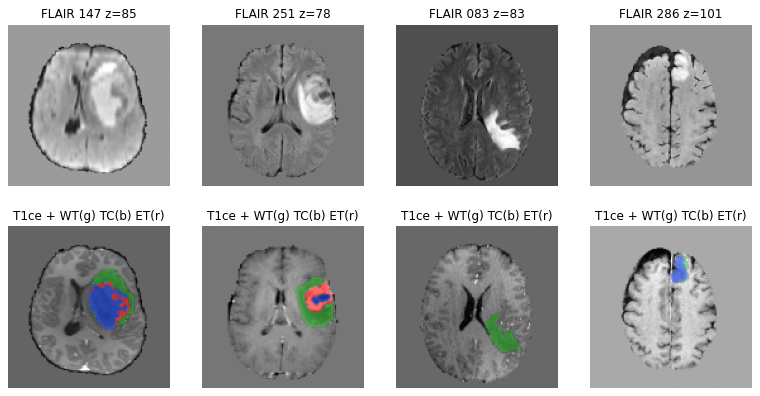

Fraction of pixels per region in cached train slices: {'WT': 0.028, 'TC': 0.0107, 'ET': 0.006}


In [11]:
# ---- sanity check: a few cached slices with their WT/TC/ET masks ----
pick = np.random.default_rng(0).choice(np.where(META.wt_px_240.values > 500)[0], 4, replace=False)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for k, j in enumerate(pick):
    x = X_MRI[j].astype(np.float32); y = Y_ALL[j]
    ax[0, k].imshow(x[FL].T, cmap="gray"); ax[0, k].set_title(f"FLAIR {META.case[j][-3:]} z={META.z[j]}")
    ax[1, k].imshow(x[T1CE].T, cmap="gray"); ax[1, k].imshow(np.transpose(label_rgba(y), (1, 0, 2)))
    ax[1, k].set_title("T1ce + WT(g) TC(b) ET(r)")
for a in ax.ravel(): a.axis("off")
show_save(fig, "p2_cached_slices")
print("Fraction of pixels per region in cached train slices:",
      {r: round(float(Y_ALL[TRAIN_IDX[:500], i].mean()), 4) for i, r in enumerate(REGIONS)})

DIP FEATURE BANK

In [20]:
from scipy import ndimage as ndi
from skimage import exposure, filters, feature as skfeature, morphology
from skimage.filters.rank import entropy as rank_entropy

def _unit(a, b):
    v = a[b > 0] if b.any() else a.ravel()
    lo, hi = np.percentile(v, [1, 99]); hi = hi if hi > lo else lo + 1e-6
    return np.clip((a - lo) / (hi - lo), 0, 1).astype(np.float32)

def _u8(a, b):
    return (_unit(a, b) * 255).astype(np.uint8)

_DISK4, _DISK5 = morphology.disk(4), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))

def f_clahe_flair(x, b):  return exposure.equalize_adapthist(_unit(x[FL], b), clip_limit=0.02).astype(np.float32) * b
def f_bilat_t1ce(x, b):   return cv2.bilateralFilter(x[T1CE].astype(np.float32), 5, 0.5, 3) * b
def f_hyper_flair(x, b):  return (1 / (1 + np.exp(-(ndi.gaussian_filter(x[FL], 1) - 1.5) / 0.3))) * b
def f_enh(x, b):          return ndi.gaussian_filter(x[T1CE] - x[T1], 1.0) * b
def f_flair_t2(x, b):     return ndi.gaussian_filter(x[FL] - x[T2], 1.0) * b
def f_asym(x, b):
    g = ndi.gaussian_filter(x[FL], 2.0)
    return (g - g[::-1, :]) * b                      # axis 0 = left-right in BraTS (SRI24 space)
def f_grad_flair(x, b):   return filters.sobel(x[FL]).astype(np.float32) * b
def f_grad_t1ce(x, b):    return filters.sobel(x[T1CE]).astype(np.float32) * b
def f_dog_flair(x, b):    return (ndi.gaussian_filter(x[FL], 1) - ndi.gaussian_filter(x[FL], 3)) * b
def f_log_t1ce(x, b):     return -ndi.gaussian_laplace(x[T1CE], 2.0) * b
def f_tophat_t1ce(x, b):  return cv2.morphologyEx(x[T1CE].astype(np.float32), cv2.MORPH_TOPHAT, _DISK5) * b
def f_entropy_t1ce(x, b): return rank_entropy(_u8(x[T1CE], b), _DISK4).astype(np.float32) * b
def f_lstd_flair(x, b):
    m = ndi.uniform_filter(x[FL], 7); m2 = ndi.uniform_filter(x[FL] ** 2, 7)
    return np.sqrt(np.maximum(m2 - m * m, 0)) * b
def f_gabor_t2(x, b):
    e = [np.hypot(*filters.gabor(x[T2], frequency=0.2, theta=t)) for t in (0, np.pi/4, np.pi/2, 3*np.pi/4)]
    return np.max(e, 0).astype(np.float32) * b
def f_lbp_t1ce(x, b):     return skfeature.local_binary_pattern(_u8(x[T1CE], b), 8, 1, "uniform").astype(np.float32) * b

FEATURES = OrderedDict([
    ("CLAHE_FLAIR", ("Contrast", f_clahe_flair)), ("BILAT_T1ce", ("Contrast", f_bilat_t1ce)),
    ("HYPER_FLAIR", ("Contrast", f_hyper_flair)), ("ENH_T1ce-T1", ("CrossModal", f_enh)),
    ("FLAIR-T2", ("CrossModal", f_flair_t2)),     ("ASYM_FLAIR", ("CrossModal", f_asym)),
    ("GRAD_FLAIR", ("Edge", f_grad_flair)),       ("GRAD_T1ce", ("Edge", f_grad_t1ce)),
    ("DoG_FLAIR", ("Edge", f_dog_flair)),         ("LoG_T1ce", ("BlobMorph", f_log_t1ce)),
    ("TOPHAT_T1ce", ("BlobMorph", f_tophat_t1ce)), ("ENTROPY_T1ce", ("Texture", f_entropy_t1ce)),
    ("LSTD_FLAIR", ("Texture", f_lstd_flair)),    ("GABOR_T2", ("Texture", f_gabor_t2)),
    ("LBP_T1ce", ("Texture", f_lbp_t1ce)),
])
FEAT_NAMES = list(FEATURES); K = len(FEAT_NAMES)
FEAT_GROUP = np.array([FEATURES[n][0] for n in FEAT_NAMES])
GROUPS = [str(g) for g in OrderedDict.fromkeys(FEAT_GROUP)]

def compute_features(x, which=None):
    """x: (4,S,S) float32 normalised slice -> (K,S,S) float32 (only indices in `which` are filled)."""
    b = np.any(x != 0, 0).astype(np.float32)
    out = np.zeros((K, S, S), np.float32)
    if b.sum() == 0:
        return out
    for k in (range(K) if which is None else which):
        out[k] = FEATURES[FEAT_NAMES[k]][1](x, b)
    return out

def compute_features_batch(xs):
    return np.stack([compute_features(x.astype(np.float32)) for x in xs]).astype(np.float16)

print(f"{K} features in groups {GROUPS}")

15 features in groups ['Contrast', 'CrossModal', 'Edge', 'BlobMorph', 'Texture']


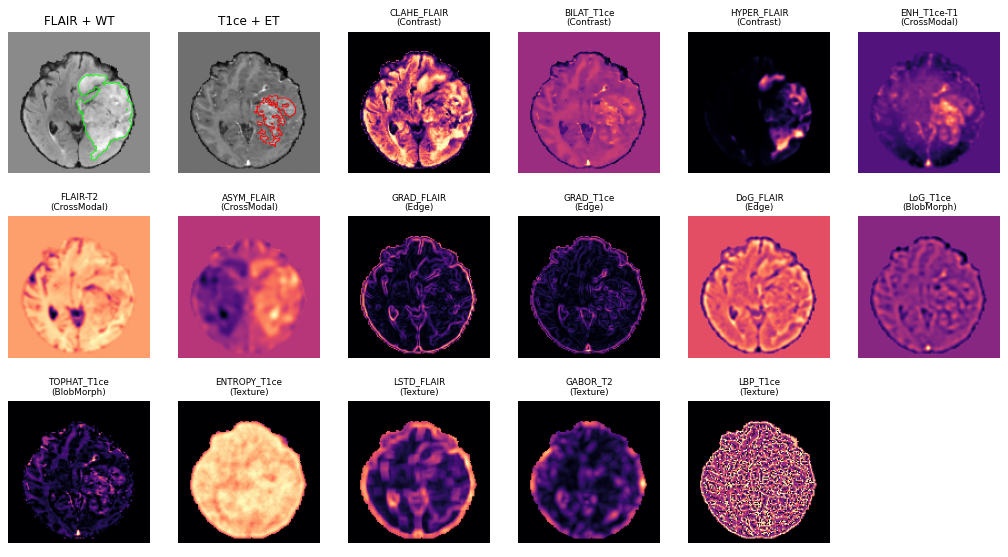

In [13]:
# ---- visualise all feature maps for one tumour slice ----
j = int(META.wt_px_240.values.argmax())
x = X_MRI[j].astype(np.float32); fm = compute_features(x)
fig, ax = plt.subplots(3, 6, figsize=(16, 8.5))
ax = ax.ravel()
ax[0].imshow(x[FL].T, cmap="gray"); ax[0].contour(Y_ALL[j, 0].T, [0.5], colors="lime", linewidths=0.8); ax[0].set_title("FLAIR + WT")
ax[1].imshow(x[T1CE].T, cmap="gray"); ax[1].contour(Y_ALL[j, 2].T, [0.5], colors="red", linewidths=0.8); ax[1].set_title("T1ce + ET")
for k in range(K):
    ax[k+2].imshow(fm[k].T, cmap="magma"); ax[k+2].set_title(f"{FEAT_NAMES[k]}\n({FEAT_GROUP[k]})", fontsize=8)
for a in ax: a.axis("off")
show_save(fig, "p3_feature_maps")

In [21]:
# ---- 1) cost: measured milliseconds per slice for each feature (single CPU thread) ----
stats_path = bring_to_work("results/feature_stats.csv")
rng = np.random.default_rng(1)
if stats_path is None:
    tim_idx = rng.choice(TRAIN_IDX, min(100, len(TRAIN_IDX)), replace=False)
    cost = np.zeros(K)
    for j in tim_idx:
        x = X_MRI[j].astype(np.float32); b = np.any(x != 0, 0).astype(np.float32)
        for k, n in enumerate(FEAT_NAMES):
            t0 = time.perf_counter(); FEATURES[n][1](x, b); cost[k] += time.perf_counter() - t0
    COST_MS = cost / len(tim_idx) * 1000
    print(pd.Series(COST_MS, FEAT_NAMES).round(2).to_string())

# ---- 2) compute ALL feature maps for all cached slices once (parallel, chunked, float16 on disk) ----
if locate("brats_cache/F_feat.npy") is None:
    N = len(META)
    Fmm = np.lib.format.open_memmap(CACHE/"F_feat.npy", mode="w+", dtype=np.float16, shape=(N, K, S, S))
    step = 512
    for s0 in range(0, N, step):
        xs = np.asarray(X_MRI[s0:s0+step])
        parts = Parallel(n_jobs=CFG["n_jobs"], backend="threading")(delayed(compute_features_batch)(xs[i:i+32]) for i in range(0, len(xs), 32))
        Fmm[s0:s0+len(xs)] = np.concatenate(parts)
        log(f"features {min(s0+step, N)}/{N}")
    Fmm.flush(); del Fmm
F_FEAT = np.load(locate("brats_cache/F_feat.npy"), mmap_mode="r")
print("feature cache:", F_FEAT.shape, f"{F_FEAT.nbytes/1e9:.2f} GB")

feature cache: (3584, 15, 128, 128) 1.76 GB


In [22]:
# ---- 3) normalisation statistics, relevance (AUC), novelty and redundancy ----
from sklearn.metrics import roc_auc_score
W_REG = np.array(CFG["region_weights"])
ALL_NAMES = [m.upper() for m in MODS] + FEAT_NAMES

if stats_path is None:
    samp = rng.choice(TRAIN_IDX, min(400, len(TRAIN_IDX)), replace=False)
    xs = np.asarray(X_MRI[samp], dtype=np.float32); fs = np.asarray(F_FEAT[samp], dtype=np.float32)
    ys = np.asarray(Y_ALL[samp])
    brain = np.any(xs != 0, 1)                                         # (n,S,S)
    allc = np.concatenate([xs, fs], 1).transpose(1, 0, 2, 3)[:, brain]  # (4+K, n_brain_px)
    lab = ys.transpose(1, 0, 2, 3)[:, brain]                           # (3, n_brain_px)
    sub = rng.choice(allc.shape[1], min(300_000, allc.shape[1]), replace=False)
    allc, lab = allc[:, sub], lab[:, sub]
    MU, SD = allc[4:].mean(1), allc[4:].std(1) + 1e-6                  # per-feature normalisation (train brain px)
    auc = np.zeros((4 + K, 3))
    for c in range(4 + K):
        for r in range(3):
            auc[c, r] = roc_auc_score(lab[r], allc[c]) if 0 < lab[r].mean() < 1 else 0.5
    sep = 2 * np.abs(auc - 0.5)
    corr = np.corrcoef(allc[:, rng.choice(allc.shape[1], min(100_000, allc.shape[1]), replace=False)])
    corr = np.nan_to_num(corr)
    relevance = sep @ W_REG
    novelty = 1 - np.abs(corr[4:, :4]).max(1)
    rel_f = relevance[4:]
    # prior = relevance x novelty bonus / cost penalty, rescaled to selection probabilities in [0.15, 0.85]
    raw = rel_f * (0.5 + 0.5 * novelty) / (1 + COST_MS / np.median(COST_MS))
    prior = 0.15 + 0.70 * (raw - raw.min()) / (raw.max() - raw.min() + 1e-12)
    FSTAT = pd.DataFrame(dict(feature=FEAT_NAMES, group=FEAT_GROUP, cost_ms=COST_MS,
                              AUC_WT=auc[4:, 0], AUC_TC=auc[4:, 1], AUC_ET=auc[4:, 2],
                              relevance=rel_f, novelty=novelty, prior=prior, mu=MU, sd=SD))
    FSTAT.to_csv(RES/"feature_stats.csv", index=False)
    pd.DataFrame(dict(channel=ALL_NAMES, AUC_WT=auc[:, 0], AUC_TC=auc[:, 1], AUC_ET=auc[:, 2], relevance=relevance)
                 ).to_csv(RES/"channel_relevance.csv", index=False)
    np.save(RES/"feature_corr.npy", corr)
    del xs, fs, ys, allc, lab; gc.collect()

FSTAT = pd.read_csv(bring_to_work("results/feature_stats.csv"))
CORR = np.load(bring_to_work("results/feature_corr.npy"))
COST_MS, PRIOR = FSTAT.cost_ms.values, FSTAT.prior.values
MU, SD = FSTAT.mu.values.astype(np.float32), FSTAT.sd.values.astype(np.float32)
print(FSTAT.drop(columns=["mu", "sd"]).round(3).to_string(index=False))
print("\nRaw-MRI reference relevance:")
print(pd.read_csv(bring_to_work("results/channel_relevance.csv")).head(4).round(3).to_string(index=False))

     feature      group  cost_ms  AUC_WT  AUC_TC  AUC_ET  relevance  novelty  prior
 CLAHE_FLAIR   Contrast    4.516   0.763   0.683   0.686      0.409    0.228  0.206
  BILAT_T1ce   Contrast    0.555   0.477   0.574   0.899      0.382    0.009  0.349
 HYPER_FLAIR   Contrast    0.442   0.958   0.910   0.924      0.855    0.304  0.793
 ENH_T1ce-T1 CrossModal    0.315   0.543   0.703   0.924      0.503    0.535  0.659
    FLAIR-T2 CrossModal    0.301   0.714   0.596   0.717      0.348    0.381  0.471
  ASYM_FLAIR CrossModal    0.407   0.928   0.883   0.902      0.804    0.458  0.850
  GRAD_FLAIR       Edge    0.755   0.576   0.539   0.579      0.128    0.631  0.240
   GRAD_T1ce       Edge    0.565   0.516   0.654   0.770      0.332    0.634  0.428
   DoG_FLAIR       Edge    0.823   0.705   0.614   0.626      0.283    0.254  0.297
    LoG_T1ce  BlobMorph    0.890   0.472   0.568   0.815      0.314    0.233  0.303
 TOPHAT_T1ce  BlobMorph    0.394   0.491   0.636   0.857      0.386    0.389

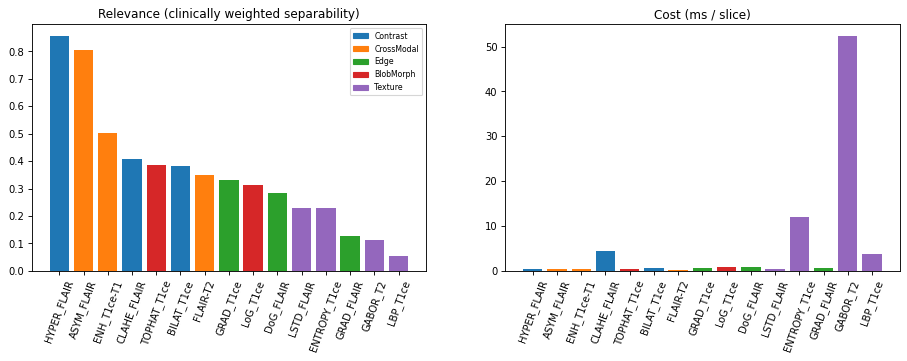

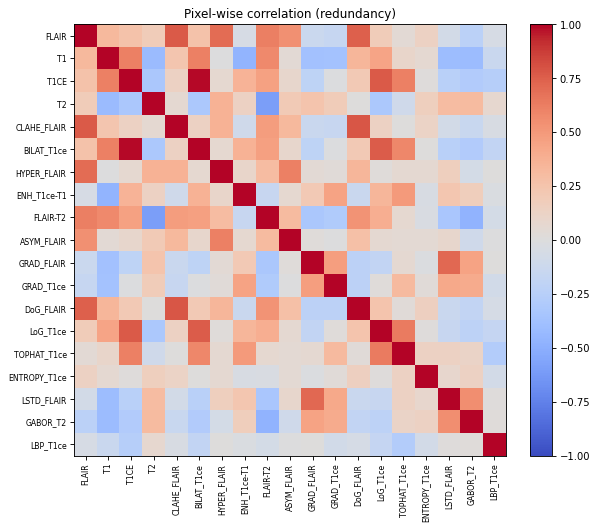

Redundant feature pairs (|r| > tau): [('CLAHE_FLAIR', 'DoG_FLAIR', 0.79), ('BILAT_T1ce', 'LoG_T1ce', 0.76), ('GRAD_FLAIR', 'LSTD_FLAIR', 0.72)]
Most correlated feature pairs: [('CLAHE_FLAIR', 'DoG_FLAIR', 0.79), ('BILAT_T1ce', 'LoG_T1ce', 0.76), ('GRAD_FLAIR', 'LSTD_FLAIR', 0.72), ('LoG_T1ce', 'TOPHAT_T1ce', 0.63), ('HYPER_FLAIR', 'ASYM_FLAIR', 0.61), ('BILAT_T1ce', 'TOPHAT_T1ce', 0.58), ('LSTD_FLAIR', 'GABOR_T2', 0.55), ('FLAIR-T2', 'DoG_FLAIR', 0.53)]
Near-copies of a raw MRI channel (excluded by R2): [('BILAT_T1ce', 'T1CE', 0.991)]


In [23]:
# ---- figures: relevance, cost, redundancy ----
colors = dict(zip(GROUPS, plt.cm.tab10.colors))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
o = np.argsort(-FSTAT.relevance.values)
ax[0].bar(np.array(FEAT_NAMES)[o], FSTAT.relevance.values[o], color=[colors[g] for g in FEAT_GROUP[o]])
ax[0].set_title("Relevance (clinically weighted separability)"); ax[0].tick_params(axis="x", rotation=70)
ax[1].bar(np.array(FEAT_NAMES)[o], COST_MS[o], color=[colors[g] for g in FEAT_GROUP[o]])
ax[1].set_title("Cost (ms / slice)"); ax[1].tick_params(axis="x", rotation=70)
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[g]) for g in GROUPS], labels=GROUPS, fontsize=7)
show_save(fig, "p3_relevance_cost")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(CORR, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(ALL_NAMES))); ax.set_xticklabels(ALL_NAMES, rotation=90, fontsize=7)
ax.set_yticks(range(len(ALL_NAMES))); ax.set_yticklabels(ALL_NAMES, fontsize=7)
plt.colorbar(im, ax=ax, fraction=0.046); ax.set_title("Pixel-wise correlation (redundancy)")
show_save(fig, "p3_correlation")

CORR_FF = CORR[4:, 4:]
REDUNDANT_PAIRS = sorted([(i, j) for i in range(K) for j in range(i+1, K) if abs(CORR_FF[i, j]) > CFG["redundancy_tau"]],
                         key=lambda p: -abs(CORR_FF[p]))
print("Redundant feature pairs (|r| > tau):", [(FEAT_NAMES[i], FEAT_NAMES[j], round(float(CORR_FF[i, j]), 2)) for i, j in REDUNDANT_PAIRS])
top = sorted([(abs(CORR_FF[i, j]), FEAT_NAMES[i], FEAT_NAMES[j]) for i in range(K) for j in range(i+1, K)], reverse=True)[:8]
print("Most correlated feature pairs:", [(a, b, round(float(r), 2)) for r, a, b in top])
CORR_FM = np.abs(CORR[4:, :4])                                   # feature vs raw MRI channel
MRI_COPIES = np.array([k for k in range(K) if CORR_FM[k].max() > CFG["mri_copy_tau"]], dtype=int)
print("Near-copies of a raw MRI channel (excluded by R2):",
      [(FEAT_NAMES[k], ALL_NAMES[int(CORR_FM[k].argmax())], round(float(CORR_FM[k].max()), 3)) for k in MRI_COPIES])

U-Net

In [24]:
# ---------------- data on device ----------------
X_T = torch.from_numpy(np.load(locate("brats_cache/X_mri.npy")))
F_T = torch.from_numpy(np.load(locate("brats_cache/F_feat.npy")))
Y_T = torch.from_numpy(np.load(locate("brats_cache/Y.npy")))
Y_NP = Y_T.numpy()
need = sum(t.numel() * t.element_size() for t in (X_T, F_T, Y_T))
DATA_DEV = torch.device("cpu")
if device.type == "cuda" and need < 0.45 * torch.cuda.mem_get_info()[1]:
    X_T, F_T, Y_T = X_T.to(device), F_T.to(device), Y_T.to(device); DATA_DEV = device
MU_T = torch.tensor(MU, device=device).view(-1, 1, 1); SD_T = torch.tensor(SD, device=device).view(-1, 1, 1)
print(f"training data: {need/1e9:.2f} GB kept on {DATA_DEV}")

def make_batch(ids, fsel, aug=False, gen=None):
    ids_t = torch.as_tensor(ids, device=DATA_DEV)
    x = X_T.index_select(0, ids_t).to(device, non_blocking=True).float()
    if len(fsel):
        fs = torch.as_tensor(fsel, device=DATA_DEV)
        f = F_T.index_select(0, ids_t).index_select(1, fs).to(device, non_blocking=True).float()
        fs_d = fs.to(device)
        f = (f - MU_T[fs_d]) / SD_T[fs_d]
        x = torch.cat([x, f], 1)
    y = Y_T.index_select(0, ids_t).to(device, non_blocking=True).float()
    if aug:                                          # flips (all DIP features are flip-equivariant)
        r = torch.rand(2, len(ids), generator=gen).to(device)
        for dim, m in ((-1, r[0] < 0.5), (-2, r[1] < 0.5)):
            x = torch.where(m.view(-1, 1, 1, 1), x.flip(dim), x)
            y = torch.where(m.view(-1, 1, 1, 1), y.flip(dim), y)
    return x, y

# ---------------- model ----------------
class DoubleConv(nn.Sequential):
    def __init__(self, i, o):
        super().__init__(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch, out_ch=3, base=16):
        super().__init__()
        ch = [base * 2**i for i in range(5)]
        self.inc = DoubleConv(in_ch, ch[0])
        self.down = nn.ModuleList([DoubleConv(ch[i], ch[i+1]) for i in range(4)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i+1], ch[i], 2, stride=2) for i in reversed(range(4))])
        self.dec = nn.ModuleList([DoubleConv(ch[i]*2, ch[i]) for i in reversed(range(4))])
        self.out = nn.Conv2d(ch[0], out_ch, 1)
    def forward(self, x):
        skips = [self.inc(x)]
        for d in self.down:
            skips.append(d(F.max_pool2d(skips[-1], 2)))
        x = skips.pop()
        for up, dec in zip(self.up, self.dec):
            x = dec(torch.cat([up(x), skips.pop()], 1))
        return self.out(x)

def dice_bce_loss(logits, y):
    bce = F.binary_cross_entropy_with_logits(logits, y)
    p = torch.sigmoid(logits)
    inter = (p * y).sum((0, 2, 3)); den = p.sum((0, 2, 3)) + y.sum((0, 2, 3))
    return bce + 1 - ((2 * inter + 1) / (den + 1)).mean()

print("U-Net parameters (4 input channels):", sum(p.numel() for p in UNet(4, 3, CFG["base_ch"]).parameters()))

training data: 2.41 GB kept on cuda
U-Net parameters (4 input channels): 1942755


In [25]:
# ---------------- metrics ----------------
HD_PEN_2D = CROP * math.sqrt(2)      # max possible 2D distance in the crop (mm)
HD_PEN_3D = 373.13                   # BraTS convention for 3D

def hd95(pred, gt, spacing, penalty):
    """95th percentile symmetric surface distance (MedPy definition). Handles empty masks."""
    ps, gs = pred.any(), gt.any()
    if not ps and not gs: return 0.0
    if not ps or not gs:  return penalty
    idx = np.argwhere(pred | gt); lo = np.maximum(idx.min(0) - 2, 0); hi = idx.max(0) + 3
    sl = tuple(slice(a, b) for a, b in zip(lo, hi))       # crop to the bounding box -> much faster, same result
    p, g = pred[sl], gt[sl]
    sp = p ^ ndi.binary_erosion(p); sg = g ^ ndi.binary_erosion(g)
    d_to_g = ndi.distance_transform_edt(~sg, sampling=spacing)
    d_to_p = ndi.distance_transform_edt(~sp, sampling=spacing)
    return float(np.percentile(np.concatenate([d_to_g[sp], d_to_p[sg]]), 95))

def dice(pred, gt):
    s = pred.sum() + gt.sum()
    return 1.0 if s == 0 else 2.0 * (pred & gt).sum() / s

def enforce_hierarchy(p):
    """ET must lie inside TC, TC inside WT."""
    p[..., 1, :, :] &= p[..., 0, :, :]; p[..., 2, :, :] &= p[..., 1, :, :]
    return p

@torch.no_grad()
def predict_ids(model, fsel, ids, bs=128):
    model.eval(); out = []
    for s in range(0, len(ids), bs):
        x, _ = make_batch(ids[s:s+bs], fsel)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            out.append((torch.sigmoid(model(x).float()) > 0.5).cpu().numpy())
    return enforce_hierarchy(np.concatenate(out))

def evaluate_slices(model, fsel, ids, with_hd=True):
    P = predict_ids(model, fsel, ids); G = Y_NP[ids].astype(bool)
    cases = META.case.values[ids]
    res = {}
    for r, name in enumerate(REGIONS):
        d = [dice(P[cases == c, r], G[cases == c, r]) for c in np.unique(cases)]   # patient-level Dice
        res[f"dice_{name}"] = float(np.mean(d))
        if with_hd:
            h = [hd95(P[i, r], G[i, r], (PX_MM, PX_MM), HD_PEN_2D) for i in range(len(ids)) if P[i, r].any() or G[i, r].any()]
            res[f"hd95_{name}"] = float(np.mean(h)) if h else 0.0
    res["CWRD"] = float(sum(W_REG[r] * res[f"dice_{n}"] for r, n in enumerate(REGIONS)))
    if with_hd:
        res["wHD95"] = float(sum(W_REG[r] * res[f"hd95_{n}"] for r, n in enumerate(REGIONS)))
    return res

# ---------------- training ----------------
def train_unet(fsel, train_ids, epochs, seed, val_ids=None, select_best=False, verbose=False):
    set_seed(seed)
    model = UNet(4 + len(fsel), 3, CFG["base_ch"]).to(device)
    bs = CFG["batch_size"]; steps = epochs * math.ceil(len(train_ids) / bs)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=steps, pct_start=0.2)
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    order_rng = np.random.default_rng(seed); aug_gen = torch.Generator().manual_seed(seed)
    hist, best, best_state = [], -1.0, None
    for ep in range(epochs):
        model.train(); perm = order_rng.permutation(train_ids); tot, nb = 0.0, 0
        for s in range(0, len(perm), bs):
            ids = perm[s:s+bs]
            if len(ids) < 2: continue
            x, y = make_batch(ids, fsel, aug=True, gen=aug_gen)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            loss = dice_bce_loss(logits.float(), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); nb += 1
        rec = dict(epoch=ep + 1, loss=tot / max(nb, 1))
        if select_best and val_ids is not None:
            m = evaluate_slices(model, fsel, val_ids, with_hd=False); rec.update(m)
            if m["CWRD"] > best:
                best = m["CWRD"]; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        hist.append(rec)
        if verbose: print({k: round(v, 4) for k, v in rec.items()})
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

# what happens if we do not resize or centre crop the images

[  16.5 min] native cache: 8/112 patients
[  16.6 min] native cache: 16/112 patients
[  16.6 min] native cache: 24/112 patients
[  16.7 min] native cache: 32/112 patients
[  16.7 min] native cache: 40/112 patients
[  16.8 min] native cache: 48/112 patients
[  16.8 min] native cache: 56/112 patients
[  16.9 min] native cache: 64/112 patients
[  16.9 min] native cache: 72/112 patients
[  16.9 min] native cache: 80/112 patients
[  17.0 min] native cache: 88/112 patients
[  17.0 min] native cache: 96/112 patients
[  17.1 min] native cache: 104/112 patients
[  17.1 min] native cache: 112/112 patients
native cache OK: X (3584, 4, 240, 240) float16, Y (3584, 3, 240, 240) | sanity check against the 128 cache passed
[  19.9 min] resized128 seed 42: CWRD 0.8379, wHD95 56.0 mm, 4.9 s/epoch, 1.2 GB, total 2.7 min
[  25.1 min] crop192 seed 42: CWRD 0.8483, wHD95 54.9 mm, 9.7 s/epoch, 1.7 GB, total 5.2 min
[  32.9 min] native240 seed 42: CWRD 0.8456, wHD95 55.0 mm, 14.5 s/epoch, 2.5 GB, total 7.7 mi

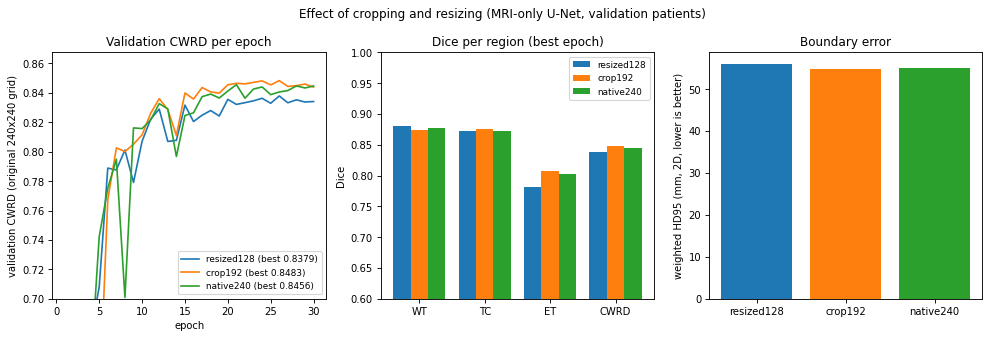

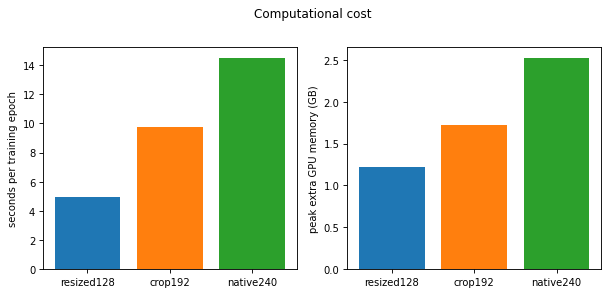

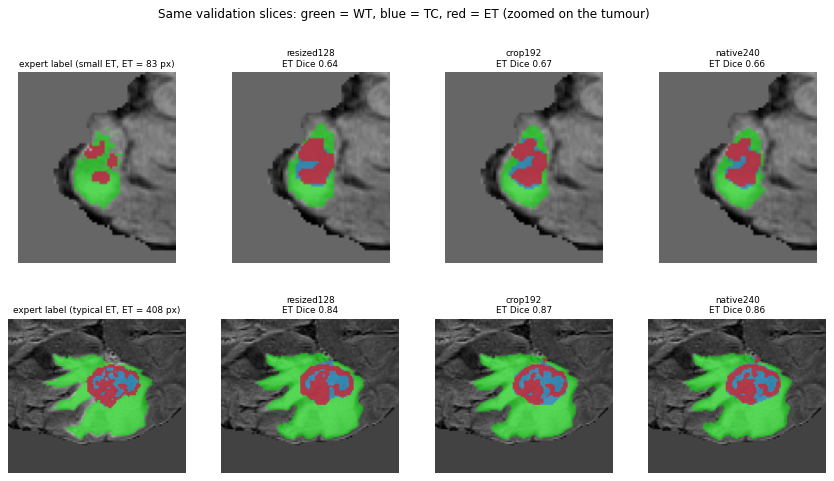

In [10]:
# =====================================================================================
# What happens if we do NOT resize / crop the image?   (paste into ONE notebook cell)
#
# Three versions of the SAME slices (same patients, same slice numbers z, same split, same seed,
# same MRI-only U-Net, same loss / optimiser / schedule / flips, 30 epochs):
#   resized128  centre-crop 192x192, resized to 128x128  (1.5 mm per pixel)  <- what the project uses
#   crop192     centre-crop 192x192, NOT resized          (1.0 mm per pixel)  <- removes only the resizing
#   native240   the original 240x240 slice, no crop, no resize (1.0 mm)       <- the original image
#
# Fair comparison: every model is scored on the ORIGINAL 240x240 grid against the ORIGINAL labels
# (the 128 model's output is up-sampled and pasted back, exactly as in the Phase 4B test evaluation).
# Only the validation patients are used (the test set is not touched).
#
# It does NOT change any existing variable (X_T, Y_T, META, ...); it creates its own tensors and
# frees them at the end.
# =====================================================================================
import math, time, gc
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

VARIANTS = ("resized128", "crop192", "native240")   # remove "crop192" to save ~5 minutes
EPOCHS   = 30                                       # same as the project
SEEDS    = (42,)                                    # add 1, 2 for mean +- SD (each extra seed ~ +15 min)
SIGMA    = float(globals().get("NOISE_SD", 0.0047)) # proxy noise measured in Phase 4

need = ["CFG", "CASES", "load_case", "zscore_normalise", "seg_to_regions", "META", "X_MRI", "Y_ALL",
        "TRAIN_IDX", "VAL_IDX", "UNet", "dice_bce_loss", "hd95", "W_REG", "REGIONS", "FL", "C0", "CROP",
        "device", "USE_AMP", "set_seed", "CACHE", "RES", "show_save", "log", "prep_slice"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run the setup cells (Phase 0-4) first. Missing: {missing}"
assert device.type == "cuda", "This experiment needs the GPU."

# ------------------------------------------------------------------
# 1) Native-resolution cache: the SAME slices as META (case, z), but no crop and no resize
# ------------------------------------------------------------------
Xp, Yp, flag = CACHE / "X_native.npy", CACHE / "Y_native.npy", CACHE / "native_done.flag"
if not (Xp.exists() and Yp.exists() and flag.exists()):
    N = len(META)
    Xm = np.lib.format.open_memmap(Xp, mode="w+", dtype=np.float16, shape=(N, 4, 240, 240))
    Ym = np.lib.format.open_memmap(Yp, mode="w+", dtype=np.uint8, shape=(N, 3, 240, 240))

    def native_case(c):
        rows = META.index[META.case == c].values
        zs = META.z.values[rows]
        img, seg = load_case(CASES[c]); x, _ = zscore_normalise(img); del img
        reg = seg_to_regions(seg)
        return (rows, np.stack([x[..., z] for z in zs]).astype(np.float16),
                np.stack([reg[..., z] for z in zs]).astype(np.uint8))

    cases = list(META.case.unique()); chunk = CFG["n_jobs"] * 2
    for i in range(0, len(cases), chunk):
        outs = Parallel(n_jobs=CFG["n_jobs"], backend="threading")(delayed(native_case)(c) for c in cases[i:i + chunk])
        for rows, X, Y in outs:
            Xm[rows] = X; Ym[rows] = Y
        log(f"native cache: {min(i + chunk, len(cases))}/{len(cases)} patients")
        del outs; gc.collect()
    Xm.flush(); Ym.flush(); del Xm, Ym
    flag.write_text("ok")

Xn_np = np.load(Xp, mmap_mode="r"); Yn_np = np.load(Yp, mmap_mode="r")
# sanity: resizing the native slice must reproduce the existing 128 cache (same slices, same normalisation)
for k in (0, len(META) // 2, len(META) - 1):
    ref = prep_slice(np.asarray(Xn_np[k], dtype=np.float32))
    assert np.allclose(ref, np.asarray(X_MRI[k], dtype=np.float32), atol=0.05), f"native cache does not match slice {k}"
print(f"native cache OK: X {Xn_np.shape} {Xn_np.dtype}, Y {Yn_np.shape} | sanity check against the 128 cache passed")

# ------------------------------------------------------------------
# 2) Data on the GPU (own tensors; the notebook's X_T / Y_T are reused for the 128 version)
# ------------------------------------------------------------------
X240 = torch.from_numpy(np.load(Xp)).to(device); Y240 = torch.from_numpy(np.load(Yp)).to(device)
X128 = torch.from_numpy(np.ascontiguousarray(X_MRI)).to(device)
Y128 = torch.from_numpy(np.ascontiguousarray(Y_ALL)).to(device)
sl = slice(C0, C0 + CROP)
DATA = {"resized128": dict(X=X128, Y=Y128, size=128, mm=CROP / 128),
        "crop192":    dict(X=X240[:, :, sl, sl], Y=Y240[:, :, sl, sl], size=CROP, mm=1.0),
        "native240":  dict(X=X240, Y=Y240, size=240, mm=1.0)}

def to_canvas(probs, name):
    """probabilities (n,3,h,w) -> boolean masks on the ORIGINAL 240x240 grid, with ET in TC in WT."""
    if name == "native240":
        m = probs > 0.5
    else:
        if name == "resized128":
            probs = F.interpolate(probs, size=(CROP, CROP), mode="bilinear", align_corners=False)
        m = torch.zeros((probs.shape[0], 3, 240, 240), dtype=torch.bool, device=probs.device)
        m[:, :, sl, sl] = probs > 0.5
    m[:, 1] &= m[:, 0]; m[:, 2] &= m[:, 1]
    return m

@torch.no_grad()
def evaluate_common(model, name, ids, keep=False):
    """Patient-level Dice per region + CWRD on the original grid (same definition as evaluate_slices)."""
    d = DATA[name]; ids_t = torch.as_tensor(ids, device=device)
    uc, inv = np.unique(META.case.values[ids], return_inverse=True)
    tp, ps, gs = (np.zeros((len(uc), 3)) for _ in range(3)); kept = []
    model.eval()
    for s in range(0, len(ids), 64):
        b = ids_t[s:s + 64]
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            p = torch.sigmoid(model(d["X"].index_select(0, b).float()).float())
        m = to_canvas(p, name); g = Y240.index_select(0, b).bool()
        np.add.at(tp, inv[s:s + 64], (m & g).sum((2, 3)).cpu().numpy())
        np.add.at(ps, inv[s:s + 64], m.sum((2, 3)).cpu().numpy())
        np.add.at(gs, inv[s:s + 64], g.sum((2, 3)).cpu().numpy())
        if keep: kept.append(m.cpu().numpy())
    den = ps + gs
    dc = np.where(den == 0, 1.0, 2 * tp / np.maximum(den, 1)).mean(0)          # mean over patients, per region
    res = {f"dice_{n}": float(dc[r]) for r, n in enumerate(REGIONS)}
    res["CWRD"] = float(sum(W_REG[r] * dc[r] for r in range(3)))
    if keep: res["masks"] = np.concatenate(kept)
    return res

# ------------------------------------------------------------------
# 3) Training (same recipe as train_unet: AdamW, OneCycle 20 % warm-up, AMP, random flips)
# ------------------------------------------------------------------
def train_variant(name, seed):
    d = DATA[name]; X, Y = d["X"], d["Y"]
    set_seed(seed); torch.cuda.synchronize()
    base_mem = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats()
    model = UNet(4, 3, CFG["base_ch"]).to(device)
    bs = CFG["batch_size"]; steps = EPOCHS * math.ceil(len(TRAIN_IDX) / bs)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=steps, pct_start=0.2)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    order = np.random.default_rng(seed); aug = torch.Generator().manual_seed(seed)
    hist, best, best_state, t_train = [], -1.0, None, 0.0
    for ep in range(EPOCHS):
        model.train(); perm = order.permutation(TRAIN_IDX); tot, nb = 0.0, 0
        torch.cuda.synchronize(); t0 = time.perf_counter()
        for s in range(0, len(perm), bs):
            ids = perm[s:s + bs]
            if len(ids) < 2: continue
            ids_t = torch.as_tensor(ids, device=device)
            x = X.index_select(0, ids_t).float(); y = Y.index_select(0, ids_t).float()
            r = torch.rand(2, len(ids), generator=aug).to(device)
            for dim, m in ((-1, r[0] < 0.5), (-2, r[1] < 0.5)):
                x = torch.where(m.view(-1, 1, 1, 1), x.flip(dim), x)
                y = torch.where(m.view(-1, 1, 1, 1), y.flip(dim), y)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            loss = dice_bce_loss(logits.float(), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); nb += 1
        torch.cuda.synchronize(); t_train += time.perf_counter() - t0
        v = evaluate_common(model, name, VAL_IDX)
        hist.append(dict(epoch=ep + 1, loss=tot / max(nb, 1), **v))
        if v["CWRD"] > best:
            best = v["CWRD"]; best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    cost = dict(sec_per_epoch=t_train / EPOCHS, peak_gpu_gb=(torch.cuda.max_memory_allocated() - base_mem) / 1e9)
    return model, pd.DataFrame(hist), cost

# slices used for the pictures (chosen from the ground truth, before any model is looked at)
G_val = np.asarray(Yn_np[VAL_IDX]).astype(bool)
et_area = G_val[:, 2].sum((1, 2)); cand = np.where(et_area >= 30)[0]; cand = cand[np.argsort(et_area[cand])]
SHOW = {"small ET": int(cand[len(cand) // 10]), "typical ET": int(cand[len(cand) // 2])}

HIST, ROWS, PSHOW = {}, [], {}
HD_PEN = 240 * math.sqrt(2)                                   # largest possible 2D distance on the 240 grid (mm)
for seed in SEEDS:
    for name in VARIANTS:
        t0 = time.time()
        model, hist, cost = train_variant(name, seed)
        fin = evaluate_common(model, name, VAL_IDX, keep=True); P = fin.pop("masks")
        hd = []
        for r in range(3):                                    # 2D HD95 per slice at 1 mm, same rule as evaluate_slices
            h = [hd95(P[i, r], G_val[i, r], (1.0, 1.0), HD_PEN) for i in range(len(P)) if P[i, r].any() or G_val[i, r].any()]
            hd.append(float(np.mean(h)) if h else 0.0)
        wHD = float(sum(W_REG[r] * hd[r] for r in range(3)))
        HIST[(name, seed)] = hist
        if seed == SEEDS[0]:
            PSHOW[name] = {k: P[j].copy() for k, j in SHOW.items()}
        ROWS.append(dict(variant=name, seed=seed, input_px=DATA[name]["size"], mm_per_px=round(DATA[name]["mm"], 2),
                         best_epoch=int(hist.epoch[hist.CWRD.idxmax()]), **fin, wHD95=wHD,
                         sec_per_epoch=cost["sec_per_epoch"], peak_gpu_gb=cost["peak_gpu_gb"]))
        log(f"{name} seed {seed}: CWRD {fin['CWRD']:.4f}, wHD95 {wHD:.1f} mm, "
            f"{cost['sec_per_epoch']:.1f} s/epoch, {cost['peak_gpu_gb']:.1f} GB, total {(time.time() - t0) / 60:.1f} min")
        del model, P; gc.collect(); torch.cuda.empty_cache()

SUMMARY_NATIVE = pd.DataFrame(ROWS); SUMMARY_NATIVE.to_csv(RES / "native_resolution_summary.csv", index=False)
print(f"\nU-Net parameters (identical for every resolution): {sum(p.numel() for p in UNet(4, 3, CFG['base_ch']).parameters()):,}")
print("\nValidation patients, scored on the ORIGINAL 240x240 grid (1 mm):")
print(SUMMARY_NATIVE.round(4).to_string(index=False))
if len(SEEDS) > 1:
    print("\nMean +- SD over seeds:")
    print(SUMMARY_NATIVE.groupby("variant")[["CWRD", "dice_ET", "wHD95", "sec_per_epoch"]].agg(["mean", "std"]).round(4).to_string())

m_ = SUMMARY_NATIVE.groupby("variant").CWRD.mean()
if "resized128" in m_ and "native240" in m_:
    dlt = m_["native240"] - m_["resized128"]
    print(f"\nCWRD  resized128 {m_['resized128']:.4f}  ->  native240 {m_['native240']:.4f}   (change {dlt:+.4f})")
    print(f"Proxy noise sigma = {SIGMA:.4f}; 2*sigma = {2 * SIGMA:.4f} -> the change is "
          + ("BEYOND the noise." if abs(dlt) > 2 * SIGMA else "WITHIN the noise (no clear difference)."))
    t_ = SUMMARY_NATIVE.groupby("variant").sec_per_epoch.mean()
    print(f"Training time per epoch: x{t_['native240'] / t_['resized128']:.1f} for native240 (pixel count is x{(240 / 128) ** 2:.1f})")

# ------------------------------------------------------------------
# 4) Figures
# ------------------------------------------------------------------
cols = {"resized128": "tab:blue", "crop192": "tab:orange", "native240": "tab:green"}
s0 = SEEDS[0]; S0 = SUMMARY_NATIVE[SUMMARY_NATIVE.seed == s0].set_index("variant")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for n in VARIANTS:
    h = HIST[(n, s0)]; ax[0].plot(h.epoch, h.CWRD, color=cols[n], label=f"{n} (best {h.CWRD.max():.4f})")
ax[0].set_ylim(0.7, None); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("validation CWRD (original 240x240 grid)")
ax[0].set_title("Validation CWRD per epoch"); ax[0].legend(fontsize=8)
w = 0.8 / len(VARIANTS)
for k, n in enumerate(VARIANTS):
    vals = [S0.loc[n, f"dice_{r}"] for r in REGIONS] + [S0.loc[n, "CWRD"]]
    ax[1].bar(np.arange(4) + k * w, vals, w, color=cols[n], label=n)
ax[1].set_xticks(np.arange(4) + w * (len(VARIANTS) - 1) / 2); ax[1].set_xticklabels(list(REGIONS) + ["CWRD"])
ax[1].set_ylim(0.6, 1.0); ax[1].set_ylabel("Dice"); ax[1].set_title("Dice per region (best epoch)"); ax[1].legend(fontsize=8)
ax[2].bar(VARIANTS, [S0.loc[n, "wHD95"] for n in VARIANTS], color=[cols[n] for n in VARIANTS])
ax[2].set_ylabel("weighted HD95 (mm, 2D, lower is better)"); ax[2].set_title("Boundary error")
fig.suptitle("Effect of cropping and resizing (MRI-only U-Net, validation patients)", y=1.02)
show_save(fig, "native_fig1_accuracy")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].bar(VARIANTS, [S0.loc[n, "sec_per_epoch"] for n in VARIANTS], color=[cols[n] for n in VARIANTS]); ax[0].set_ylabel("seconds per training epoch")
ax[1].bar(VARIANTS, [S0.loc[n, "peak_gpu_gb"] for n in VARIANTS], color=[cols[n] for n in VARIANTS]); ax[1].set_ylabel("peak extra GPU memory (GB)")
fig.suptitle("Computational cost", y=1.02); show_save(fig, "native_fig2_cost")

def overlay(flair, m):
    g = np.clip((flair - flair.min()) / (np.ptp(flair) + 1e-6), 0, 1)
    rgb = np.stack([g, g, g], -1) * 0.85
    for r, col in ((0, (0, 0.85, 0)), (1, (0.2, 0.4, 1)), (2, (1, 0, 0))):
        rgb[m[r]] = 0.4 * rgb[m[r]] + 0.6 * np.array(col)
    return rgb

fig, ax = plt.subplots(2, len(VARIANTS) + 1, figsize=(3.3 * (len(VARIANTS) + 1), 6.8))
for row, (label, j) in enumerate(SHOW.items()):
    flair = np.asarray(Xn_np[VAL_IDX[j], FL], dtype=np.float32); gt = G_val[j]
    yy, xx = np.where(gt[0]); pad = 22
    y0, y1, x0, x1 = max(yy.min() - pad, 0), min(yy.max() + pad, 240), max(xx.min() - pad, 0), min(xx.max() + pad, 240)
    z = lambda a: a[..., y0:y1, x0:x1]
    ax[row, 0].imshow(overlay(z(flair), z(gt))); ax[row, 0].set_title(f"expert label ({label}, ET = {int(gt[2].sum())} px)", fontsize=8)
    for k, n in enumerate(VARIANTS):
        pm = PSHOW[n][label]; d_et = 2 * (pm[2] & gt[2]).sum() / max(pm[2].sum() + gt[2].sum(), 1)
        ax[row, k + 1].imshow(overlay(z(flair), z(pm))); ax[row, k + 1].set_title(f"{n}\nET Dice {d_et:.2f}", fontsize=8)
for a_ in ax.ravel(): a_.axis("off")
fig.suptitle("Same validation slices: green = WT, blue = TC, red = ET (zoomed on the tumour)", y=1.0)
show_save(fig, "native_fig3_examples")

# free the GPU memory so the optimiser phases are not affected
del X240, Y240, X128, Y128, DATA; gc.collect(); torch.cuda.empty_cache()

In [26]:
# ---------------- genome evaluation with persistent cache ----------------
EVAL_CSV = RES / "eval_cache.csv"
bring_to_work("results/eval_cache.csv")
EVAL_CACHE = {}
if EVAL_CSV.exists():
    for rec in pd.read_csv(EVAL_CSV, dtype={"key": str}).to_dict("records"):
        EVAL_CACHE[rec["key"]] = rec
print("cached evaluations:", len(EVAL_CACHE))

def gkey(g):  return "".join(str(int(v)) for v in g)
def cost_of(g): return float(COST_MS[np.asarray(g, bool)].sum())
def names_of(g): return "+".join(FEAT_NAMES[i] for i in np.where(g)[0]) or "MRI-only"

def evaluate_genome(g, seed=None, tag=""):
    """Low-fidelity (proxy) evaluation of a feature subset -> objectives f1, f2, f3."""
    g = np.asarray(g, np.uint8); k = gkey(g) if seed is None else f"{gkey(g)}@s{seed}"
    if k in EVAL_CACHE:
        return EVAL_CACHE[k]
    fsel = np.where(g)[0]; t0 = time.time()
    model, _ = train_unet(fsel, TRAIN_IDX, CFG["proxy_epochs"], CFG["seed"] if seed is None else seed)
    m = evaluate_slices(model, fsel, VAL_IDX)
    rec = dict(key=k, n_feat=int(g.sum()), features=names_of(g), f1=1 - m["CWRD"], f2=m["wHD95"], f3=cost_of(g),
               **m, seconds=round(time.time() - t0, 1), tag=tag)
    EVAL_CACHE[k] = rec
    pd.DataFrame([rec]).to_csv(EVAL_CSV, mode="a", header=not EVAL_CSV.exists(), index=False)
    del model; free_memory()
    return rec

cached evaluations: 50


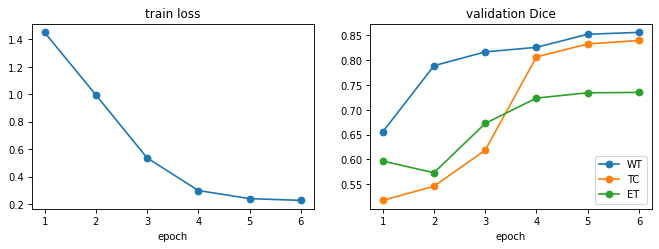

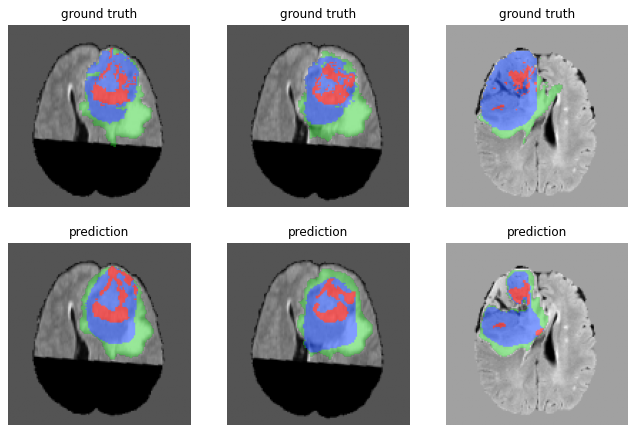

In [19]:
# ---- Demo: MRI-only U-Net with a learning curve (for the report) ----
demo_model, demo_hist = train_unet([], TRAIN_IDX, CFG["proxy_epochs"], CFG["seed"], VAL_IDX, select_best=True)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(demo_hist.epoch, demo_hist.loss, "o-"); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
for n in REGIONS: ax[1].plot(demo_hist.epoch, demo_hist[f"dice_{n}"], "o-", label=n)
ax[1].set_title("validation Dice"); ax[1].legend(); ax[1].set_xlabel("epoch")
show_save(fig, "p4_learning_curve")

ids = VAL_IDX[np.argsort(-META.wt_px_240.values[VAL_IDX])[:3]]
P = predict_ids(demo_model, [], ids)
fig, ax = plt.subplots(2, 3, figsize=(10, 6.5))
for k, j in enumerate(ids):
    x = X_MRI[j].astype(np.float32)
    for row, (lab, title) in enumerate(((Y_NP[j], "ground truth"), (P[k], "prediction"))):
        ax[row, k].imshow(x[FL].T, cmap="gray"); ax[row, k].imshow(np.transpose(label_rgba(lab), (1, 0, 2)))
        ax[row, k].set_title(title); ax[row, k].axis("off")
show_save(fig, "p4_demo_predictions")
del demo_model; free_memory()

In [27]:
# ---- Baselines + proxy-noise check ----
G_NONE, G_ALL = np.zeros(K, np.uint8), np.ones(K, np.uint8)
rows = []
for name, g in (("MRI-only", G_NONE), ("MRI+All-DIP", G_ALL)):
    for sd in (None, 1, 2):
        r = evaluate_genome(g, seed=sd, tag="baseline"); rows.append(dict(model=name, seed=sd if sd else CFG["seed"], **{k: r[k] for k in ("CWRD", "wHD95", "dice_WT", "dice_TC", "dice_ET", "f3", "seconds")}))
BASE = pd.DataFrame(rows); BASE.to_csv(RES/"p4_baselines.csv", index=False)
print(BASE.round(4).to_string(index=False))
NOISE_SD = float(BASE.groupby("model").CWRD.std().mean())
print(f"\nProxy noise (std of CWRD across seeds): {NOISE_SD:.4f}  -> differences smaller than ~2x this are not meaningful.")

sec = np.median([r["seconds"] for r in EVAL_CACHE.values() if r["seconds"] > 0])
budget = CFG["pop_size"] * (1 + CFG["n_generations"])
n_runs = 3 * len(CFG["opt_seeds"]) + (4 if CFG["run_optimizer_ablation"] else 0)
print(f"One proxy evaluation ~{sec:.0f}s. Phase 5+6 need at most ~{n_runs} runs x {budget} evals "
      f"= {n_runs*budget*sec/3600:.1f} h (the shared cache usually saves 20-40%).")

      model  seed   CWRD   wHD95  dice_WT  dice_TC  dice_ET      f3  seconds
   MRI-only    42 0.7961 51.3818   0.8560   0.8262   0.7323  0.0000     61.3
   MRI-only     1 0.8002 51.5676   0.8576   0.8366   0.7325  0.0000     23.7
   MRI-only     2 0.7985 54.0645   0.8492   0.8349   0.7349  0.0000     24.6
MRI+All-DIP    42 0.7953 50.6227   0.8552   0.8245   0.7322 78.5486     30.9
MRI+All-DIP     1 0.7891 48.3846   0.8549   0.8174   0.7232 78.5486     28.6
MRI+All-DIP     2 0.7959 53.4821   0.8598   0.8356   0.7213 78.5486     27.6

Proxy noise (std of CWRD across seeds): 0.0029  -> differences smaller than ~2x this are not meaningful.
One proxy evaluation ~27s. Phase 5+6 need at most ~7 runs x 70 evals = 3.6 h (the shared cache usually saves 20-40%).


# Training alpha*BCE +(1-alpha)*DICE for more number of epochs by gradient descnet

[  13.1 min] long_a0.50_e30_s42: done in 2.1 min, best validation CWRD 0.8309 at epoch 25
[  17.3 min] long_a0.50_e60_s42: done in 4.2 min, best validation CWRD 0.8321 at epoch 35
[  24.2 min] long_a0.50_e100_s42: done in 6.9 min, best validation CWRD 0.8419 at epoch 71
[  26.3 min] long_learned_e30_s42: done in 2.1 min, best validation CWRD 0.8230 at epoch 17
[  33.3 min] long_learned_e100_s42: done in 7.0 min, best validation CWRD 0.8358 at epoch 52
             model  schedule_epochs  seed  best_epoch  best_val_CWRD  final_epoch_val_CWRD  final_train_loss  final_alpha
fixed alpha = 0.50               30    42          25         0.8309                0.8278            0.0712       0.5000
fixed alpha = 0.50               60    42          35         0.8321                0.8281            0.0595       0.5000
fixed alpha = 0.50              100    42          71         0.8419                0.8363            0.0507       0.5000
     learned alpha               30    42          17   

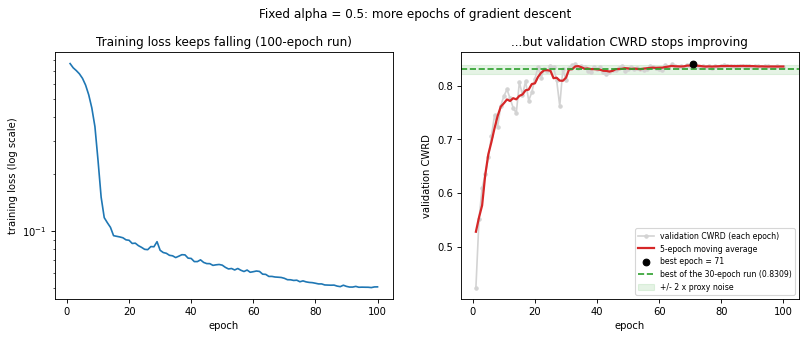

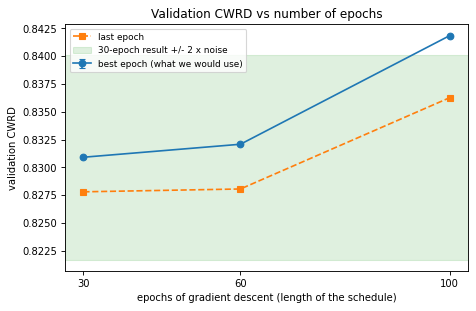

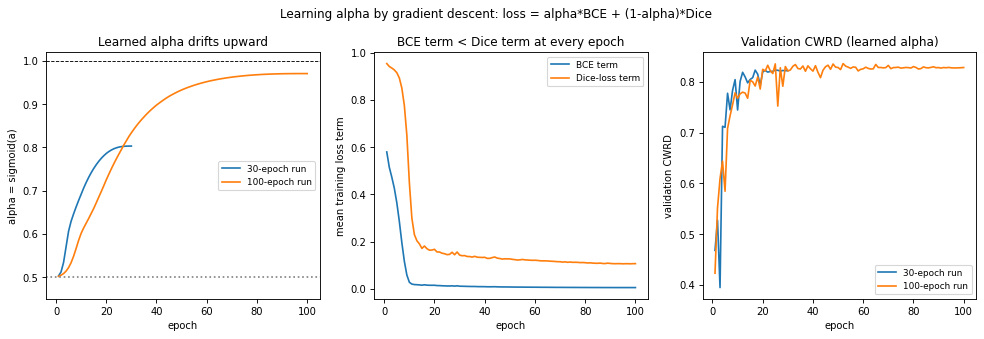

In [12]:
# =====================================================================================
# Does running gradient descent for MORE epochs help?
#

#
# Experiment 1  U-Net trained with the project loss (alpha = 0.5, i.e. BCE + Dice up to a factor 0.5)
#               for 30, 60 and 100 epochs. Question: does validation CWRD keep improving?
# Experiment 2  alpha LEARNED by gradient descent for 30 and 100 epochs.
#               Question: does alpha settle on a good value, or keep drifting?
#
# =====================================================================================
import math, time
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

# ------------------------------- settings -------------------------------
EPOCH_LIST     = (30, 60, 100)   # schedule lengths for experiment 1 (30 = what the project used)
LEARNED_EPOCHS = (30, 100)       # schedule lengths for experiment 2
SEEDS          = (42,)           # add 1, 2 for mean +- SD (each extra seed costs roughly 20 min on a T4)
ALPHA_FIXED    = 0.5             # weight in  alpha*BCE + (1-alpha)*Dice
SIGMA          = float(globals().get("NOISE_SD", 0.0047))   # proxy noise from Phase 4 (std of CWRD over seeds)

need = ["UNet", "make_batch", "evaluate_slices", "TRAIN_IDX", "VAL_IDX", "CFG", "set_seed",
        "device", "USE_AMP", "show_save", "RES", "log"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run the setup cells (Phase 0-4) first. Missing: {missing}"

if "bce_only" not in globals():
    def bce_only(logits, y):
        return F.binary_cross_entropy_with_logits(logits, y)
if "dice_only" not in globals():
    def dice_only(logits, y):
        p = torch.sigmoid(logits)
        inter = (p * y).sum((0, 2, 3)); den = p.sum((0, 2, 3)) + y.sum((0, 2, 3))
        return 1 - ((2 * inter + 1) / (den + 1)).mean()


def train_long(epochs, seed, alpha):
    """alpha = number -> fixed weight; alpha = None -> alpha = sigmoid(a) learned together with the network.
    Returns the per-epoch history (training losses, alpha, validation Dice and CWRD)."""
    tag = f"long_{'learned' if alpha is None else f'a{alpha:.2f}'}_e{epochs}_s{seed}"
    path = RES / f"{tag}.csv"
    if path.exists():
        log(f"{tag}: loaded from disk")
        return pd.read_csv(path)

    t0 = time.time()
    set_seed(seed)
    model = UNet(4, 3, CFG["base_ch"]).to(device)
    a = nn.Parameter(torch.zeros((), device=device)) if alpha is None else None      # sigmoid(0) = 0.5
    groups = [{"params": model.parameters()}]
    if a is not None:
        groups.append({"params": [a], "weight_decay": 0.0})
    bs = CFG["batch_size"]
    steps = epochs * math.ceil(len(TRAIN_IDX) / bs)
    opt = torch.optim.AdamW(groups, lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=steps, pct_start=0.2)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    order = np.random.default_rng(seed)
    aug = torch.Generator().manual_seed(seed)

    hist = []
    for ep in range(epochs):
        model.train()
        perm = order.permutation(TRAIN_IDX)
        s_loss = s_bce = s_dice = 0.0; nb = 0
        for s in range(0, len(perm), bs):
            ids = perm[s:s + bs]
            if len(ids) < 2:
                continue
            x, y = make_batch(ids, [], aug=True, gen=aug)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            b = bce_only(logits.float(), y)
            d = dice_only(logits.float(), y)
            w = torch.sigmoid(a) if a is not None else alpha
            loss = w * b + (1 - w) * d
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            s_loss += loss.item(); s_bce += b.item(); s_dice += d.item(); nb += 1
        val = evaluate_slices(model, [], VAL_IDX, with_hd=False)
        hist.append(dict(epoch=ep + 1,
                         alpha=float(torch.sigmoid(a)) if a is not None else float(alpha),
                         loss=s_loss / nb, bce=s_bce / nb, dice_loss=s_dice / nb,
                         CWRD=val["CWRD"], dice_WT=val["dice_WT"], dice_TC=val["dice_TC"], dice_ET=val["dice_ET"]))
    df = pd.DataFrame(hist)
    df["schedule_epochs"] = epochs; df["seed"] = seed; df["minutes"] = (time.time() - t0) / 60
    df.to_csv(path, index=False)
    log(f"{tag}: done in {df.minutes.iloc[0]:.1f} min, best validation CWRD {df.CWRD.max():.4f} "
        f"at epoch {int(df.epoch[df.CWRD.idxmax()])}")
    del model, opt, sched
    if "free_memory" in globals():
        free_memory()
    return df


# ------------------------------- run everything -------------------------------
RUN_FIXED = {(E, s): train_long(E, s, ALPHA_FIXED) for s in SEEDS for E in EPOCH_LIST}
RUN_LEARN = {(E, s): train_long(E, s, None) for s in SEEDS for E in LEARNED_EPOCHS}

# ------------------------------- summary table -------------------------------
rows = []
for name, runs, al in (("fixed alpha = %.2f" % ALPHA_FIXED, RUN_FIXED, ALPHA_FIXED), ("learned alpha", RUN_LEARN, None)):
    for (E, s), h in runs.items():
        i = h.CWRD.idxmax()
        rows.append(dict(model=name, schedule_epochs=E, seed=s, best_epoch=int(h.epoch[i]),
                         best_val_CWRD=float(h.CWRD[i]), final_epoch_val_CWRD=float(h.CWRD.iloc[-1]),
                         final_train_loss=float(h.loss.iloc[-1]), final_alpha=float(h.alpha.iloc[-1])))
SUMMARY = pd.DataFrame(rows)
SUMMARY.to_csv(RES / "long_training_summary.csv", index=False)
print(SUMMARY.round(4).to_string(index=False))
if len(SEEDS) > 1:
    print("\nMean +- SD over seeds:")
    print(SUMMARY.groupby(["model", "schedule_epochs"])[["best_epoch", "best_val_CWRD", "final_epoch_val_CWRD"]]
          .agg(["mean", "std"]).round(4).to_string())

# ------------------------------- automatic reading of the result -------------------------------
fx = SUMMARY[SUMMARY.model.str.startswith("fixed")]
base, longest = fx[fx.schedule_epochs == min(EPOCH_LIST)], fx[fx.schedule_epochs == max(EPOCH_LIST)]
delta = longest.best_val_CWRD.mean() - base.best_val_CWRD.mean()
print(f"\nBest validation CWRD, {min(EPOCH_LIST)} -> {max(EPOCH_LIST)} epochs: "
      f"{base.best_val_CWRD.mean():.4f} -> {longest.best_val_CWRD.mean():.4f}  (change {delta:+.4f})")
print(f"Proxy noise sigma = {SIGMA:.4f}, so changes below 2*sigma = {2 * SIGMA:.4f} are not meaningful -> "
      + ("the change is BEYOND the noise." if abs(delta) > 2 * SIGMA else "the change is WITHIN the noise (no real gain)."))
print(f"Best epoch in the {max(EPOCH_LIST)}-epoch run(s): {longest.best_epoch.tolist()} "
      f"(a best epoch well before {max(EPOCH_LIST)} means the later epochs did not help)")
lr_ = SUMMARY[SUMMARY.model == "learned alpha"]
for E in LEARNED_EPOCHS:
    print(f"Learned alpha after {E} epochs: " + ", ".join(f"{v:.3f}" for v in lr_[lr_.schedule_epochs == E].final_alpha))
hl = RUN_LEARN[(max(LEARNED_EPOCHS), SEEDS[0])]
print(f"Epochs in which the BCE term is smaller than the Dice-loss term: {(hl.bce < hl.dice_loss).mean() * 100:.0f} %  "
      "(if 100 %, d(loss)/d(alpha) = BCE - Dice is always negative and pushes alpha up)")

# ------------------------------- Figure 1: one long run -------------------------------
E_long, s0 = max(EPOCH_LIST), SEEDS[0]
h = RUN_FIXED[(E_long, s0)]; h30 = RUN_FIXED[(min(EPOCH_LIST), s0)]
smooth = h.CWRD.rolling(5, center=True, min_periods=1).mean()
ib = int(h.CWRD.idxmax())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.loss, color="tab:blue"); ax[0].set_yscale("log")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss (log scale)")
ax[0].set_title(f"Training loss keeps falling ({E_long}-epoch run)")
ax[1].plot(h.epoch, h.CWRD, color="lightgrey", marker=".", label="validation CWRD (each epoch)")
ax[1].plot(h.epoch, smooth, color="tab:red", lw=2, label="5-epoch moving average")
ax[1].scatter([h.epoch[ib]], [h.CWRD[ib]], color="black", zorder=5, label=f"best epoch = {int(h.epoch[ib])}")
b30 = h30.CWRD.max()
ax[1].axhline(b30, ls="--", color="tab:green", label=f"best of the {min(EPOCH_LIST)}-epoch run ({b30:.4f})")
ax[1].axhspan(b30 - 2 * SIGMA, b30 + 2 * SIGMA, color="tab:green", alpha=0.12, label="+/- 2 x proxy noise")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation CWRD"); ax[1].legend(fontsize=7, loc="lower right")
ax[1].set_title("...but validation CWRD stops improving")
fig.suptitle(f"Fixed alpha = {ALPHA_FIXED}: more epochs of gradient descent", y=1.02)
show_save(fig, "long_fig1_training_vs_validation")

# ------------------------------- Figure 2: schedule length vs best score -------------------------------
g = fx.groupby("schedule_epochs")
xs = sorted(EPOCH_LIST)
mb = [g.best_val_CWRD.mean()[e] for e in xs]; mf = [g.final_epoch_val_CWRD.mean()[e] for e in xs]
sb = [g.best_val_CWRD.std()[e] if len(SEEDS) > 1 else 0.0 for e in xs]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(xs, mb, yerr=sb, marker="o", capsize=3, color="tab:blue", label="best epoch (what we would use)")
ax.plot(xs, mf, marker="s", ls="--", color="tab:orange", label="last epoch")
ax.axhspan(mb[0] - 2 * SIGMA, mb[0] + 2 * SIGMA, color="tab:green", alpha=0.15, label=f"{xs[0]}-epoch result +/- 2 x noise")
ax.set_xticks(xs); ax.set_xlabel("epochs of gradient descent (length of the schedule)")
ax.set_ylabel("validation CWRD"); ax.legend(fontsize=8)
ax.set_title("Validation CWRD vs number of epochs")
show_save(fig, "long_fig2_epochs_vs_cwrd")

# ------------------------------- Figure 3: learned alpha with more epochs -------------------------------
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for E in LEARNED_EPOCHS:
    hh = RUN_LEARN[(E, s0)]
    ax[0].plot(hh.epoch, hh.alpha, label=f"{E}-epoch run")
    ax[2].plot(hh.epoch, hh.CWRD, label=f"{E}-epoch run")
ax[0].axhline(0.5, ls=":", color="grey"); ax[0].axhline(1.0, ls="--", color="black", lw=0.8)
ax[0].set_ylim(0.45, 1.02); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("alpha = sigmoid(a)")
ax[0].set_title("Learned alpha drifts upward"); ax[0].legend(fontsize=8)
ax[1].plot(hl.epoch, hl.bce, label="BCE term"); ax[1].plot(hl.epoch, hl.dice_loss, label="Dice-loss term")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean training loss term")
ax[1].set_title("BCE term < Dice term at every epoch"); ax[1].legend(fontsize=8)
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("validation CWRD"); ax[2].set_title("Validation CWRD (learned alpha)"); ax[2].legend(fontsize=8)
fig.suptitle("Learning alpha by gradient descent: loss = alpha*BCE + (1-alpha)*Dice", y=1.02)
show_save(fig, "long_fig3_learned_alpha")

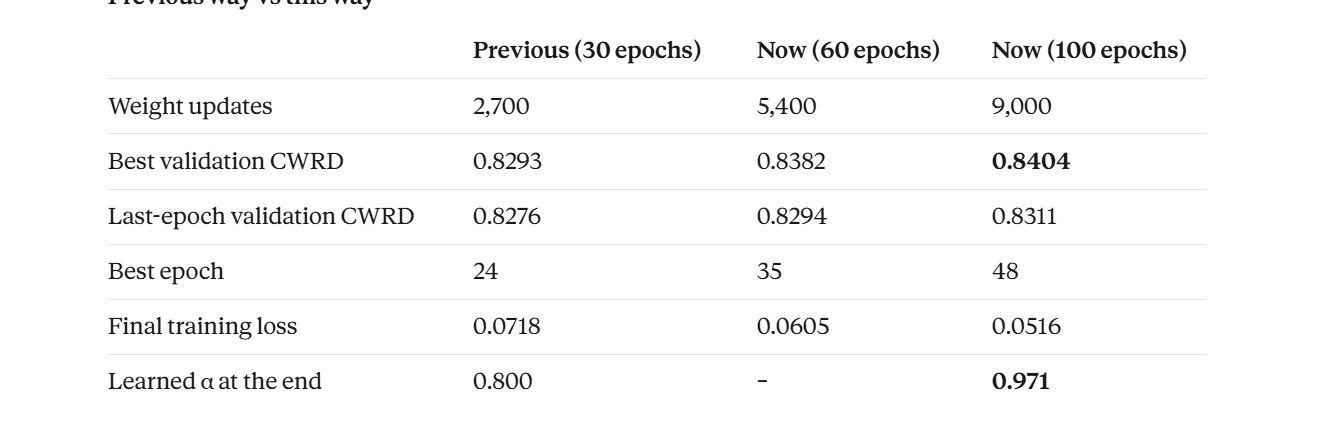

Test

[  12.1 min] Baseline trained in 2.1 min; best validation CWRD 0.8241 at epoch 21


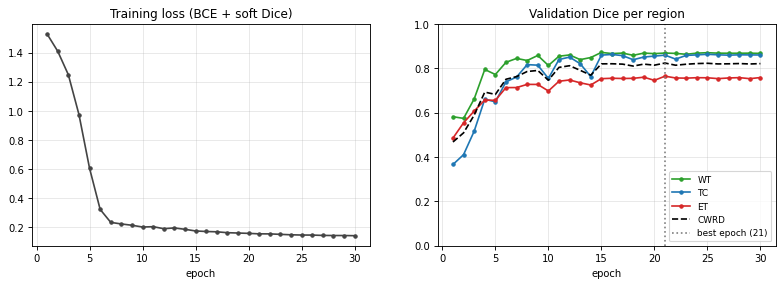

In [21]:
# ---- Phase 4B-1: fully train the MRI-only U-Net (Phase 7 re-uses this checkpoint) ----
B_NAME = "MRI-only"
BASE_MODEL = UNet(4, 3, CFG["base_ch"]).to(device)
b_ckpt = locate(f"checkpoints/{B_NAME}.pt")
if b_ckpt is not None:
    BASE_MODEL.load_state_dict(torch.load(b_ckpt, map_location=device))
    print("Loaded the trained baseline from", b_ckpt)
else:
    t0 = time.time()
    BASE_MODEL, B_HIST = train_unet([], TRAIN_IDX, CFG["final_epochs"], CFG["seed"], VAL_IDX, select_best=True)
    torch.save(BASE_MODEL.state_dict(), CKPT / f"{B_NAME}.pt")
    B_HIST.to_csv(RES / "p4b_history_MRI-only.csv", index=False)
    log(f"Baseline trained in {(time.time() - t0) / 60:.1f} min; best validation CWRD "
        f"{B_HIST.CWRD.max():.4f} at epoch {int(B_HIST.CWRD.idxmax()) + 1}")
BASE_MODEL.eval()

hp = bring_to_work("results/p4b_history_MRI-only.csv")
if hp is not None:
    h = pd.read_csv(hp); best_ep = int(h.CWRD.idxmax()) + 1
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(h.epoch, h.loss, "o-", ms=3, color="#444")
    ax[0].set_title("Training loss (BCE + soft Dice)"); ax[0].set_xlabel("epoch"); ax[0].grid(alpha=0.3)
    for n, c in zip(REGIONS, ("#2ca02c", "#1f77b4", "#d62728")):
        ax[1].plot(h.epoch, h[f"dice_{n}"], "o-", ms=3, color=c, label=n)
    ax[1].plot(h.epoch, h.CWRD, "k--", lw=1.5, label="CWRD")
    ax[1].axvline(best_ep, color="grey", ls=":", label=f"best epoch ({best_ep})")
    ax[1].set_title("Validation Dice per region"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 1)
    ax[1].legend(fontsize=8, loc="lower right"); ax[1].grid(alpha=0.3)
    show_save(fig, "p4b_learning_curves")

In [22]:
# ---- Phase 4B-2: evaluate the baseline on the held-out TEST patients, in 3D ----
VOX_ML = 1e-3                                   # one 1 mm^3 voxel = 0.001 ml

@torch.no_grad()
def predict_volume(model, cid):
    """MRI-only prediction for one patient at the original 240x240x155 resolution."""
    img, seg = load_case(CASES[cid]); x, brain = zscore_normalise(img); del img
    gt = seg_to_regions(seg).astype(bool); D = x.shape[-1]
    xs = np.stack([prep_slice(x[..., z]) for z in range(D)]).astype(np.float32)
    flair = x[FL].copy(); del x
    t0 = time.perf_counter(); probs = []
    for s in range(0, D, 64):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            probs.append(torch.sigmoid(model(torch.from_numpy(xs[s:s + 64]).to(device)).float()).cpu().numpy())
    if device.type == "cuda": torch.cuda.synchronize()
    t_inf = time.perf_counter() - t0
    probs = np.concatenate(probs); pred = np.zeros((3, 240, 240, D), bool)
    for z in range(D):
        if probs[z].max() < 0.5: continue
        up = np.stack([cv2.resize(probs[z, r], (CROP, CROP), interpolation=cv2.INTER_LINEAR) for r in range(3)]) > 0.5
        pred[:, C0:C0 + CROP, C0:C0 + CROP, z] = up
    pred[1] &= pred[0]; pred[2] &= pred[1]      # ET inside TC inside WT
    return pred, gt, brain, flair, t_inf

def region_metrics(p, g, brain):
    tp = int((p & g).sum()); fp = int((p & ~g).sum()); fn = int((~p & g).sum())
    tn_b = int((brain & ~p & ~g).sum()); fp_b = int((brain & p & ~g).sum())
    nan = float("nan"); both_empty = tp + fp + fn == 0
    return dict(dice=1.0 if both_empty else 2 * tp / (2 * tp + fp + fn),
                iou=1.0 if both_empty else tp / (tp + fp + fn),
                sens=tp / (tp + fn) if tp + fn else nan,      # undefined when the patient has no such region
                prec=tp / (tp + fp) if tp + fp else nan,      # undefined when nothing was predicted
                spec=tn_b / (tn_b + fp_b) if tn_b + fp_b else nan,
                acc=1 - (fp + fn) / p.size,
                hd95=hd95(p, g, (1, 1, 1), HD_PEN_3D),
                vol_gt=g.sum() * VOX_ML, vol_pred=p.sum() * VOX_ML)

B_CSV = RES / "p4b_test_metrics.csv"; bring_to_work("results/p4b_test_metrics.csv")
SNAP_DIR = WORK / "snapshots"; SNAP_DIR.mkdir(exist_ok=True)
test_ids_b = SPLIT["test"][: CFG["n_test_eval"]] if CFG["n_test_eval"] else SPLIT["test"]
done = pd.read_csv(B_CSV) if B_CSV.exists() else pd.DataFrame(columns=["case"])
for i, cid in enumerate(test_ids_b):
    if cid in set(done.case) and (SNAP_DIR / f"{cid}.npz").exists():
        continue
    pred, gt, brain, flair, t_inf = predict_volume(BASE_MODEL, cid)
    rec = dict(case=cid, infer_s=t_inf)
    for r, rn in enumerate(REGIONS):
        for k, v in region_metrics(pred[r], gt[r], brain).items():
            rec[f"{k}_{rn}"] = v
    rec["CWRD"] = sum(W_REG[r] * rec[f"dice_{rn}"] for r, rn in enumerate(REGIONS))
    z = int(gt[0].sum((0, 1)).argmax())                       # slice with the largest tumour, for the figures
    sl = (slice(None), slice(C0, C0 + CROP), slice(C0, C0 + CROP), z)
    np.savez_compressed(SNAP_DIR / f"{cid}.npz", flair=flair[C0:C0 + CROP, C0:C0 + CROP, z].astype(np.float16),
                        gt=gt[sl], pred=pred[sl], z=z)
    done = pd.concat([done[done.case != cid], pd.DataFrame([rec])], ignore_index=True)
    done.to_csv(B_CSV, index=False)
    del pred, gt, brain, flair; gc.collect()
    if (i + 1) % 5 == 0 or i + 1 == len(test_ids_b):
        log(f"baseline test: {i + 1}/{len(test_ids_b)} patients")
BT = pd.read_csv(B_CSV); BT = BT[BT.case.isin(test_ids_b)].reset_index(drop=True)
print(f"{len(BT)} unseen test patients evaluated in 3D | mean inference time {BT.infer_s.mean():.2f} s/patient")

[  12.7 min] baseline test: 5/38 patients
[  13.0 min] baseline test: 10/38 patients
[  13.3 min] baseline test: 15/38 patients
[  13.6 min] baseline test: 20/38 patients
[  13.9 min] baseline test: 25/38 patients
[  14.2 min] baseline test: 30/38 patients
[  14.5 min] baseline test: 35/38 patients
[  14.7 min] baseline test: 38/38 patients
38 unseen test patients evaluated in 3D | mean inference time 0.10 s/patient


In [23]:
# ---- Phase 4B-3: the results table (mean ± SD over test patients; medians for the skewed metrics) ----
METRICS = [("dice", "Dice"), ("iou", "IoU (Jaccard)"), ("sens", "Sensitivity"), ("prec", "Precision"),
           ("spec", "Specificity (brain)"), ("acc", "Voxel accuracy"), ("hd95", "HD95 (mm)")]
rows = {}
for k, label in METRICS:
    fmt = "{:.1f} ± {:.1f}" if k == "hd95" else "{:.3f} ± {:.3f}"
    rows[label] = {rn: fmt.format(BT[f"{k}_{rn}"].mean(), BT[f"{k}_{rn}"].std()) for rn in REGIONS}
rows["Dice (median)"] = {rn: f"{BT[f'dice_{rn}'].median():.3f}" for rn in REGIONS}
rows["HD95 (median, mm)"] = {rn: f"{BT[f'hd95_{rn}'].median():.1f}" for rn in REGIONS}
rows["True volume (median, ml)"] = {rn: f"{BT[f'vol_gt_{rn}'].median():.1f}" for rn in REGIONS}
rows["Predicted volume (median, ml)"] = {rn: f"{BT[f'vol_pred_{rn}'].median():.1f}" for rn in REGIONS}
TAB4B = pd.DataFrame(rows).T
print(f"MRI-only U-Net on {len(BT)} unseen test patients (3D, 1 mm)")
print(TAB4B.to_string())
print(f"\nClinically-Weighted Region Dice (CWRD): {BT.CWRD.mean():.3f} ± {BT.CWRD.std():.3f}")
no_et = int((BT.vol_gt_ET == 0).sum())
if no_et:
    print(f"Note: {no_et} test patient(s) have no enhancing tumour; their ET sensitivity is undefined and left out of its mean.")
TAB4B.to_csv(RES / "p4b_summary_table.csv")
try:
    TAB4B.to_latex(RES / "tab_baseline_test.tex")
except Exception as e:
    print("LaTeX export skipped:", e)

MRI-only U-Net on 38 unseen test patients (3D, 1 mm)
                                          WT             TC             ET
Dice                           0.891 ± 0.060  0.772 ± 0.227  0.749 ± 0.226
IoU (Jaccard)                  0.808 ± 0.093  0.673 ± 0.248  0.638 ± 0.226
Sensitivity                    0.889 ± 0.089  0.774 ± 0.244  0.809 ± 0.158
Precision                      0.900 ± 0.068  0.838 ± 0.177  0.744 ± 0.242
Specificity (brain)            0.994 ± 0.004  0.997 ± 0.005  0.997 ± 0.003
Voxel accuracy                 0.998 ± 0.001  0.999 ± 0.002  0.999 ± 0.001
HD95 (mm)                        12.8 ± 21.3    10.3 ± 15.0    26.7 ± 84.1
Dice (median)                          0.902          0.864          0.833
HD95 (median, mm)                        3.8            5.3            2.4
True volume (median, ml)                85.0           28.1           14.9
Predicted volume (median, ml)           86.7           24.3           15.4

Clinically-Weighted Region Dice (CWRD): 0.792 

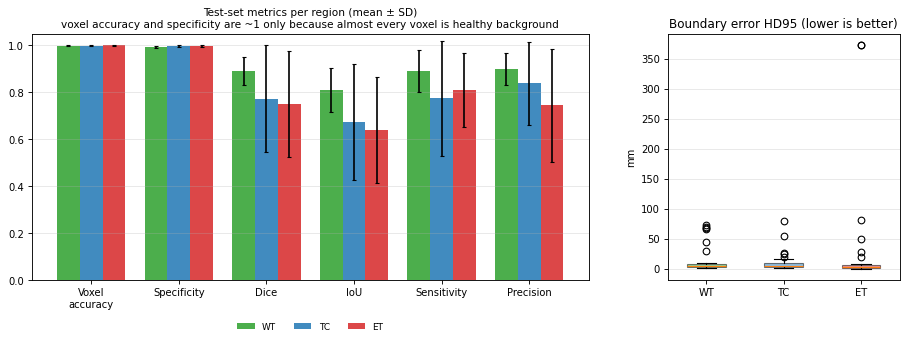

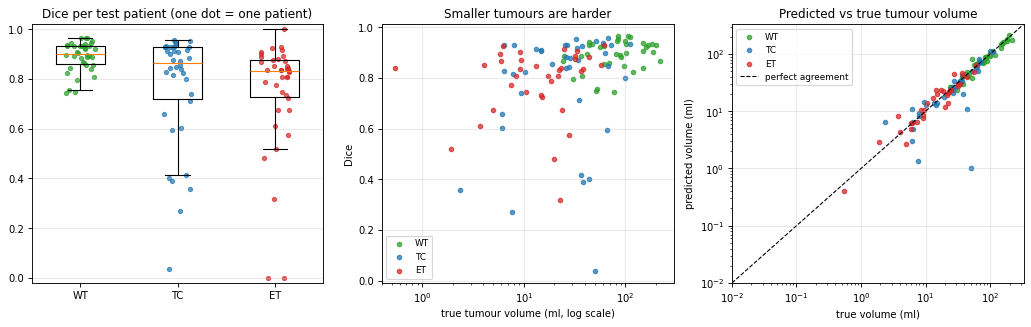

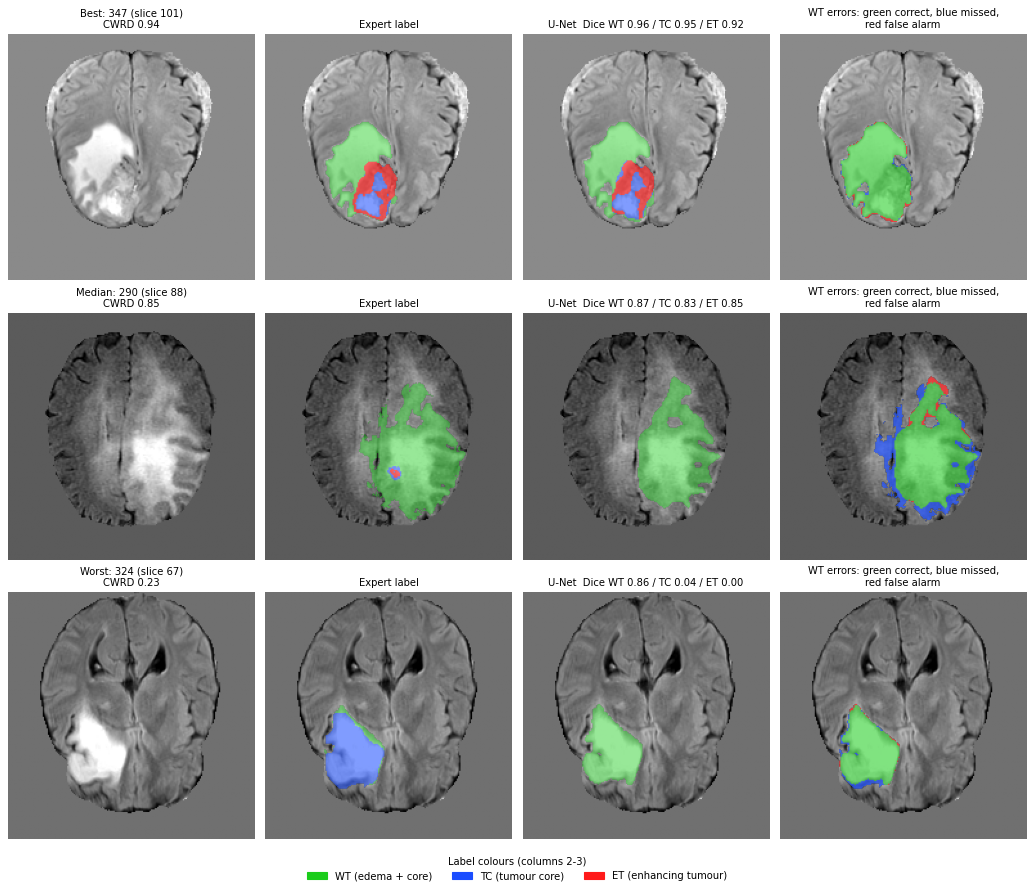

In [24]:
# ---- Phase 4B-4: figures for the presentation ----
RCOL = {"WT": "#2ca02c", "TC": "#1f77b4", "ET": "#d62728"}
rng_j = np.random.default_rng(0)

# (1) all metrics at a glance; voxel accuracy is included on purpose (accuracy paradox)
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw=dict(width_ratios=[2.4, 1]))
groups = [("acc", "Voxel\naccuracy"), ("spec", "Specificity"), ("dice", "Dice"), ("iou", "IoU"),
          ("sens", "Sensitivity"), ("prec", "Precision")]
xg = np.arange(len(groups)); bw = 0.26
for j, rn in enumerate(REGIONS):
    m = [BT[f"{k}_{rn}"].mean() for k, _ in groups]; s = [BT[f"{k}_{rn}"].std() for k, _ in groups]
    ax[0].bar(xg + (j - 1) * bw, m, bw, yerr=s, capsize=2, color=RCOL[rn], label=rn, alpha=0.85)
ax[0].set_xticks(xg); ax[0].set_xticklabels([g for _, g in groups]); ax[0].set_ylim(0, 1.05)
ax[0].set_title("Test-set metrics per region (mean ± SD)\nvoxel accuracy and specificity are ~1 only because almost every voxel is healthy background",
                fontsize=9.5)
ax[0].legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False); ax[0].grid(axis="y", alpha=0.3)
bp = ax[1].boxplot([BT[f"hd95_{rn}"] for rn in REGIONS], patch_artist=True, widths=0.5)
for patch, rn in zip(bp["boxes"], REGIONS): patch.set_facecolor(RCOL[rn]); patch.set_alpha(0.5)
ax[1].set_xticks([1, 2, 3]); ax[1].set_xticklabels(REGIONS); ax[1].set_ylabel("mm")
ax[1].set_title("Boundary error HD95 (lower is better)"); ax[1].grid(axis="y", alpha=0.3)
show_save(fig, "p4b_metrics_overview")

# (2) per-patient spread of Dice, (3) Dice vs tumour size, (4) predicted vs true volume
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for j, rn in enumerate(REGIONS):
    v = BT[f"dice_{rn}"].values
    ax[0].boxplot(v, positions=[j + 1], widths=0.5, showfliers=False)
    ax[0].scatter(j + 1 + rng_j.uniform(-0.15, 0.15, len(v)), v, s=14, color=RCOL[rn], alpha=0.7)
ax[0].set_xticks([1, 2, 3]); ax[0].set_xticklabels(REGIONS); ax[0].set_ylim(-0.02, 1.02)
ax[0].set_title("Dice per test patient (one dot = one patient)"); ax[0].grid(axis="y", alpha=0.3)
for rn in REGIONS:
    ok = BT[f"vol_gt_{rn}"] > 0
    ax[1].scatter(BT.loc[ok, f"vol_gt_{rn}"], BT.loc[ok, f"dice_{rn}"], s=16, color=RCOL[rn], label=rn, alpha=0.75)
    ax[2].scatter(BT.loc[ok, f"vol_gt_{rn}"], BT.loc[ok, f"vol_pred_{rn}"].clip(lower=0.01), s=16, color=RCOL[rn], label=rn, alpha=0.75)
ax[1].set_xscale("log"); ax[1].set_xlabel("true tumour volume (ml, log scale)"); ax[1].set_ylabel("Dice")
ax[1].set_title("Smaller tumours are harder"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
vols = BT[[f"vol_{t}_{r}" for t in ("gt", "pred") for r in REGIONS]].values.ravel()
lim = [max(0.01, 0.5 * vols[vols > 0].min()), 1.5 * vols.max()]
ax[2].plot(lim, lim, "k--", lw=1, label="perfect agreement")
ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_xlim(lim); ax[2].set_ylim(lim)
ax[2].set_xlabel("true volume (ml)"); ax[2].set_ylabel("predicted volume (ml)")
ax[2].set_title("Predicted vs true tumour volume"); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)
show_save(fig, "p4b_per_patient")

# (5) best / median / worst patient: ground truth, prediction and an error map
def overlay(a, base, lab, title):
    a.imshow(np.rot90(base), cmap="gray"); a.imshow(np.rot90(label_rgba(lab), axes=(0, 1)))
    a.set_title(title, fontsize=9); a.axis("off")

def error_rgba(p, g):
    o = np.zeros(p.shape + (4,))
    o[p & g] = (0.1, 0.8, 0.1, 0.55); o[p & ~g] = (1.0, 0.1, 0.1, 0.7); o[~p & g] = (0.1, 0.3, 1.0, 0.7)
    return o

order = BT.sort_values("CWRD").case.tolist()
picks = [("Best", order[-1]), ("Median", order[len(order) // 2]), ("Worst", order[0])]
fig, ax = plt.subplots(len(picks), 4, figsize=(13, 3.7 * len(picks)))
ax = np.atleast_2d(ax)
for row, (tag, cid) in enumerate(picks):
    s = np.load(SNAP_DIR / f"{cid}.npz"); fl = s["flair"].astype(np.float32); r = BT[BT.case == cid].iloc[0]
    ax[row, 0].imshow(np.rot90(fl), cmap="gray"); ax[row, 0].axis("off")
    ax[row, 0].set_title(f"{tag}: {cid[-3:]} (slice {int(s['z'])})\nCWRD {r.CWRD:.2f}", fontsize=9)
    overlay(ax[row, 1], fl, s["gt"], "Expert label")
    overlay(ax[row, 2], fl, s["pred"], f"U-Net  Dice WT {r.dice_WT:.2f} / TC {r.dice_TC:.2f} / ET {r.dice_ET:.2f}")
    ax[row, 3].imshow(np.rot90(fl), cmap="gray"); ax[row, 3].imshow(np.rot90(error_rgba(s["pred"][0], s["gt"][0]), axes=(0, 1)))
    ax[row, 3].set_title("WT errors: green correct, blue missed,\nred false alarm", fontsize=9); ax[row, 3].axis("off")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ((0.1, 0.8, 0.1), (0.1, 0.3, 1.0), (1.0, 0.1, 0.1))],
           labels=["WT (edema + core)", "TC (tumour core)", "ET (enhancing tumour)"],
           loc="lower center", ncol=3, fontsize=9, frameon=False, title="Label colours (columns 2-3)")
fig.tight_layout(rect=(0, 0.03, 1, 1))
show_save(fig, "p4b_qualitative")

In [25]:
# ---- Phase 4B-5: observations written out from the numbers (check them, then use them in your report) ----
from scipy.stats import spearmanr
md = {rn: BT[f"dice_{rn}"].mean() for rn in REGIONS}
obs = [f"On {len(BT)} unseen test patients (3D, original resolution) the MRI-only U-Net reaches mean Dice "
       f"WT {md['WT']:.3f}, TC {md['TC']:.3f}, ET {md['ET']:.3f} (CWRD {BT.CWRD.mean():.3f})."]
hardest = min(md, key=md.get)
obs.append(f"The hardest region is {hardest} (Dice {md[hardest]:.3f}); "
           f"{int((BT[f'dice_{hardest}'] < 0.5).sum())} of {len(BT)} patients score below 0.5 on it.")
obs.append(f"Voxel accuracy is {100 * BT.acc_WT.mean():.2f} % for WT although WT Dice is only {md['WT']:.3f}: "
           f"over 98 % of voxels are background, so accuracy rewards predicting 'no tumour' and is not a useful metric here.")
for rn in REGIONS:
    se, pr = BT[f"sens_{rn}"].mean(), BT[f"prec_{rn}"].mean()
    bias = (BT[f"vol_pred_{rn}"] - BT[f"vol_gt_{rn}"]).median()
    kind = "misses tumour (under-segments)" if bias < 0 else "over-segments (false alarms)"
    pr_txt = "n/a (nothing predicted)" if np.isnan(pr) else f"{pr:.3f}"
    obs.append(f"{rn}: sensitivity {se:.3f}, precision {pr_txt}, median volume error {bias:+.1f} ml "
               f"-> the model mainly {kind}.")
for rn in REGIONS:
    ok = BT[f"vol_gt_{rn}"] > 0
    if ok.sum() >= 5:
        rho, p = spearmanr(BT.loc[ok, f"vol_gt_{rn}"], BT.loc[ok, f"dice_{rn}"])
        obs.append(f"{rn}: Spearman correlation between tumour volume and Dice = {rho:.2f} (p = {p:.3f}); "
                   + ("larger tumours are segmented better." if rho > 0 and p < 0.05 else "no clear size effect."))
skew = [rn for rn in REGIONS if BT[f"hd95_{rn}"].mean() > 1.5 * BT[f"hd95_{rn}"].median()]
obs.append(f"HD95 medians are WT {BT.hd95_WT.median():.1f}, TC {BT.hd95_TC.median():.1f}, ET {BT.hd95_ET.median():.1f} mm "
           f"(means {BT.hd95_WT.mean():.1f}, {BT.hd95_TC.mean():.1f}, {BT.hd95_ET.mean():.1f} mm)"
           + (f"; for {', '.join(skew)} the mean is pulled up by a few failed patients, so report the median too."
              if skew else "; means and medians agree, so there are no extreme failures."))
obs.append(f"Inference takes {BT.infer_s.mean():.2f} s per patient on the GPU for all 155 slices.")
print("OBSERVATIONS\n" + "\n".join(f"{i + 1}. {o}" for i, o in enumerate(obs)))
open(RES / "p4b_observations.txt", "w").write("\n".join(obs))

OBSERVATIONS
1. On 38 unseen test patients (3D, original resolution) the MRI-only U-Net reaches mean Dice WT 0.891, TC 0.772, ET 0.749 (CWRD 0.792).
2. The hardest region is ET (Dice 0.749); 4 of 38 patients score below 0.5 on it.
3. Voxel accuracy is 99.79 % for WT although WT Dice is only 0.891: over 98 % of voxels are background, so accuracy rewards predicting 'no tumour' and is not a useful metric here.
4. WT: sensitivity 0.889, precision 0.900, median volume error +1.0 ml -> the model mainly over-segments (false alarms).
5. TC: sensitivity 0.774, precision 0.838, median volume error -0.9 ml -> the model mainly misses tumour (under-segments).
6. ET: sensitivity 0.809, precision 0.744, median volume error +0.0 ml -> the model mainly over-segments (false alarms).
7. WT: Spearman correlation between tumour volume and Dice = 0.30 (p = 0.069); no clear size effect.
8. TC: Spearman correlation between tumour volume and Dice = 0.24 (p = 0.139); no clear size effect.
9. ET: Spearman correl

1265

Checkpoint file: /kaggle/working/checkpoints/MRI-only.pt  (7.82 MB)
Learnable values: 1,942,755   |   BatchNorm running statistics: 2,944

          layer             shape  values    mean    std     min     max  rel_change
   inc.0.weight    16 × 4 × 3 × 3     576 -0.0075 0.1315 -0.4851  0.3403      0.7275
   inc.1.weight                16      16  1.0055 0.0682  0.8778  1.0955      0.0663
     inc.1.bias                16      16  0.0465 0.1277 -0.2253  0.2640         NaN
   inc.3.weight   16 × 16 × 3 × 3    2304 -0.0256 0.0870 -0.3651  0.2870      1.5740
   inc.4.weight                16      16  0.9722 0.0844  0.8086  1.0978      0.0863
     inc.4.bias                16      16 -0.0045 0.0933 -0.1547  0.1518         NaN
down.0.0.weight   32 × 16 × 3 × 3    4608 -0.0056 0.0900 -0.3909  0.3103      1.5272
down.0.1.weight                32      32  1.0029 0.0779  0.7958  1.1292      0.0767
  down.0.1.bias                32      32 -0.0495 0.0740 -0.2333  0.0951         NaN
down.0.3.we

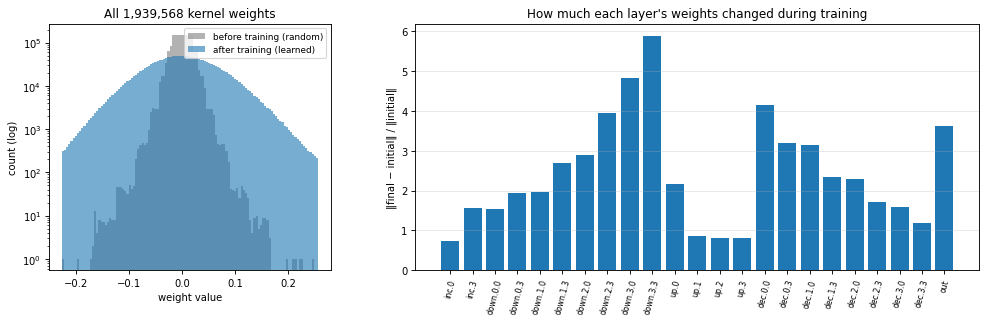

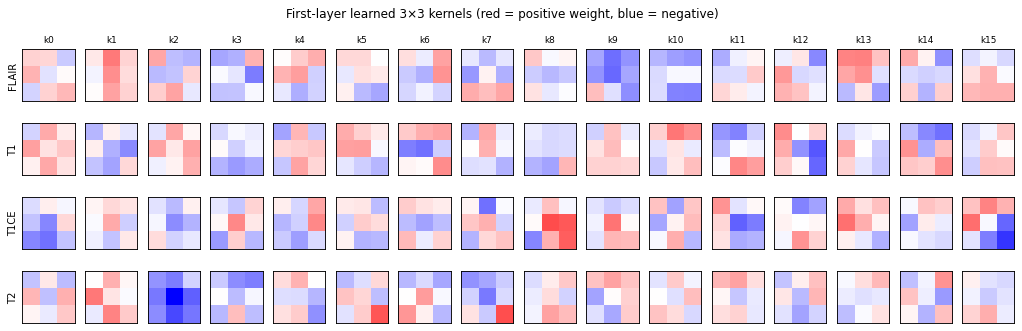

Example: kernel k0 applied to FLAIR =
 [[ 0.087  0.077 -0.101]
 [ 0.142 -0.056  0.01 ]
 [-0.083  0.087  0.135]]


In [26]:
# ---- Inspect the FINAL learned weights of the baseline U-Net (run after Phase 4B-1) ----
ck = locate("checkpoints/MRI-only.pt")
final = torch.load(ck, map_location="cpu")                       # dict: layer name -> tensor of numbers
set_seed(CFG["seed"]); init = UNet(4, 3, CFG["base_ch"]).state_dict()   # the exact starting weights train_unet used
print(f"Checkpoint file: {ck}  ({os.path.getsize(ck) / 1e6:.2f} MB)")

rows = []
for name, t in final.items():
    if not t.dtype.is_floating_point:
        continue                                                 # skips BatchNorm's batch counter
    t = t.float(); t0 = init[name].float()
    kind = ("BatchNorm running statistic (not learned by gradients)" if "running" in name else
            "BatchNorm scale γ" if name.endswith("weight") and t.dim() == 1 else
            "BatchNorm shift β / bias" if t.dim() == 1 else
            f"kernel weights {t.shape[-2]}×{t.shape[-1]}")
    rows.append(dict(layer=name, kind=kind, shape=" × ".join(map(str, t.shape)), values=t.numel(),
                     mean=t.mean().item(), std=t.std().item() if t.numel() > 1 else 0.0,
                     min=t.min().item(), max=t.max().item(),
                     rel_change=((t - t0).norm() / t0.norm()).item() if t0.norm() > 0 else float("nan")))   # undefined when it started at 0
WS = pd.DataFrame(rows); learn = ~WS.kind.str.startswith("BatchNorm running")
print(f"Learnable values: {WS[learn]['values'].sum():,}   |   BatchNorm running statistics: {WS[~learn]['values'].sum():,}\n")
pd.set_option("display.width", 220)
print(WS[learn].drop(columns="kind").round(4).to_string(index=False))
WS.to_csv(RES / "p4b_weight_summary.csv", index=False)

# figure 1: weight values before vs after training, and how much each layer changed
kw = WS[WS.kind.str.startswith("kernel")]
w_init = torch.cat([init[n].float().ravel() for n in kw.layer]).numpy()
w_fin = torch.cat([final[n].float().ravel() for n in kw.layer]).numpy()
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw=dict(width_ratios=[1, 2]))
bins = np.linspace(np.percentile(w_fin, 0.1), np.percentile(w_fin, 99.9), 120)
ax[0].hist(w_init, bins=bins, alpha=0.6, label="before training (random)", color="grey")
ax[0].hist(w_fin, bins=bins, alpha=0.6, label="after training (learned)", color="#1f77b4")
ax[0].set_yscale("log"); ax[0].set_xlabel("weight value"); ax[0].set_ylabel("count (log)")
ax[0].set_title(f"All {len(w_fin):,} kernel weights"); ax[0].legend(fontsize=8)
short = [n.replace(".weight", "") for n in kw.layer]
ax[1].bar(range(len(kw)), kw.rel_change, color="#1f77b4")
ax[1].set_xticks(range(len(kw))); ax[1].set_xticklabels(short, rotation=75, fontsize=7)
ax[1].set_ylabel("‖final − initial‖ / ‖initial‖"); ax[1].set_title("How much each layer's weights changed during training")
ax[1].grid(axis="y", alpha=0.3)
show_save(fig, "p4b_weights_change")

# figure 2: the 16 learned 3×3 kernels of the first layer, one row per MRI sequence
w1 = final["inc.0.weight"].float().numpy(); lim = np.abs(w1).max()
fig, ax = plt.subplots(4, 16, figsize=(16, 4.6))
for o in range(16):
    for c in range(4):
        ax[c, o].imshow(w1[o, c], cmap="bwr", vmin=-lim, vmax=lim); ax[c, o].set_xticks([]); ax[c, o].set_yticks([])
    ax[0, o].set_title(f"k{o}", fontsize=8)
for c, m in enumerate(MODS):
    ax[c, 0].set_ylabel(m.upper(), fontsize=9)
fig.suptitle("First-layer learned 3×3 kernels (red = positive weight, blue = negative)")
show_save(fig, "p4b_first_layer_kernels")
print("Example: kernel k0 applied to FLAIR =\n", w1[0, 0].round(3))

In [27]:

#  the three losses and training the three U-Nets 
def bce_only(logits, y):
    return F.binary_cross_entropy_with_logits(logits, y)

def dice_only(logits, y):
    p = torch.sigmoid(logits)
    inter = (p * y).sum((0, 2, 3))                  # one value per region (WT, TC, ET)
    den = p.sum((0, 2, 3)) + y.sum((0, 2, 3))
    return 1 - ((2 * inter + 1) / (den + 1)).mean()

def bce_plus_dice(logits, y):
    return bce_only(logits, y) + dice_only(logits, y)

LOSSES = {"BCE": bce_only, "Dice": dice_only, "BCE + Dice": bce_plus_dice}
FILE_TAG = {"BCE": "bce", "Dice": "dice", "BCE + Dice": "bce_dice"}


def train_with_loss(loss_fn, epochs, seed):
    set_seed(seed)
    model = UNet(4, 3, CFG["base_ch"]).to(device)
    bs = CFG["batch_size"]
    steps = epochs * math.ceil(len(TRAIN_IDX) / bs)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=steps, pct_start=0.2)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    order = np.random.default_rng(seed)
    aug = torch.Generator().manual_seed(seed)

    hist, best, best_state = [], -1.0, None
    for ep in range(epochs):
        model.train()
        perm = order.permutation(TRAIN_IDX)
        total, nb = 0.0, 0
        for s in range(0, len(perm), bs):
            ids = perm[s:s + bs]
            if len(ids) < 2:
                continue
            x, y = make_batch(ids, [], aug=True, gen=aug)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            loss = loss_fn(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            total += loss.item()
            nb += 1
        val = evaluate_slices(model, [], VAL_IDX, with_hd=False)
        hist.append(dict(epoch=ep + 1, loss=total / nb, **val))
        if val["CWRD"] > best:
            best = val["CWRD"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(hist)


LOSS_MODELS, LOSS_HIST = {}, {}
for name, fn in LOSSES.items():
    ck = CKPT / f"loss_{FILE_TAG[name]}.pt"
    hp = RES / f"loss_history_{FILE_TAG[name]}.csv"
    if ck.exists() and hp.exists():                  # already trained in this session
        m = UNet(4, 3, CFG["base_ch"]).to(device)
        m.load_state_dict(torch.load(ck, map_location=device))
        m.eval()
        h = pd.read_csv(hp)
    else:
        t0 = time.time()
        m, h = train_with_loss(fn, CFG["final_epochs"], CFG["seed"])
        h["minutes"] = (time.time() - t0) / 60
        torch.save(m.state_dict(), ck)
        h.to_csv(hp, index=False)
    LOSS_MODELS[name], LOSS_HIST[name] = m, h
    print(f"{name:11s} best epoch {int(h.CWRD.idxmax()) + 1:2d}/{len(h)}   validation CWRD {h.CWRD.max():.4f}"
          f"   training time {h.minutes.iloc[0]:.1f} min")
free_memory()


BCE         best epoch 30/30   validation CWRD 0.8249   training time 2.0 min
Dice        best epoch 25/30   validation CWRD 0.8313   training time 2.0 min
BCE + Dice  best epoch 21/30   validation CWRD 0.8241   training time 2.1 min


In [28]:

# Test all three models on the same unseen patients (3D, original 240x240x155 grid)
def load_test_patient(cid):
    img, seg = load_case(CASES[cid])
    x, brain = zscore_normalise(img)
    del img
    gt = seg_to_regions(seg).astype(bool)
    xs = np.stack([prep_slice(x[..., z]) for z in range(x.shape[-1])]).astype(np.float32)
    return xs, gt, brain, x[FL]
 
@torch.no_grad()
def predict_probs(model, xs):
    out = []
    for s in range(0, len(xs), 64):
        xb = torch.from_numpy(xs[s:s + 64]).to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            out.append(torch.sigmoid(model(xb).float()).cpu().numpy())
    return np.concatenate(out)                       # (slices, 3, 128, 128)
 
def to_full_mask(probs):
    pred = np.zeros((3, 240, 240, len(probs)), bool)
    for z in range(len(probs)):
        if probs[z].max() < 0.5:
            continue
        up = np.stack([cv2.resize(probs[z, r], (CROP, CROP), interpolation=cv2.INTER_LINEAR) for r in range(3)])
        pred[:, C0:C0 + CROP, C0:C0 + CROP, z] = up > 0.5
    pred[1] &= pred[0]                               # TC inside WT
    pred[2] &= pred[1]                               # ET inside TC
    return pred
 
test_cases = SPLIT["test"][:CFG["n_test_eval"]] if CFG["n_test_eval"] else SPLIT["test"]
crop = (slice(C0, C0 + CROP), slice(C0, C0 + CROP))
rows, SHOW = [], {}
for i, cid in enumerate(test_cases):
    xs, gt, brain, flair = load_test_patient(cid)
    z = int(gt[0].sum((0, 1)).argmax())              # slice with the most tumour, used for the pictures
    SHOW[cid] = {"z": z, "flair": flair[crop + (z,)], "gt": gt[(slice(None),) + crop + (z,)]}
    for name, m in LOSS_MODELS.items():
        probs = predict_probs(m, xs)
        pred = to_full_mask(probs)
        rec = {"case": cid, "loss": name}
        for r, rn in enumerate(REGIONS):
            for k, v in region_metrics(pred[r], gt[r], brain).items():
                rec[f"{k}_{rn}"] = v
        rec["CWRD"] = sum(W_REG[r] * rec[f"dice_{rn}"] for r, rn in enumerate(REGIONS))
        rows.append(rec)
        SHOW[cid][name] = pred[(slice(None),) + crop + (z,)]
        SHOW[cid][name + "_prob"] = np.stack([cv2.resize(probs[z, r], (CROP, CROP)) for r in range(3)])
    del xs, gt, brain, flair
    gc.collect()
    if (i + 1) % 5 == 0 or i + 1 == len(test_cases):
        log(f"tested {i + 1}/{len(test_cases)} patients")
 
LT = pd.DataFrame(rows)
LT.to_csv(RES / "loss_comparison_per_patient.csv", index=False)


[  22.4 min] tested 5/38 patients
[  22.9 min] tested 10/38 patients
[  23.3 min] tested 15/38 patients
[  23.8 min] tested 20/38 patients
[  24.3 min] tested 25/38 patients
[  24.7 min] tested 30/38 patients
[  25.2 min] tested 35/38 patients
[  25.5 min] tested 38/38 patients


In [29]:
 
# Tables
from scipy.stats import wilcoxon
 
def mean_sd(s, d=3):
    return f"{s.mean():.{d}f} ± {s.std():.{d}f}"
 
t1 = []
for name in LOSSES:
    d = LT[LT.loss == name]
    h = LOSS_HIST[name]
    row = {"Loss": name}
    for rn in REGIONS:
        row[f"Dice {rn}"] = mean_sd(d[f"dice_{rn}"])
    row["CWRD"] = mean_sd(d["CWRD"])
    for rn in REGIONS:
        row[f"HD95 {rn} (mm)"] = f"{d[f'hd95_{rn}'].median():.1f}"
    row["Best epoch"] = int(h.CWRD.idxmax()) + 1
    t1.append(row)
TABLE1 = pd.DataFrame(t1).set_index("Loss")
print(f"Table 1 - Main results on {LT.case.nunique()} unseen test patients (Dice: mean ± SD, HD95: median)")
print(TABLE1.to_string(), "\n")
 
t2 = []
for rn in REGIONS:
    for name in LOSSES:
        d = LT[LT.loss == name]
        t2.append({"Loss": name, "Region": rn,
                   "Dice (median)": round(d[f"dice_{rn}"].median(), 3),
                   "IoU": round(d[f"iou_{rn}"].mean(), 3),
                   "Sensitivity": round(d[f"sens_{rn}"].mean(), 3),
                   "Precision": round(d[f"prec_{rn}"].mean(), 3),
                   "Specificity": round(d[f"spec_{rn}"].mean(), 4),
                   "Volume error (ml, median)": round((d[f"vol_pred_{rn}"] - d[f"vol_gt_{rn}"]).median(), 1),
                   "Patients with Dice < 0.5": int((d[f"dice_{rn}"] < 0.5).sum())})
TABLE2 = pd.DataFrame(t2).set_index(["Region", "Loss"])
print("Table 2 - Detailed metrics per region (means unless stated)")
print(TABLE2.to_string(), "\n")
 
# paired Wilcoxon tests: is BCE + Dice different from each single loss? (Holm correction over all tests)
ref = LT[LT.loss == "BCE + Dice"].set_index("case")
tests = []
for other in ["BCE", "Dice"]:
    o = LT[LT.loss == other].set_index("case").loc[ref.index]
    for col in ["CWRD", "dice_WT", "dice_TC", "dice_ET"]:
        diff = ref[col] - o[col]
        p = wilcoxon(ref[col], o[col]).pvalue if (diff != 0).any() and len(diff) >= 6 else np.nan
        tests.append({"comparison": f"BCE + Dice vs {other}", "metric": col.replace("dice_", "Dice "),
                      "mean difference": round(diff.mean(), 4), "p": p})
T3 = pd.DataFrame(tests)
order_p = T3.p.fillna(1).sort_values().index
m = len(T3)
adj, running = pd.Series(np.nan, index=T3.index), 0.0
for rank, idx in enumerate(order_p):
    running = max(running, min(1.0, (m - rank) * (T3.p[idx] if not np.isnan(T3.p[idx]) else 1.0)))
    adj[idx] = running
adj[T3.p.isna()] = np.nan
T3["p (Holm)"] = adj
T3["significant"] = T3["p (Holm)"] < 0.05
print("Table 3 - Paired Wilcoxon signed-rank tests (positive difference = BCE + Dice is better)")
print(T3.round(4).to_string(index=False))
 
TABLE1.to_csv(RES / "loss_table_main.csv")
TABLE2.to_csv(RES / "loss_table_detailed.csv")
T3.to_csv(RES / "loss_table_wilcoxon.csv", index=False)
for t, f in [(TABLE1, "tab_loss_main.tex"), (TABLE2, "tab_loss_detailed.tex")]:
    try:
        t.to_latex(RES / f)
    except Exception as e:
        print("latex export skipped:", e)

Table 1 - Main results on 38 unseen test patients (Dice: mean ± SD, HD95: median)
                  Dice WT        Dice TC        Dice ET           CWRD HD95 WT (mm) HD95 TC (mm) HD95 ET (mm)  Best epoch
Loss                                                                                                                     
BCE         0.896 ± 0.062  0.765 ± 0.236  0.718 ± 0.248  0.779 ± 0.165          3.6          6.4          2.6          30
Dice        0.888 ± 0.072  0.748 ± 0.240  0.744 ± 0.229  0.781 ± 0.149          3.2          7.1          2.4          25
BCE + Dice  0.891 ± 0.060  0.772 ± 0.227  0.749 ± 0.226  0.792 ± 0.160          3.8          5.3          2.4          21 

Table 2 - Detailed metrics per region (means unless stated)
                   Dice (median)    IoU  Sensitivity  Precision  Specificity  Volume error (ml, median)  Patients with Dice < 0.5
Region Loss                                                                                                         

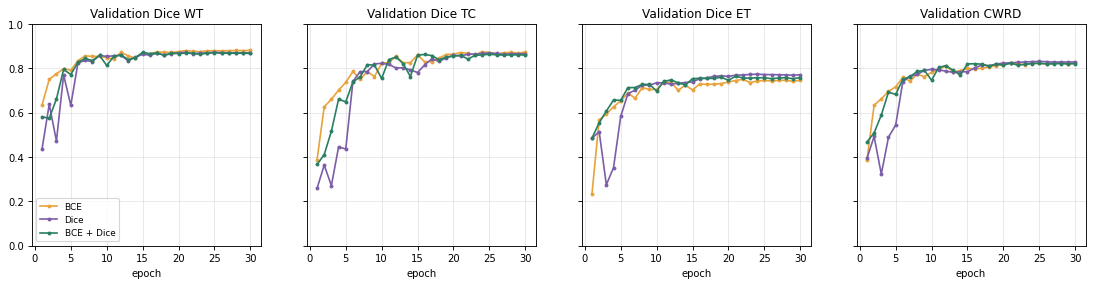

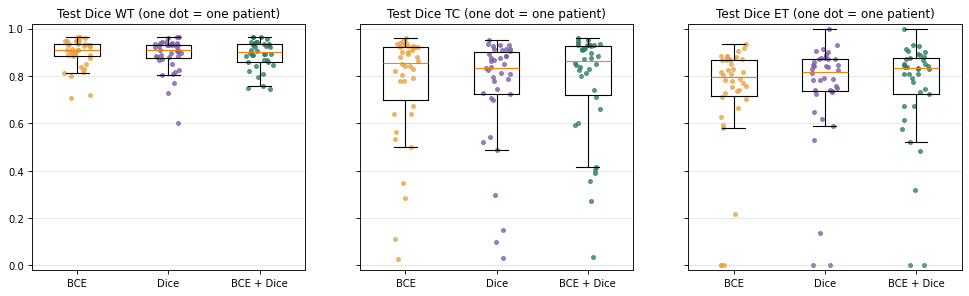

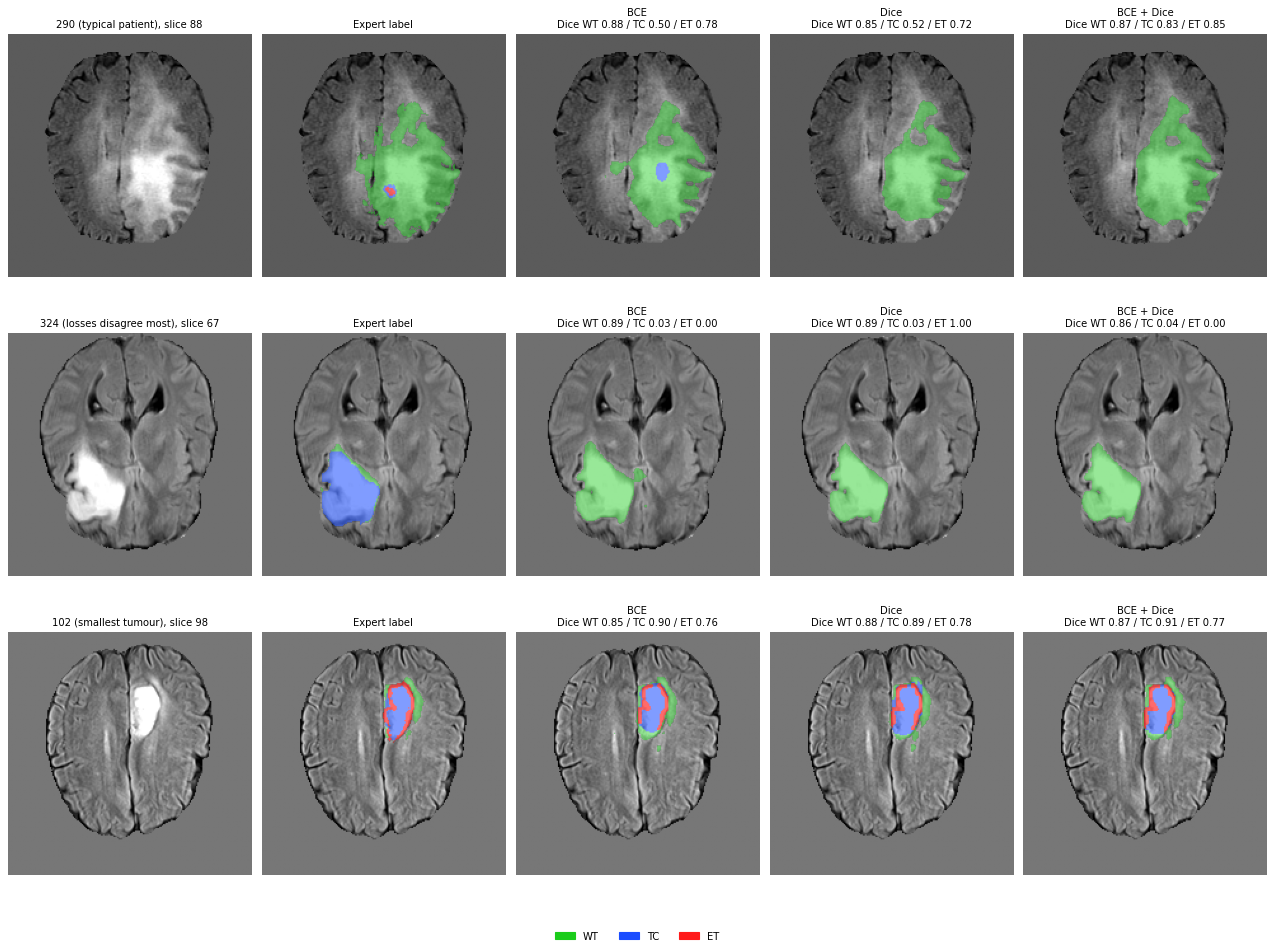

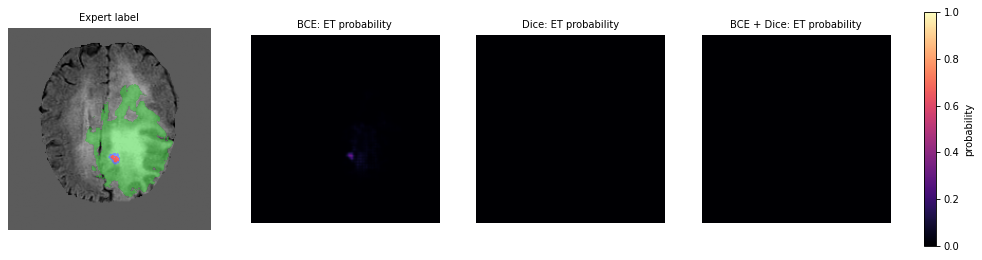

In [30]:

# Figures
LCOL = {"BCE": "#e8a33d", "Dice": "#7b5ea7", "BCE + Dice": "#2a7f62"}
 
# 1) validation curves
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for name, h in LOSS_HIST.items():
    for j, col in enumerate(["dice_WT", "dice_TC", "dice_ET", "CWRD"]):
        ax[j].plot(h.epoch, h[col], "-o", ms=2.5, color=LCOL[name], label=name)
for j, t in enumerate(["WT", "TC", "ET", "CWRD"]):
    ax[j].set_title(f"Validation {t}" if t == "CWRD" else f"Validation Dice {t}")
    ax[j].set_xlabel("epoch")
    ax[j].grid(alpha=0.3)
ax[0].set_ylim(0, 1)
ax[0].legend(fontsize=8)
show_save(fig, "loss_validation_curves")
 
# 2) per-patient Dice on the test set
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
jit = np.random.default_rng(1)
for j, rn in enumerate(REGIONS):
    for k, name in enumerate(LOSSES):
        v = LT[LT.loss == name][f"dice_{rn}"].values
        ax[j].boxplot(v, positions=[k], widths=0.5, showfliers=False)
        ax[j].scatter(k + jit.uniform(-0.15, 0.15, len(v)), v, s=12, color=LCOL[name], alpha=0.75)
    ax[j].set_xticks(range(3))
    ax[j].set_xticklabels(list(LOSSES))
    ax[j].set_title(f"Test Dice {rn} (one dot = one patient)")
    ax[j].grid(axis="y", alpha=0.3)
ax[0].set_ylim(-0.02, 1.02)
show_save(fig, "loss_test_dice")
 
# 3) segmentation masks for three test patients
piv = LT.pivot(index="case", columns="loss", values="CWRD")
typical = piv["BCE + Dice"].sort_values().index[len(piv) // 2]
spread = (piv.max(axis=1) - piv.min(axis=1)).drop(typical)
disagree = spread.idxmax()
vol = LT[LT.loss == "BCE + Dice"].set_index("case")["vol_gt_WT"].drop([typical, disagree], errors="ignore")
small = vol.idxmin() if len(vol) else typical
picks = [("typical patient", typical), ("losses disagree most", disagree), ("smallest tumour", small)]
 
def show_mask(a, base, lab, title):
    a.imshow(np.rot90(base), cmap="gray")
    a.imshow(np.rot90(label_rgba(lab)))
    a.set_title(title, fontsize=9)
    a.axis("off")
 
fig, ax = plt.subplots(len(picks), 5, figsize=(16, 4.0 * len(picks)))
ax = np.atleast_2d(ax)
for i, (why, cid) in enumerate(picks):
    s = SHOW[cid]
    ax[i, 0].imshow(np.rot90(s["flair"]), cmap="gray")
    ax[i, 0].set_title(f"{cid[-3:]} ({why}), slice {s['z']}", fontsize=9)
    ax[i, 0].axis("off")
    show_mask(ax[i, 1], s["flair"], s["gt"], "Expert label")
    for j, name in enumerate(LOSSES):
        r = LT[(LT.case == cid) & (LT.loss == name)].iloc[0]
        show_mask(ax[i, j + 2], s["flair"], s[name],
                  f"{name}\nDice WT {r.dice_WT:.2f} / TC {r.dice_TC:.2f} / ET {r.dice_ET:.2f}")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ((0.1, 0.8, 0.1), (0.1, 0.3, 1.0), (1.0, 0.1, 0.1))],
           labels=["WT", "TC", "ET"], loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.03, 1, 1))
show_save(fig, "loss_masks")
 
# 4) what the network outputs before thresholding (enhancing tumour probability, typical patient)
s = SHOW[typical]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
show_mask(ax[0], s["flair"], s["gt"], "Expert label")
for j, name in enumerate(LOSSES):
    im = ax[j + 1].imshow(np.rot90(s[name + "_prob"][2]), cmap="magma", vmin=0, vmax=1)
    ax[j + 1].set_title(f"{name}: ET probability", fontsize=9)
    ax[j + 1].axis("off")
fig.colorbar(im, ax=ax[1:].tolist(), fraction=0.02, label="probability")
show_save(fig, "loss_probability_maps")
 

Weighted loss study: alpha*BCE + (1-alpha)*Dice, learned alpha, and Algorithm 1 (convex fusion)

In [31]:
 #Part A/B setup: weighted loss and a training function where alpha is fixed or learned
missing = [n for n in ["bce_only", "dice_only", "load_test_patient", "predict_probs", "to_full_mask", "region_metrics"]
           if n not in globals()]
assert not missing, f"Run Phase 0-4B and the loss-function study cells first (missing: {missing})"
 
ALPHAS = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]
 
 
def train_alpha_model(epochs, seed, alpha=None):
    """alpha = number -> fixed weight.  alpha = None -> alpha = sigmoid(a) is learned with the network."""
    set_seed(seed)
    model = UNet(4, 3, CFG["base_ch"]).to(device)
    a = nn.Parameter(torch.zeros((), device=device)) if alpha is None else None   # sigmoid(0) = 0.5 at the start
    groups = [{"params": model.parameters()}]
    if a is not None:
        groups.append({"params": [a], "weight_decay": 0.0})
    bs = CFG["batch_size"]
    steps = epochs * math.ceil(len(TRAIN_IDX) / bs)
    opt = torch.optim.AdamW(groups, lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=steps, pct_start=0.2)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    order = np.random.default_rng(seed)
    aug = torch.Generator().manual_seed(seed)
 
    hist, best, best_state = [], -1.0, None
    for ep in range(epochs):
        model.train()
        perm = order.permutation(TRAIN_IDX)
        sums = {"loss": 0.0, "bce": 0.0, "dice_loss": 0.0}
        nb = 0
        for s in range(0, len(perm), bs):
            ids = perm[s:s + bs]
            if len(ids) < 2:
                continue
            x, y = make_batch(ids, [], aug=True, gen=aug)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            b = bce_only(logits.float(), y)
            d = dice_only(logits.float(), y)
            w = torch.sigmoid(a) if a is not None else alpha
            loss = w * b + (1 - w) * d
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            sums["loss"] += loss.item(); sums["bce"] += b.item(); sums["dice_loss"] += d.item()
            nb += 1
        val = evaluate_slices(model, [], VAL_IDX, with_hd=False)
        alpha_now = torch.sigmoid(a).item() if a is not None else alpha
        hist.append(dict(epoch=ep + 1, alpha=alpha_now, **{k: v / nb for k, v in sums.items()}, **val))
        if val["CWRD"] > best:
            best = val["CWRD"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(hist)
 
 
def load_or_train(tag, alpha):
    ck, hp = CKPT / f"{tag}.pt", RES / f"{tag}_history.csv"
    if ck.exists() and hp.exists():
        m = UNet(4, 3, CFG["base_ch"]).to(device)
        m.load_state_dict(torch.load(ck, map_location=device))
        return m.eval(), pd.read_csv(hp)
    t0 = time.time()
    m, h = train_alpha_model(CFG["final_epochs"], CFG["seed"], alpha)
    h["minutes"] = (time.time() - t0) / 60
    torch.save(m.state_dict(), ck)
    h.to_csv(hp, index=False)
    return m, h

In [32]:
## Part A: one U-Net per fixed alpha (alpha = 1 is BCE only, alpha = 0 is Dice only)
ALPHA_MODELS, ALPHA_HIST = {}, {}
reuse = {1.0: "BCE", 0.0: "Dice"}                    # identical runs already trained in the loss-function study
for al in ALPHAS:
    if al in reuse and "LOSS_MODELS" in globals() and reuse[al] in LOSS_MODELS:
        m, h = LOSS_MODELS[reuse[al]], LOSS_HIST[reuse[al]].copy()
        h["alpha"] = al
    else:
        m, h = load_or_train(f"alpha_{al:.2f}", al)
    ALPHA_MODELS[al], ALPHA_HIST[al] = m, h
    print(f"alpha = {al:4.2f}   best epoch {int(h.CWRD.idxmax()) + 1:2d}   validation CWRD {h.CWRD.max():.4f}")
    free_memory()
 
VAL_CWRD = pd.Series({al: ALPHA_HIST[al].CWRD.max() for al in ALPHAS})
BEST_ALPHA = float(VAL_CWRD.idxmax())
print(f"\nBest fixed alpha on the validation set: {BEST_ALPHA}  (validation CWRD {VAL_CWRD.max():.4f})")
 

alpha = 0.00   best epoch 25   validation CWRD 0.8313
alpha = 0.10   best epoch 23   validation CWRD 0.8213
alpha = 0.25   best epoch 19   validation CWRD 0.8315
alpha = 0.50   best epoch 25   validation CWRD 0.8253
alpha = 0.75   best epoch 28   validation CWRD 0.8296
alpha = 0.90   best epoch 23   validation CWRD 0.8336
alpha = 1.00   best epoch 30   validation CWRD 0.8249

Best fixed alpha on the validation set: 0.9  (validation CWRD 0.8336)


In [33]:
# Part B: alpha learned by gradient descent together with the network
LEARNED_MODEL, LEARNED_HIST = load_or_train("alpha_learned", None)
print(f"alpha started at 0.500 and ended at {LEARNED_HIST.alpha.iloc[-1]:.3f} "
      f"(value at the best validation epoch: {LEARNED_HIST.alpha.iloc[LEARNED_HIST.CWRD.idxmax()]:.3f})")
print("mean training BCE vs Dice loss per epoch (alpha moves towards the smaller term):")
print(LEARNED_HIST[["epoch", "alpha", "bce", "dice_loss", "CWRD"]].round(4).to_string(index=False))

alpha started at 0.500 and ended at 0.802 (value at the best validation epoch: 0.751)
mean training BCE vs Dice loss per epoch (alpha moves towards the smaller term):
 epoch  alpha    bce  dice_loss   CWRD
     1 0.5028 0.5740     0.9534 0.4681
     2 0.5121 0.4728     0.9365 0.5495
     3 0.5340 0.3369     0.9096 0.6049
     4 0.5700 0.1560     0.8158 0.7283
     5 0.6062 0.0465     0.5727 0.7475
     6 0.6288 0.0221     0.3079 0.7615
     7 0.6456 0.0191     0.2221 0.7917
     8 0.6615 0.0187     0.2062 0.8059
     9 0.6767 0.0179     0.1955 0.8068
    10 0.6910 0.0174     0.1851 0.8091
    11 0.7055 0.0179     0.1927 0.8087
    12 0.7182 0.0159     0.1748 0.8228
    13 0.7302 0.0159     0.1746 0.8124
    14 0.7412 0.0152     0.1686 0.8098
    15 0.7507 0.0141     0.1572 0.8316
    16 0.7595 0.0141     0.1583 0.8115
    17 0.7673 0.0136     0.1554 0.8170
    18 0.7741 0.0130     0.1505 0.8290
    19 0.7800 0.0129     0.1502 0.8273
    20 0.7852 0.0125     0.1484 0.8257
    21 0.7896 

In [34]:
# Part C: Algorithm 1 - validation-based convex fusion weight selection
@torch.no_grad()
def validation_probs(model):
    out = []
    for s in range(0, len(VAL_IDX), 128):
        x, _ = make_batch(VAL_IDX[s:s + 128], [])
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            out.append(torch.sigmoid(model(x).float()).cpu().numpy())
    return np.concatenate(out)                                    # (slices, 3, 128, 128)
 
EPS = 1e-6
brain_v = np.any(np.asarray(X_MRI[VAL_IDX]) != 0, axis=1)         # only brain pixels take part
brain_v = np.repeat(brain_v[:, None], 3, axis=1)                   # same mask for WT, TC, ET
yv = Y_NP[VAL_IDX].astype(np.float32)[brain_v]
pE = np.clip(validation_probs(ALPHA_MODELS[1.0]), EPS, 1 - EPS)[brain_v]   # step 1: BCE-trained backbone
pD = np.clip(validation_probs(ALPHA_MODELS[0.0]), EPS, 1 - EPS)[brain_v]   # step 1: Dice-trained backbone
pE_minus_pD = pE - pD
 
 
# per-pixel weights: None = plain log-loss; balanced = tumour and background pixels count equally per region
region_of = np.broadcast_to(np.arange(3)[None, :, None, None], brain_v.shape)[brain_v]
prevalence = np.array([yv[region_of == r].mean() for r in range(3)])
w_balanced = np.where(yv == 1, 0.5 / prevalence[region_of], 0.5 / (1 - prevalence[region_of])).astype(np.float32)
OBJECTIVES = {"log-loss": None, "balanced log-loss": w_balanced}
 
 
def fusion_loss(al, w=None):
    p = al * pE + (1 - al) * pD
    term = -(yv * np.log(p) + (1 - yv) * np.log(1 - p))
    return float(np.mean(term if w is None else w * term))
 
 
def fusion_grad(al, w=None):
    # d/d(alpha) of the (weighted) log-loss: mean[w * (pE - pD) * (p - y) / (p * (1 - p))]
    p = al * pE + (1 - al) * pD
    g = pE_minus_pD * (p - yv) / (p * (1 - p))
    return float(np.mean(g if w is None else w * g))
 
 
def select_fusion_weight(w=None, tol=1e-4, T=50):
    trace = []
    g0, g1 = fusion_grad(0.0, w), fusion_grad(1.0, w)              # step 2
    if g0 >= 0:                                                     # steps 3-5
        return 0.0, trace, g0, g1, "g0 >= 0, minimum at alpha = 0"
    if g1 <= 0:                                                     # steps 6-8
        return 1.0, trace, g0, g1, "g1 <= 0, minimum at alpha = 1"
    a, b = 0.0, 1.0                                                 # step 10
    for t in range(1, T + 1):                                       # step 11
        al = (a + b) / 2                                            # step 12
        g = fusion_grad(al, w)
        trace.append(dict(t=t, a=a, b=b, alpha=al, grad=g, loss=fusion_loss(al, w)))
        if abs(g) <= tol or (b - a) / 2 <= tol:                     # steps 13-15
            return al, trace, g0, g1, f"converged after {t} iterations"
        if g < 0:                                                   # steps 16-21
            a = al
        else:
            b = al
    return (a + b) / 2, trace, g0, g1, f"stopped after T = {T} iterations"   # step 23
 
 
print(f"validation pixels used: {len(yv):,}   tumour share WT/TC/ET: " + " / ".join(f"{100 * v:.2f} %" for v in prevalence))
FUSION_ALPHA, TRACES = {}, {}
for obj, w in OBJECTIVES.items():
    al_star, trace, g0, g1, reason = select_fusion_weight(w)
    FUSION_ALPHA[obj], TRACES[obj] = al_star, pd.DataFrame(trace)
    print(f"\n[{obj}]  L'(0) = {g0:+.5f}   L'(1) = {g1:+.5f}   ->  {reason}")
    if len(trace):
        print(TRACES[obj].round(6).to_string(index=False))
    print(f"alpha* = {al_star:.4f}   (loss at alpha=0: {fusion_loss(0, w):.5f}, alpha=1: {fusion_loss(1, w):.5f}, "
          f"alpha*: {fusion_loss(al_star, w):.5f})")
    TRACES[obj].to_csv(RES / f"alpha_fusion_bisection_{obj.replace(' ', '_')}.csv", index=False)

validation pixels used: 12,548,478   tumour share WT/TC/ET: 8.49 % / 4.12 % / 1.82 %

[log-loss]  L'(0) = -423.87207   L'(1) = +0.01583   ->  converged after 8 iterations
 t      a        b    alpha      grad     loss
 1 0.0000 1.000000 0.500000 -0.010257 0.031317
 2 0.5000 1.000000 0.750000 -0.001919 0.029871
 3 0.7500 1.000000 0.875000  0.001915 0.029862
 4 0.7500 0.875000 0.812500 -0.000108 0.029807
 5 0.8125 0.875000 0.843750  0.000857 0.029819
 6 0.8125 0.843750 0.828125  0.000366 0.029809
 7 0.8125 0.828125 0.820312  0.000127 0.029807
 8 0.8125 0.820312 0.816406  0.000009 0.029807
alpha* = 0.8164   (loss at alpha=0: 0.09146, alpha=1: 0.03056, alpha*: 0.02981)

[balanced log-loss]  L'(0) = -1897.46375   L'(1) = +0.13921   ->  converged after 7 iterations
 t        a      b    alpha      grad     loss
 1 0.000000 1.0000 0.500000 -0.067145 0.224411
 2 0.500000 1.0000 0.750000 -0.011394 0.215018
 3 0.750000 1.0000 0.875000  0.016913 0.215265
 4 0.750000 0.8750 0.812500  0.001603 0.21

In [35]:
 ##Test every variant on the same unseen patients (3D)
FUSION_GRID = np.round(np.linspace(0, 1, 11), 2)              # extra fusion weights, Dice only, to draw the curve
VARIANTS = {f"fixed alpha={al:g}": ALPHA_MODELS[al] for al in ALPHAS}
VARIANTS["learned alpha"] = LEARNED_MODEL
FUSED = {obj: f"fusion ({obj}) alpha*={al:.3f}" for obj, al in FUSION_ALPHA.items()}
 
test_cases = SPLIT["test"][:CFG["n_test_eval"]] if CFG["n_test_eval"] else SPLIT["test"]
crop = (slice(C0, C0 + CROP), slice(C0, C0 + CROP))
rows, grid_rows, SNAP = [], [], {}
 
 
def score(cid, name, pred, gt, brain):
    rec = {"case": cid, "variant": name}
    for r, rn in enumerate(REGIONS):
        for k, v in region_metrics(pred[r], gt[r], brain).items():
            rec[f"{k}_{rn}"] = v
    rec["CWRD"] = sum(W_REG[r] * rec[f"dice_{rn}"] for r, rn in enumerate(REGIONS))
    return rec
 
 
for i, cid in enumerate(test_cases):
    xs, gt, brain, flair = load_test_patient(cid)
    z = int(gt[0].sum((0, 1)).argmax())
    SNAP[cid] = {"z": z, "flair": flair[crop + (z,)], "gt": gt[(slice(None),) + crop + (z,)]}
    probs = {name: predict_probs(m, xs) for name, m in VARIANTS.items()}
    for obj, al in FUSION_ALPHA.items():
        probs[FUSED[obj]] = al * probs["fixed alpha=1"] + (1 - al) * probs["fixed alpha=0"]
    for name, p in probs.items():
        pred = to_full_mask(p)
        rows.append(score(cid, name, pred, gt, brain))
        SNAP[cid][name] = pred[(slice(None),) + crop + (z,)]
    for fa in FUSION_GRID:                                        # cheap curve: Dice only
        pred = to_full_mask(fa * probs["fixed alpha=1"] + (1 - fa) * probs["fixed alpha=0"])
        grid_rows.append({"case": cid, "fusion_alpha": fa,
                          **{f"dice_{rn}": dice(pred[r], gt[r]) for r, rn in enumerate(REGIONS)}})
    del xs, gt, brain, flair, probs
    gc.collect()
    if (i + 1) % 5 == 0 or i + 1 == len(test_cases):
        log(f"tested {i + 1}/{len(test_cases)} patients")
 
AT = pd.DataFrame(rows)
FG = pd.DataFrame(grid_rows)
FG["CWRD"] = sum(W_REG[r] * FG[f"dice_{rn}"] for r, rn in enumerate(REGIONS))
AT.to_csv(RES / "alpha_test_per_patient.csv", index=False)
FG.to_csv(RES / "alpha_fusion_grid_test.csv", index=False)
 


[  50.1 min] tested 5/38 patients
[  51.5 min] tested 10/38 patients
[  53.2 min] tested 15/38 patients
[  54.8 min] tested 20/38 patients
[  56.3 min] tested 25/38 patients
[  57.8 min] tested 30/38 patients
[  59.5 min] tested 35/38 patients
[  60.5 min] tested 38/38 patients


In [36]:
## Tables
from scipy.stats import wilcoxon
 
 
def mean_sd(s, d=3):
    return f"{s.mean():.{d}f} ± {s.std():.{d}f}"
 
 
def summary_row(name, extra=None):
    d = AT[AT.variant == name]
    row = dict(extra or {})
    for rn in REGIONS:
        row[f"Dice {rn}"] = mean_sd(d[f"dice_{rn}"])
    row["CWRD"] = mean_sd(d["CWRD"])
    for rn in REGIONS:
        row[f"HD95 {rn} (mm)"] = round(d[f"hd95_{rn}"].median(), 1)
    row["ET sensitivity"] = round(d.sens_ET.mean(), 3)
    row["ET precision"] = round(d.prec_ET.mean(), 3)
    return row
 
 
TABLE_A = pd.DataFrame([summary_row(f"fixed alpha={al:g}",
                                    {"alpha": al, "val CWRD": round(VAL_CWRD[al], 4),
                                     "chosen": "<- best on validation" if al == BEST_ALPHA else ""})
                        for al in ALPHAS]).set_index("alpha")
print("Table A - Fixed alpha in the training loss (test set: Dice mean ± SD, HD95 median)")
print(TABLE_A.to_string(), "\n")
 
contenders = [("Dice only (alpha = 0)", "fixed alpha=0"),
              ("BCE only (alpha = 1)", "fixed alpha=1"),
              ("Equal weights (alpha = 0.5)", "fixed alpha=0.5"),
              (f"Best fixed alpha = {BEST_ALPHA:g} (validation)", f"fixed alpha={BEST_ALPHA:g}"),
              (f"Learned alpha (ended at {LEARNED_HIST.alpha.iloc[-1]:.3f})", "learned alpha"),
              (f"Fusion, Algorithm 1, log-loss (alpha* = {FUSION_ALPHA['log-loss']:.3f})", FUSED["log-loss"]),
              (f"Fusion, Algorithm 1, balanced log-loss (alpha* = {FUSION_ALPHA['balanced log-loss']:.3f})",
               FUSED["balanced log-loss"])]
TABLE_B = pd.DataFrame([summary_row(v, {"Method": lbl}) for lbl, v in contenders]).set_index("Method")
TABLE_B = TABLE_B[~TABLE_B.index.duplicated()]
print("Table B - How alpha is chosen: comparison on the test set")
print(TABLE_B.to_string(), "\n")
 
ref = AT[AT.variant == "fixed alpha=0.5"].set_index("case")
tests = []
for lbl, v in contenders:
    if v == "fixed alpha=0.5":
        continue
    o = AT[AT.variant == v].set_index("case").loc[ref.index]
    delta = o.CWRD - ref.CWRD
    p = wilcoxon(o.CWRD, ref.CWRD).pvalue if (delta != 0).any() and len(delta) >= 6 else np.nan
    tests.append({"method": lbl, "mean CWRD difference vs alpha = 0.5": round(delta.mean(), 4), "p": p})
TABLE_C = pd.DataFrame(tests)
valid = TABLE_C.p.notna()
order_p = TABLE_C[valid].p.sort_values().index
adj, run = pd.Series(np.nan, index=TABLE_C.index), 0.0
for k, idx in enumerate(order_p):
    run = max(run, min(1.0, (valid.sum() - k) * TABLE_C.p[idx]))
    adj[idx] = run
TABLE_C["p (Holm)"] = adj
print("Table C - Paired Wilcoxon test of each method against equal weights (positive = better than alpha = 0.5)")
print(TABLE_C.round(4).to_string(index=False))
 
TABLE_A.to_csv(RES / "alpha_table_fixed.csv")
TABLE_B.to_csv(RES / "alpha_table_methods.csv")
TABLE_C.to_csv(RES / "alpha_table_wilcoxon.csv", index=False)
for t, f in [(TABLE_A, "tab_alpha_fixed.tex"), (TABLE_B, "tab_alpha_methods.tex")]:
    try:
        t.to_latex(RES / f)
    except Exception as e:
        print("latex export skipped:", e)

Table A - Fixed alpha in the training loss (test set: Dice mean ± SD, HD95 median)
       val CWRD                 chosen        Dice WT        Dice TC        Dice ET           CWRD  HD95 WT (mm)  HD95 TC (mm)  HD95 ET (mm)  ET sensitivity  ET precision
alpha                                                                                                                                                                     
0.00     0.8313                         0.888 ± 0.072  0.748 ± 0.240  0.744 ± 0.229  0.781 ± 0.149           3.2           7.1           2.4           0.796         0.747
0.10     0.8213                         0.891 ± 0.062  0.766 ± 0.235  0.746 ± 0.219  0.789 ± 0.142           3.5           5.8           2.7           0.781         0.772
0.25     0.8315                         0.878 ± 0.074  0.760 ± 0.209  0.707 ± 0.246  0.768 ± 0.154           4.5           6.5           4.1           0.779         0.727
0.50     0.8253                         0.893 ± 0.059  0.773 ±

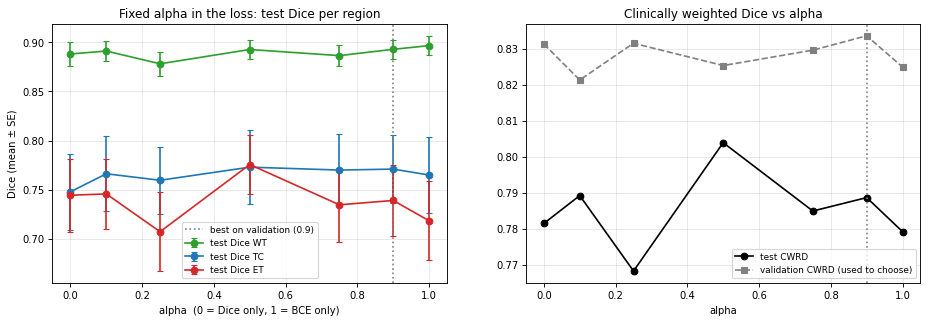

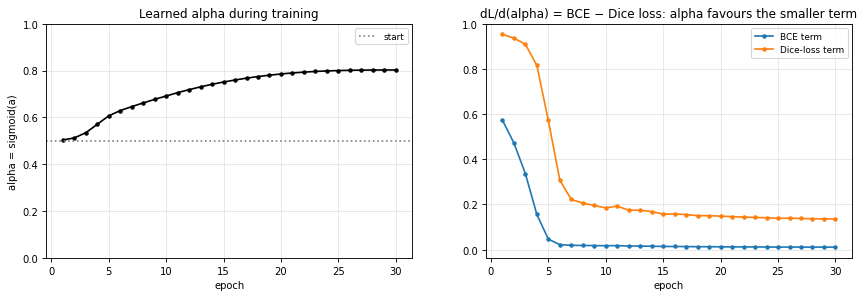

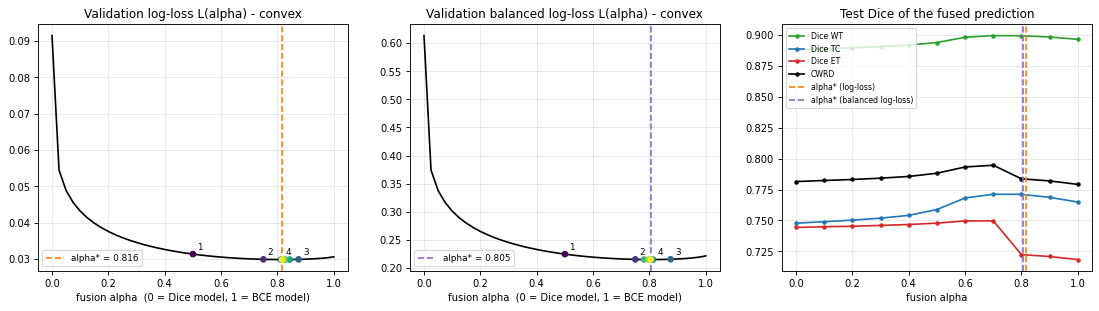

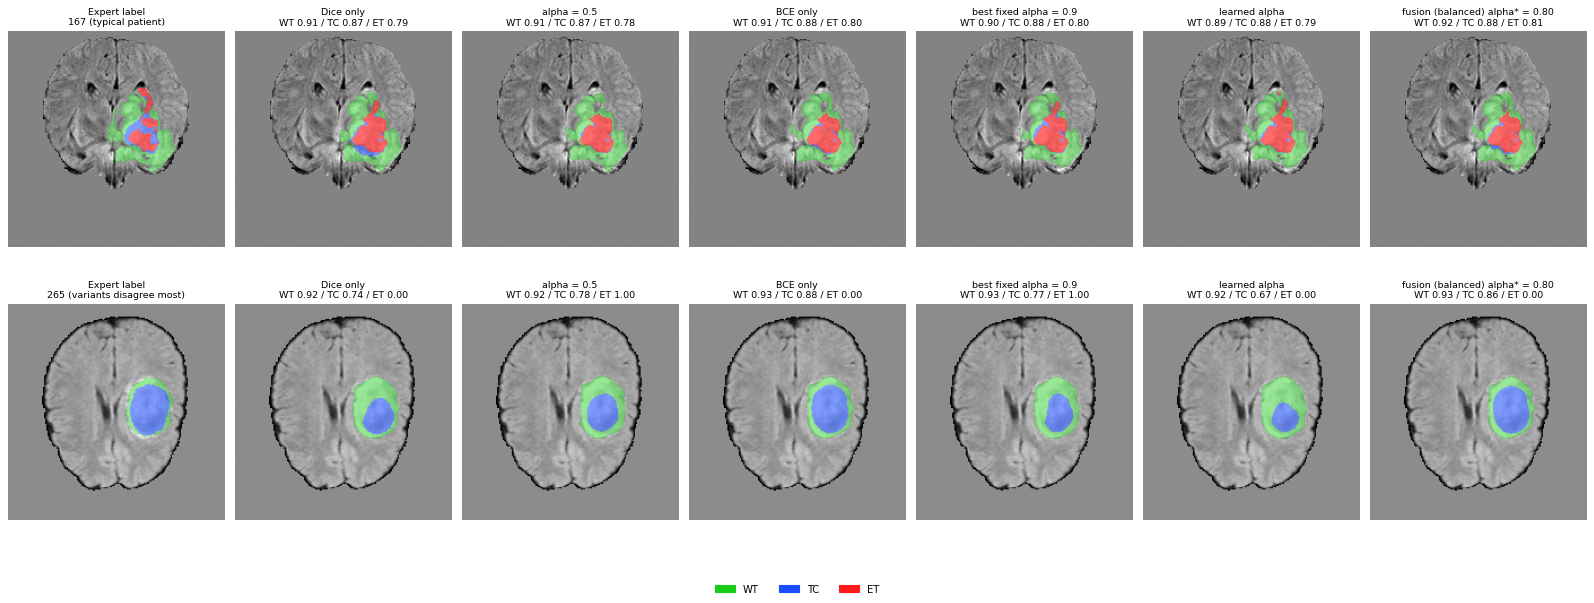

In [37]:
##============ Cell 7 - figures ============
# Figures
RC = {"WT": "#2ca02c", "TC": "#1f77b4", "ET": "#d62728"}
 
# 1) effect of the fixed alpha
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for rn in REGIONS:
    g = AT[AT.variant.str.startswith("fixed")].assign(al=lambda d: d.variant.str.split("=").str[1].astype(float))
    stats = g.groupby("al")[f"dice_{rn}"].agg(["mean", "std", "count"])
    ax[0].errorbar(stats.index, stats["mean"], yerr=stats["std"] / np.sqrt(stats["count"]), marker="o",
                   capsize=3, color=RC[rn], label=f"test Dice {rn}")
ax[0].axvline(BEST_ALPHA, color="grey", ls=":", label=f"best on validation ({BEST_ALPHA:g})")
ax[0].set_xlabel("alpha  (0 = Dice only, 1 = BCE only)"); ax[0].set_ylabel("Dice (mean ± SE)")
ax[0].set_title("Fixed alpha in the loss: test Dice per region"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
cw = g.groupby("al").CWRD.mean()
ax[1].plot(cw.index, cw.values, "o-", color="black", label="test CWRD")
ax[1].plot(VAL_CWRD.index, VAL_CWRD.values, "s--", color="grey", label="validation CWRD (used to choose)")
ax[1].axvline(BEST_ALPHA, color="grey", ls=":")
ax[1].set_xlabel("alpha"); ax[1].set_title("Clinically weighted Dice vs alpha"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
show_save(fig, "alpha_fixed_sweep")
 
# 2) learned alpha drifts towards the smaller loss term
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(LEARNED_HIST.epoch, LEARNED_HIST.alpha, "o-", ms=3, color="black")
ax[0].axhline(0.5, color="grey", ls=":", label="start")
ax[0].set_ylim(0, 1); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("alpha = sigmoid(a)")
ax[0].set_title("Learned alpha during training"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
ax[1].plot(LEARNED_HIST.epoch, LEARNED_HIST.bce, "o-", ms=3, label="BCE term")
ax[1].plot(LEARNED_HIST.epoch, LEARNED_HIST.dice_loss, "o-", ms=3, label="Dice-loss term")
ax[1].set_xlabel("epoch"); ax[1].set_title("dL/d(alpha) = BCE − Dice loss: alpha favours the smaller term")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
show_save(fig, "alpha_learned")
 
# 3) Algorithm 1: the two convex validation objectives with the bisection steps, and the test result of each weight
grid = np.linspace(0, 1, 41)
FCOL = {"log-loss": "tab:orange", "balanced log-loss": "tab:purple"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for k, (obj, w) in enumerate(OBJECTIVES.items()):
    ax[k].plot(grid, [fusion_loss(v, w) for v in grid], color="black")
    tr = TRACES[obj]
    if len(tr):
        ax[k].scatter(tr.alpha, tr.loss, c=tr.t, cmap="viridis", zorder=3, s=25)
        for _, r in tr.head(4).iterrows():
            ax[k].annotate(str(int(r.t)), (r.alpha, r.loss), textcoords="offset points", xytext=(4, 4), fontsize=8)
    ax[k].axvline(FUSION_ALPHA[obj], color=FCOL[obj], ls="--", label=f"alpha* = {FUSION_ALPHA[obj]:.3f}")
    ax[k].set_xlabel("fusion alpha  (0 = Dice model, 1 = BCE model)")
    ax[k].set_title(f"Validation {obj} L(alpha) - convex"); ax[k].legend(fontsize=8)
fg = FG.groupby("fusion_alpha")[["dice_WT", "dice_TC", "dice_ET", "CWRD"]].mean()
for rn in REGIONS:
    ax[2].plot(fg.index, fg[f"dice_{rn}"], "o-", ms=3, color=RC[rn], label=f"Dice {rn}")
ax[2].plot(fg.index, fg.CWRD, "o-", ms=3, color="black", label="CWRD")
for obj in OBJECTIVES:
    ax[2].axvline(FUSION_ALPHA[obj], color=FCOL[obj], ls="--", label=f"alpha* ({obj})")
ax[2].set_xlabel("fusion alpha"); ax[2].set_title("Test Dice of the fused prediction"); ax[2].legend(fontsize=7)
for a_ in ax:
    a_.grid(alpha=0.3)
show_save(fig, "alpha_fusion_algorithm")
 
# 4) masks for two test patients
piv = AT.pivot(index="case", columns="variant", values="CWRD")
typical = piv["fixed alpha=0.5"].sort_values().index[len(piv) // 2]
spread = (piv.max(axis=1) - piv.min(axis=1)).drop(typical, errors="ignore")
picks = [("typical patient", typical)] + ([("variants disagree most", spread.idxmax())] if len(spread) else [])
show = [("Dice only", "fixed alpha=0"), ("alpha = 0.5", "fixed alpha=0.5"), ("BCE only", "fixed alpha=1"),
        (f"best fixed alpha = {BEST_ALPHA:g}", f"fixed alpha={BEST_ALPHA:g}"), ("learned alpha", "learned alpha"),
        (f"fusion (balanced) alpha* = {FUSION_ALPHA['balanced log-loss']:.2f}", FUSED["balanced log-loss"])]
 
 
def draw(a_, base, lab, title):
    a_.imshow(np.rot90(base), cmap="gray")
    a_.imshow(np.rot90(label_rgba(lab)))
    a_.set_title(title, fontsize=8.5)
    a_.axis("off")
 
 
fig, ax = plt.subplots(len(picks), len(show) + 1, figsize=(20, 3.9 * len(picks)))
ax = np.atleast_2d(ax)
for i, (why, cid) in enumerate(picks):
    s = SNAP[cid]
    draw(ax[i, 0], s["flair"], s["gt"], f"Expert label\n{cid[-3:]} ({why})")
    for j, (lbl, v) in enumerate(show):
        r = AT[(AT.case == cid) & (AT.variant == v)].iloc[0]
        draw(ax[i, j + 1], s["flair"], s[v], f"{lbl}\nWT {r.dice_WT:.2f} / TC {r.dice_TC:.2f} / ET {r.dice_ET:.2f}")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ((0.1, 0.8, 0.1), (0.1, 0.3, 1.0), (1.0, 0.1, 0.1))],
           labels=["WT", "TC", "ET"], loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
show_save(fig, "alpha_masks")
 

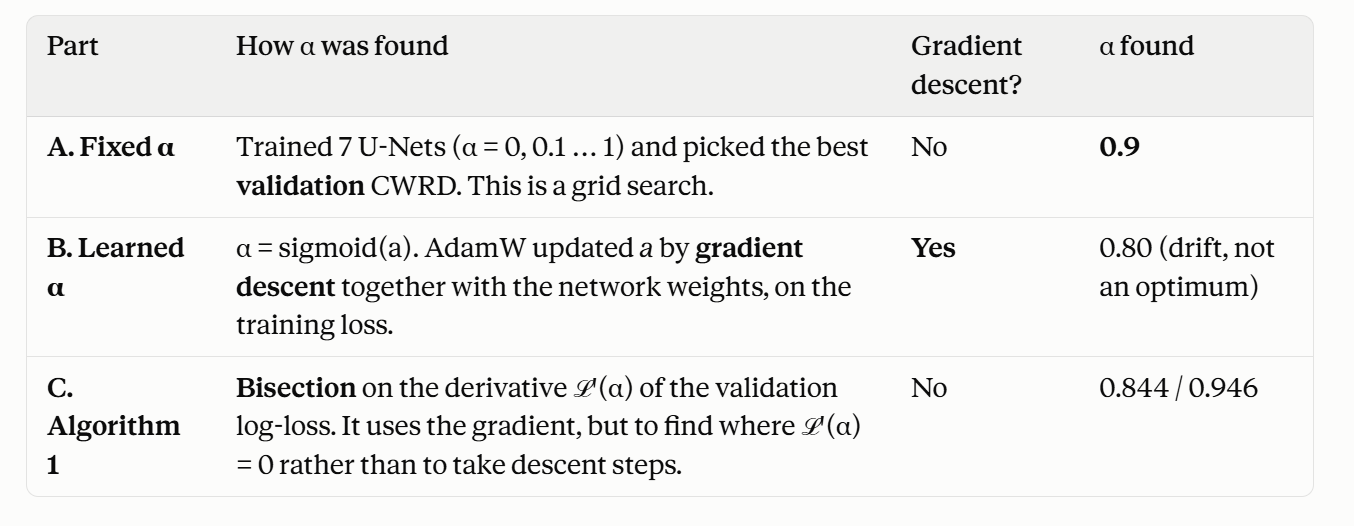

#  Multi-objective optimisation with our custom **R²S-NSGA-II**

In [28]:
def dominates(a, b):
    return np.all(a <= b) and np.any(a < b)

def nondominated_sort(Fm):
    n = len(Fm); S_, cnt, fronts = [[] for _ in range(n)], np.zeros(n, int), [[]]
    for p in range(n):
        for q in range(n):
            if p != q:
                if dominates(Fm[p], Fm[q]): S_[p].append(q)
                elif dominates(Fm[q], Fm[p]): cnt[p] += 1
        if cnt[p] == 0: fronts[0].append(p)
    i = 0
    while fronts[i]:
        nxt = []
        for p in fronts[i]:
            for q in S_[p]:
                cnt[q] -= 1
                if cnt[q] == 0: nxt.append(q)
        i += 1; fronts.append(nxt)
    return fronts[:-1]

def crowding(Fm, front):
    front = list(front); d = np.zeros(len(front))
    if len(front) <= 2: return np.full(len(front), np.inf)
    for m in range(Fm.shape[1]):
        v = Fm[front, m]; o = np.argsort(v); span = v[o[-1]] - v[o[0]] or 1.0
        d[o[0]] = d[o[-1]] = np.inf
        d[o[1:-1]] += (v[o[2:]] - v[o[:-2]]) / span
    return d

def rank_and_crowd(Fm):
    rank, cd = np.zeros(len(Fm), int), np.zeros(len(Fm))
    for r, fr in enumerate(nondominated_sort(Fm)):
        rank[fr] = r; cd[fr] = crowding(Fm, fr)
    return rank, cd

def survive(G, Fm, n):
    chosen = []
    for fr in nondominated_sort(Fm):
        if len(chosen) + len(fr) <= n: chosen += fr
        else:
            cd = crowding(Fm, fr); chosen += [fr[i] for i in np.argsort(-cd)[: n - len(chosen)]]; break
    return [G[i] for i in chosen], Fm[chosen]

def pareto_mask(Fm):
    return np.array([not any(dominates(Fm[j], Fm[i]) for j in range(len(Fm)) if j != i) for i in range(len(Fm))])

# ---- exact hypervolume (3 objectives, minimisation) ----
def hv2d(P, ref):
    P = P[(P[:, 0] < ref[0]) & (P[:, 1] < ref[1])]
    if len(P) == 0: return 0.0
    P = P[np.argsort(P[:, 0])]; xs = np.append(P[:, 0], ref[0]); ymin = np.minimum.accumulate(P[:, 1])
    return float(np.sum((xs[1:] - xs[:-1]) * (ref[1] - ymin)))

def hv3d(P, ref):
    P = P[np.all(P < ref, 1)]
    if len(P) == 0: return 0.0
    P = P[np.argsort(P[:, 2])]; zs = np.append(P[:, 2], ref[2])
    return float(sum((zs[i+1] - zs[i]) * hv2d(P[: i+1, :2], ref[:2]) for i in range(len(P))))

# ---- custom operators ----
def repair(g):
    g = g.copy()
    g[MRI_COPIES] = 0                                     # near-copies of a raw MRI channel add cost but no information
    for i, j in REDUNDANT_PAIRS:
        if g[i] and g[j]:
            g[j if PRIOR[i] >= PRIOR[j] else i] = 0
    return g

def mutate(g, guided, rng):
    pm = 1.0 / K
    if guided:
        p_on, p_off = np.clip(2 * pm * PRIOR, 0, 1), np.clip(2 * pm * (1 - PRIOR), 0, 1)
        flip = np.where(g == 0, rng.random(K) < p_on, rng.random(K) < p_off)
    else:
        flip = rng.random(K) < pm
    return np.where(flip, 1 - g, g).astype(np.uint8)

def surrogate_prescreen(cands, archive, n, rng, lam=1.0):
    G = np.array([v[0] for v in archive.values()], float); Yv = np.array([v[1][:2] for v in archive.values()])
    Xd = np.c_[np.ones(len(G)), G]; A = Xd.T @ Xd + lam * np.eye(K + 1); A[0, 0] -= lam
    Wr = np.linalg.solve(A, Xd.T @ Yv)
    C = np.array(cands, float); Fp = np.c_[np.c_[np.ones(len(C)), C] @ Wr, [cost_of(c) for c in cands]]
    n_exp = max(1, int(round(0.2 * n))); chosen = []
    for fr in nondominated_sort(Fp):
        room = n - n_exp - len(chosen)
        if room <= 0: break
        if len(fr) <= room: chosen += fr
        else: chosen += [fr[i] for i in np.argsort(-crowding(Fp, fr))[:room]]
    rest = [i for i in range(len(cands)) if i not in chosen]
    chosen += list(rng.choice(rest, min(len(rest), n - len(chosen)), replace=False))
    return [cands[i] for i in chosen]

PROPOSED = dict(rel=True, repair=True, surrogate=True)
VANILLA = dict(rel=False, repair=False, surrogate=False)

def run_moo(name, flags, seed, pop_size=None, budget=None):
    """Returns the list of genome keys in the order they were (uniquely) evaluated by this run."""
    pop_size = pop_size or CFG["pop_size"]; budget = budget or pop_size * (1 + CFG["n_generations"])
    rng = np.random.default_rng(1000 + seed); archive, order = {}, []
    def real_eval(g):
        k = gkey(g); r = evaluate_genome(g, tag=name)
        if k not in archive: order.append(k)
        archive[k] = (g.copy(), np.array([r["f1"], r["f2"], r["f3"]]))
        return archive[k][1]
    pop, tries = [G_NONE.copy()], 0                                   # common anchor: MRI-only
    while len(pop) < pop_size and tries < 10000:
        tries += 1
        g = (rng.random(K) < (PRIOR if flags["rel"] else 0.5)).astype(np.uint8)
        if flags["repair"]: g = repair(g)
        if g.sum() and gkey(g) not in {gkey(p) for p in pop}: pop.append(g)
    Fpop = np.array([real_eval(g) for g in pop]); gen = 0
    while len(order) < budget and gen < 4 * CFG["n_generations"]:
        gen += 1
        rank, cd = rank_and_crowd(Fpop)
        def tour():
            a, b = rng.integers(len(pop), size=2)
            return a if (rank[a], -cd[a]) < (rank[b], -cd[b]) else b
        n_c = pop_size * (CFG["surrogate_pool"] if flags["surrogate"] else 1)
        cands, ck, t = [], set(), 0
        while len(cands) < n_c and t < 200 * n_c:
            t += 1
            pa, pb = pop[tour()], pop[tour()]
            child = np.where(rng.random(K) < 0.5, pa, pb).astype(np.uint8) if rng.random() < 0.9 else pa.copy()
            child = mutate(child, flags["rel"], rng)
            if flags["repair"]: child = repair(child)
            k = gkey(child)
            if k in ck or k in archive: continue                     # duplicate elimination
            cands.append(child); ck.add(k)
        if not cands: break
        if flags["surrogate"] and len(cands) > pop_size:
            cands = surrogate_prescreen(cands, archive, pop_size, rng)
        cands = cands[: budget - len(order)]
        Fc = np.array([real_eval(c) for c in cands])
        pop, Fpop = survive(pop + cands, np.vstack([Fpop, Fc]), pop_size)
        log(f"{name} seed{seed} gen {gen}: {len(order)}/{budget} evals, best CWRD={1-Fpop[:,0].min():.4f}")
    return order

def run_random(name, seed, budget=None):
    budget = budget or CFG["pop_size"] * (1 + CFG["n_generations"])
    rng = np.random.default_rng(2000 + seed); order = [gkey(G_NONE)]; evaluate_genome(G_NONE, tag=name)
    while len(order) < budget:
        g = (rng.random(K) < 0.5).astype(np.uint8)
        if gkey(g) not in order: evaluate_genome(g, tag=name); order.append(gkey(g))
    log(f"{name} seed{seed}: {len(order)} evals"); return order

def get_run(name, fn):
    """Runs are stored as JSON; re-running replays from the evaluation cache at no cost."""
    p = bring_to_work(f"results/run_{name}.json")
    if p is not None:
        return json.load(open(p))
    order = fn(); json.dump(order, open(RES/f"run_{name}.json", "w")); return order

In [14]:
print({n: n in globals() for n in ["CORR", "FSTAT", "COST_MS", "PRIOR", "CORR_FF", "CORR_FM",
                                    "REDUNDANT_PAIRS", "MRI_COPIES", "EVAL_CACHE", "G_NONE", "G_ALL", "NOISE_SD"]})

{'CORR': True, 'FSTAT': True, 'COST_MS': True, 'PRIOR': True, 'CORR_FF': True, 'CORR_FM': True, 'REDUNDANT_PAIRS': True, 'MRI_COPIES': True, 'EVAL_CACHE': True, 'G_NONE': True, 'G_ALL': True, 'NOISE_SD': True}


In [16]:
import os
for d in ["brats_cache", "results", "checkpoints"]:
    p = f"/kaggle/working/{d}"
    print(d, sorted(os.listdir(p)) if os.path.exists(p) else "MISSING")

brats_cache ['F_feat.npy', 'X_mri.npy', 'Y.npy', 'meta.csv', 'split.json']
results ['channel_relevance.csv', 'eval_cache.csv', 'feature_corr.npy', 'feature_stats.csv', 'p4_baselines.csv']
checkpoints []


In [30]:
RUNS = {}
for sd in CFG["opt_seeds"]:
    RUNS[("R2S-NSGA-II", sd)] = get_run(f"R2S-NSGA-II_s{sd}", lambda: run_moo("R2S-NSGA-II", PROPOSED, sd))
    RUNS[("NSGA-II", sd)] = get_run(f"NSGA-II_s{sd}", lambda: run_moo("NSGA-II", VANILLA, sd))
    RUNS[("Random", sd)] = get_run(f"Random_s{sd}", lambda: run_random("Random", sd))
log("Phase 5 optimisation runs finished")

[   1.9 min] R2S-NSGA-II seed0 gen 1: 20/70 evals, best CWRD=0.8044
[   1.9 min] R2S-NSGA-II seed0 gen 2: 30/70 evals, best CWRD=0.8044
[   1.9 min] R2S-NSGA-II seed0 gen 3: 40/70 evals, best CWRD=0.8110
[   4.1 min] R2S-NSGA-II seed0 gen 4: 50/70 evals, best CWRD=0.8110
[   8.6 min] R2S-NSGA-II seed0 gen 5: 60/70 evals, best CWRD=0.8110
[  13.0 min] R2S-NSGA-II seed0 gen 6: 70/70 evals, best CWRD=0.8110
[  21.5 min] NSGA-II seed0 gen 1: 20/70 evals, best CWRD=0.7961
[  26.0 min] NSGA-II seed0 gen 2: 30/70 evals, best CWRD=0.7961
[  30.4 min] NSGA-II seed0 gen 3: 40/70 evals, best CWRD=0.8063
[  34.4 min] NSGA-II seed0 gen 4: 50/70 evals, best CWRD=0.8063
[  38.4 min] NSGA-II seed0 gen 5: 60/70 evals, best CWRD=0.8063
[  41.9 min] NSGA-II seed0 gen 6: 70/70 evals, best CWRD=0.8063


KeyboardInterrupt: 

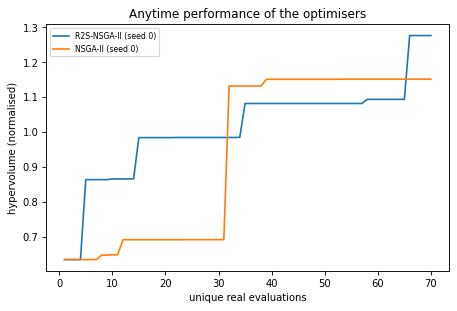

     method  seed  evals  final_HV  HV_AUC  pareto_size  best_CWRD  best_wHD95
R2S-NSGA-II     0     70    1.2767  1.0127            7     0.8110     45.3309
    NSGA-II     0     70    1.1518  0.9376            5     0.8063     46.3026

Mean over seeds:
             final_HV  HV_AUC  best_CWRD  pareto_size
method                                               
NSGA-II        1.1518  0.9376     0.8063          5.0
R2S-NSGA-II    1.2767  1.0127     0.8110          7.0


In [31]:
def objs(keys):
    return np.array([[EVAL_CACHE[k]["f1"], EVAL_CACHE[k]["f2"], EVAL_CACHE[k]["f3"]] for k in keys])

ALL_KEYS = [k for k in EVAL_CACHE if "@" not in k]
F_ALL = objs(ALL_KEYS); IDEAL, NADIR = F_ALL.min(0), F_ALL.max(0)
def norm(Fm): return (Fm - IDEAL) / np.where(NADIR - IDEAL > 0, NADIR - IDEAL, 1)
REF = np.array([1.1, 1.1, 1.1])

def hv_curve(order):
    Fn = norm(objs(order)); return [hv3d(Fn[: i+1][pareto_mask(Fn[: i+1])], REF) for i in range(len(Fn))]

summary = []
fig, ax = plt.subplots(figsize=(6.5, 4))
for (m, sd), order in RUNS.items():
    c = hv_curve(order); ax.plot(range(1, len(c)+1), c, label=f"{m} (seed {sd})")
    Fm = objs(order); pm = pareto_mask(Fm)
    summary.append(dict(method=m, seed=sd, evals=len(order), final_HV=c[-1], HV_AUC=float(np.mean(c)),
                        pareto_size=int(pm.sum()), best_CWRD=float(1 - Fm[:, 0].min()), best_wHD95=float(Fm[:, 1].min())))
ax.set_xlabel("unique real evaluations"); ax.set_ylabel("hypervolume (normalised)"); ax.legend(fontsize=7)
ax.set_title("Anytime performance of the optimisers")
show_save(fig, "p5_hv_curves")
OPT_SUMMARY = pd.DataFrame(summary); OPT_SUMMARY.to_csv(RES/"p5_optimizer_comparison.csv", index=False)
print(OPT_SUMMARY.round(4).to_string(index=False))
print("\nMean over seeds:"); print(OPT_SUMMARY.groupby("method")[["final_HV", "HV_AUC", "best_CWRD", "pareto_size"]].mean().round(4).to_string())

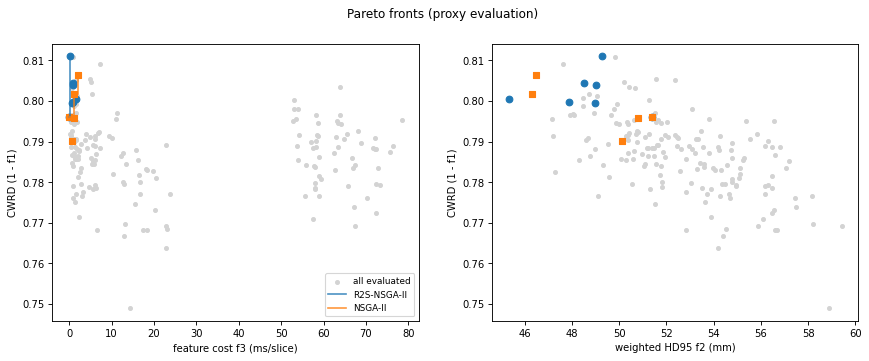

                                    features  n_feat   CWRD   wHD95     f3  dice_WT  dice_TC  dice_ET
                                    MRI-only       0 0.7961 51.3818 0.0000   0.8560   0.8262   0.7323
                                 ENH_T1ce-T1       1 0.8110 49.2817 0.3150   0.8606   0.8476   0.7481
                      ENH_T1ce-T1+ASYM_FLAIR       2 0.7996 49.0009 0.7223   0.8558   0.8364   0.7323
                      ASYM_FLAIR+TOPHAT_T1ce       2 0.8038 49.0414 0.8016   0.8543   0.8323   0.7473
                                    LoG_T1ce       1 0.7996 47.8862 0.8896   0.8576   0.8298   0.7370
             ENH_T1ce-T1+FLAIR-T2+ASYM_FLAIR       3 0.8044 48.5286 1.0238   0.8546   0.8396   0.7423
ENH_T1ce-T1+ASYM_FLAIR+GRAD_T1ce+TOPHAT_T1ce       4 0.8006 45.3309 1.6816   0.8580   0.8279   0.7408


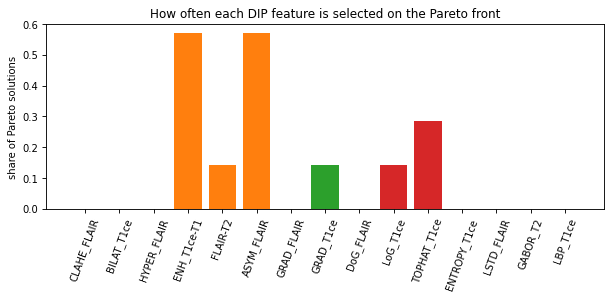

MRI-only       -> MRI-only
MRI+All-DIP    -> CLAHE_FLAIR+BILAT_T1ce+HYPER_FLAIR+ENH_T1ce-T1+FLAIR-T2+ASYM_FLAIR+GRAD_FLAIR+GRAD_T1ce+DoG_FLAIR+LoG_T1ce+TOPHAT_T1ce+ENTROPY_T1ce+LSTD_FLAIR+GABOR_T2+LBP_T1ce
R2S-BestDice   -> ENH_T1ce-T1
R2S-Knee       -> ENH_T1ce-T1+ASYM_FLAIR+GRAD_T1ce+TOPHAT_T1ce
R2S-Light      -> ENH_T1ce-T1


In [32]:
# ---- Pareto fronts (2D projections) ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(F_ALL[:, 2], 1 - F_ALL[:, 0], c="lightgrey", s=12, label="all evaluated")
ax[1].scatter(F_ALL[:, 1], 1 - F_ALL[:, 0], c="lightgrey", s=12)
for (m, sd), mk in zip([k for k in RUNS if k[1] == CFG["opt_seeds"][0]], ("o", "s", "^")):
    Fm = objs(RUNS[(m, sd)]); pm = pareto_mask(Fm)                     # 3-objective Pareto set (markers)
    p2 = pareto_mask(Fm[:, [0, 2]]); o = np.argsort(Fm[p2, 2])         # 2D accuracy-cost front (line)
    line, = ax[0].step(Fm[p2, 2][o], 1 - Fm[p2, 0][o], where="post", label=m, alpha=0.8)
    ax[0].scatter(Fm[pm, 2], 1 - Fm[pm, 0], marker=mk, color=line.get_color())
    ax[1].scatter(Fm[pm, 1], 1 - Fm[pm, 0], marker=mk, label=m, color=line.get_color())
ax[0].set_xlabel("feature cost f3 (ms/slice)"); ax[0].set_ylabel("CWRD (1 - f1)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("weighted HD95 f2 (mm)"); ax[1].set_ylabel("CWRD (1 - f1)")
fig.suptitle("Pareto fronts (proxy evaluation)")
show_save(fig, "p5_pareto_fronts")

# ---- the final R2S Pareto set, interpretable ----
prop_keys = sorted({k for (m, _), o in RUNS.items() if m == "R2S-NSGA-II" for k in o})
Fp = objs(prop_keys); pm = pareto_mask(Fp)
PARETO = pd.DataFrame([EVAL_CACHE[k] for k, p in zip(prop_keys, pm) if p]).sort_values("f3")
PARETO.to_csv(RES/"p5_pareto_set.csv", index=False)
print(PARETO[["features", "n_feat", "CWRD", "wHD95", "f3", "dice_WT", "dice_TC", "dice_ET"]].round(4).to_string(index=False))

bits = np.array([[int(c) for c in k] for k in PARETO.key])
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(FEAT_NAMES, bits.mean(0), color=[colors[g] for g in FEAT_GROUP]); ax.tick_params(axis="x", rotation=70)
ax.set_ylabel("share of Pareto solutions"); ax.set_title("How often each DIP feature is selected on the Pareto front")
show_save(fig, "p5_feature_frequency")

# ---- pick three solutions for the final study ----
Fn = norm(Fp[pm]); pk = np.array(prop_keys)[pm]
best_acc = pk[np.argmin(Fp[pm, 0])]
knee = pk[np.argmin(np.linalg.norm(Fn, axis=1))]                       # closest to the ideal point
cheap = [(f[0], k) for f, k in zip(Fp[pm], pk) if k != gkey(G_NONE) and f[2] <= 0.3 * Fp[pm, 2].max()]
light = min(cheap)[1] if cheap else knee
SELECTED = OrderedDict([("MRI-only", gkey(G_NONE)), ("MRI+All-DIP", gkey(G_ALL)),
                        ("R2S-BestDice", best_acc), ("R2S-Knee", knee), ("R2S-Light", light)])
json.dump(SELECTED, open(RES/"selected_solutions.json", "w"), indent=1)
for n, k in SELECTED.items(): print(f"{n:14s} -> {names_of([int(c) for c in k])}")


1. **Feature-group ablation.** *Additive*: MRI + one group at a time. *Subtractive*: all features minus one group. Shows which kind of image processing helps.
2. **Leave-one-feature-out** from the knee solution: how much each selected feature contributes.
3. **Optimiser-component ablation.** R²S-NSGA-II with one component removed (R₁ relevance guidance, R₂ redundancy repair, S surrogate) at the same budget – shows which of our ideas makes the search efficient.

Differences smaller than about 2× the proxy noise measured in Phase 4 should be reported as "no significant effect".

Group ablation (d = change in CWRD / weighted HD95; positive dCWRD = better):
     group  n  add_dCWRD  add_dHD  remove_dCWRD  remove_dHD
  Contrast  3     0.0141  -3.2287       -0.0091      1.3690
CrossModal  3     0.0083  -2.8532       -0.0051     -0.8603
      Edge  3     0.0001  -1.3694       -0.0096      2.2851
 BlobMorph  2     0.0071  -3.1613       -0.0165      3.3640
   Texture  4    -0.0126  -1.7663       -0.0131      1.8747

Leave-one-out from the knee solution (negative dCWRD = the feature was useful):
    removed   dCWRD    dHD  saved_ms
ENH_T1ce-T1 -0.0066 3.7435    0.3150
 ASYM_FLAIR  0.0004 3.5338    0.4073
  GRAD_T1ce -0.0064 5.0655    0.5650
TOPHAT_T1ce -0.0105 4.8273    0.3943


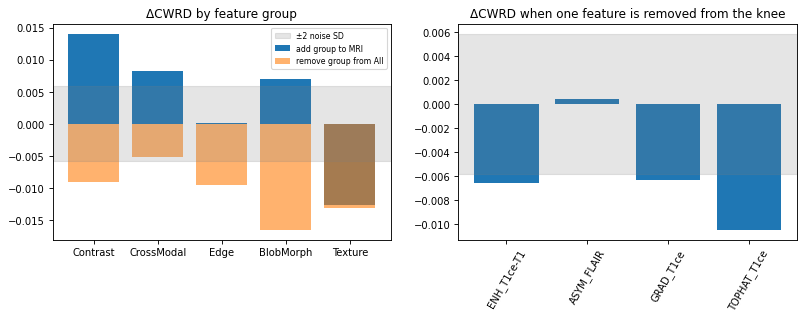

In [33]:
rows = []
base = EVAL_CACHE[gkey(G_NONE)]; full = EVAL_CACHE[gkey(G_ALL)]
for grp in GROUPS:
    add = (FEAT_GROUP == grp).astype(np.uint8); sub = (FEAT_GROUP != grp).astype(np.uint8)
    ra, rs = evaluate_genome(add, tag="ablation"), evaluate_genome(sub, tag="ablation")
    rows.append(dict(group=grp, n=int(add.sum()),
                     add_dCWRD=ra["CWRD"] - base["CWRD"], add_dHD=ra["wHD95"] - base["wHD95"],
                     remove_dCWRD=rs["CWRD"] - full["CWRD"], remove_dHD=rs["wHD95"] - full["wHD95"]))
ABL_G = pd.DataFrame(rows); ABL_G.to_csv(RES/"p6_group_ablation.csv", index=False)
print("Group ablation (d = change in CWRD / weighted HD95; positive dCWRD = better):")
print(ABL_G.round(4).to_string(index=False))

g_knee = np.array([int(c) for c in SELECTED["R2S-Knee"]], np.uint8); rk = EVAL_CACHE[SELECTED["R2S-Knee"]]; rows = []
for i in np.where(g_knee)[0]:
    g = g_knee.copy(); g[i] = 0; r = evaluate_genome(g, tag="ablation")
    rows.append(dict(removed=FEAT_NAMES[i], dCWRD=r["CWRD"] - rk["CWRD"], dHD=r["wHD95"] - rk["wHD95"], saved_ms=COST_MS[i]))
ABL_L = pd.DataFrame(rows); ABL_L.to_csv(RES/"p6_leave_one_out.csv", index=False)
print("\nLeave-one-out from the knee solution (negative dCWRD = the feature was useful):")
print(ABL_L.round(4).to_string(index=False) if len(ABL_L) else "knee solution has no features")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(ABL_G.group, ABL_G.add_dCWRD, label="add group to MRI"); ax[0].bar(ABL_G.group, ABL_G.remove_dCWRD, alpha=0.6, label="remove group from All")
ax[0].axhspan(-2*NOISE_SD, 2*NOISE_SD, color="grey", alpha=0.2, label="±2 noise SD"); ax[0].legend(fontsize=7); ax[0].set_title("ΔCWRD by feature group")
if len(ABL_L):
    ax[1].bar(ABL_L.removed, ABL_L.dCWRD); ax[1].tick_params(axis="x", rotation=60)
ax[1].axhspan(-2*NOISE_SD, 2*NOISE_SD, color="grey", alpha=0.2); ax[1].set_title("ΔCWRD when one feature is removed from the knee")
show_save(fig, "p6_feature_ablation")

In [34]:
if CFG["run_optimizer_ablation"]:
    sd = CFG["opt_seeds"][0]
    variants = {"R2S w/o R1 (relevance)": dict(PROPOSED, rel=False),
                "R2S w/o R2 (repair)": dict(PROPOSED, repair=False),
                "R2S w/o S (surrogate)": dict(PROPOSED, surrogate=False)}
    for vname, fl in variants.items():
        RUNS[(vname, sd)] = get_run(vname.replace(" ", "_").replace("/", "") + f"_s{sd}", lambda: run_moo(vname, fl, sd))
    ALL_KEYS = [k for k in EVAL_CACHE if "@" not in k]; F_ALL = objs(ALL_KEYS)
    IDEAL, NADIR = F_ALL.min(0), F_ALL.max(0)                        # re-normalise with every evaluation seen
    rows = []
    for vname in ["R2S-NSGA-II", *variants, "NSGA-II"]:
        c = hv_curve(RUNS[(vname, sd)]); rows.append(dict(variant=vname, final_HV=c[-1], HV_AUC=float(np.mean(c))))
    ABL_O = pd.DataFrame(rows); ABL_O.to_csv(RES/"p6_optimizer_ablation.csv", index=False)
    print(ABL_O.round(4).to_string(index=False))
else:
    print("Optimiser ablation skipped (CFG['run_optimizer_ablation'] = False)")

[  73.0 min] R2S w/o R1 (relevance) seed0 gen 1: 20/70 evals, best CWRD=0.8016
[  76.1 min] R2S w/o R1 (relevance) seed0 gen 2: 30/70 evals, best CWRD=0.8047
[  79.2 min] R2S w/o R1 (relevance) seed0 gen 3: 40/70 evals, best CWRD=0.8079
[  83.2 min] R2S w/o R1 (relevance) seed0 gen 4: 50/70 evals, best CWRD=0.8108
[  85.8 min] R2S w/o R1 (relevance) seed0 gen 5: 60/70 evals, best CWRD=0.8148
[  89.8 min] R2S w/o R1 (relevance) seed0 gen 6: 70/70 evals, best CWRD=0.8148
[  93.8 min] R2S w/o R2 (repair) seed0 gen 1: 20/70 evals, best CWRD=0.8044
[  97.4 min] R2S w/o R2 (repair) seed0 gen 2: 30/70 evals, best CWRD=0.8044
[  99.1 min] R2S w/o R2 (repair) seed0 gen 3: 40/70 evals, best CWRD=0.8110
[ 102.7 min] R2S w/o R2 (repair) seed0 gen 4: 50/70 evals, best CWRD=0.8110
[ 106.2 min] R2S w/o R2 (repair) seed0 gen 5: 60/70 evals, best CWRD=0.8110
[ 109.3 min] R2S w/o R2 (repair) seed0 gen 6: 70/70 evals, best CWRD=0.8110
[ 111.5 min] R2S w/o S (surrogate) seed0 gen 1: 20/70 evals, best CWRD

# Phase 7 — Final training and 3D evaluation on unseen test patients

The five configurations (MRI-only, MRI + all DIP features, and the three R²S Pareto solutions) are now trained **properly** (`final_epochs`, best epoch chosen on validation CWRD) and tested on the held-out test patients **in 3D at the original 240×240×155 resolution**:
* every axial slice is normalised, cropped, resized, the needed DIP features are computed (and timed), the U-Net predicts, the prediction is resized back and placed into the full volume;
* **Dice and HD95 (mm, 3D)** for WT/TC/ET with the BraTS conventions;
* **runtime:** measured feature-extraction time + U-Net inference time per patient, and model parameters;
* **statistics:** Wilcoxon signed-rank test of each model vs. MRI-only on per-patient Dice (paired, non-parametric), and Spearman correlation between proxy and final scores (does the cheap proxy rank models correctly?).

In [35]:
FINAL = OrderedDict()
seen = {}
for name, k in SELECTED.items():
    if k in seen:
        print(f"{name} is identical to {seen[k]} - skipped"); continue
    seen[k] = name
    fsel = [i for i, c in enumerate(k) if c == "1"]; ck = CKPT / f"{name}.pt"
    model = UNet(4 + len(fsel), 3, CFG["base_ch"]).to(device)
    src = locate(f"checkpoints/{name}.pt")
    if src is not None:
        model.load_state_dict(torch.load(src, map_location=device)); print("loaded", name)
    else:
        t0 = time.time()
        model, h = train_unet(fsel, TRAIN_IDX, CFG["final_epochs"], CFG["seed"], VAL_IDX, select_best=True)
        torch.save(model.state_dict(), ck); h.to_csv(RES / f"p7_history_{name}.csv", index=False)
        log(f"trained {name} in {(time.time()-t0)/60:.1f} min, best val CWRD {h.CWRD.max():.4f}")
    model.eval(); FINAL[name] = (fsel, model)
    free_memory()

[ 128.6 min] trained MRI-only in 2.2 min, best val CWRD 0.8315
[ 131.0 min] trained MRI+All-DIP in 2.4 min, best val CWRD 0.8241
[ 133.3 min] trained R2S-BestDice in 2.3 min, best val CWRD 0.8245
[ 135.6 min] trained R2S-Knee in 2.3 min, best val CWRD 0.8279
R2S-Light is identical to R2S-BestDice - skipped


In [36]:
@torch.no_grad()
def infer_patient(cid):
    img, seg = load_case(CASES[cid]); x, _ = zscore_normalise(img); del img
    gt = seg_to_regions(seg).astype(bool); D = x.shape[-1]
    xs = np.stack([prep_slice(x[..., z]) for z in range(D)]).astype(np.float32); del x
    union = sorted({i for fs, _ in FINAL.values() for i in fs})
    feats = np.zeros((D, K, S, S), np.float32); ftime = np.zeros(K)
    for z in range(D):
        b = np.any(xs[z] != 0, 0).astype(np.float32)
        if b.sum() == 0: continue
        for i in union:
            t0 = time.perf_counter(); feats[z, i] = FEATURES[FEAT_NAMES[i]][1](xs[z], b); ftime[i] += time.perf_counter() - t0
    xs_t = torch.from_numpy(xs); ft_t = torch.from_numpy(feats)
    rows, preds = [], {}
    for name, (fsel, model) in FINAL.items():
        t0 = time.perf_counter(); probs = []
        for s in range(0, D, 64):
            xb = xs_t[s:s+64].to(device)
            if fsel:
                fb = ft_t[s:s+64][:, fsel].to(device)
                fb = (fb - MU_T[fsel]) / SD_T[fsel]; xb = torch.cat([xb, fb], 1)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                probs.append(torch.sigmoid(model(xb).float()).cpu().numpy())
        if device.type == "cuda": torch.cuda.synchronize()
        t_inf = time.perf_counter() - t0
        probs = np.concatenate(probs)                                    # (D,3,S,S)
        pred = np.zeros((3, 240, 240, D), bool)
        for z in range(D):
            if probs[z].max() < 0.5: continue
            up = np.stack([cv2.resize(probs[z, r], (CROP, CROP), interpolation=cv2.INTER_LINEAR) for r in range(3)]) > 0.5
            pred[:, C0:C0+CROP, C0:C0+CROP, z] = up
        pred[1] &= pred[0]; pred[2] &= pred[1]
        rec = dict(case=cid, model=name, feat_ms=float(ftime[fsel].sum() * 1000), infer_ms=t_inf * 1000)
        for r, rn in enumerate(REGIONS):
            rec[f"dice_{rn}"] = dice(pred[r], gt[r]); rec[f"hd95_{rn}"] = hd95(pred[r], gt[r], (1, 1, 1), HD_PEN_3D)
        rec["CWRD"] = sum(W_REG[r] * rec[f"dice_{rn}"] for r, rn in enumerate(REGIONS))
        rows.append(rec); preds[name] = pred
    return rows, gt, xs, preds

test_ids = SPLIT["test"][: CFG["n_test_eval"]] if CFG["n_test_eval"] else SPLIT["test"]
TEST_CSV = RES / "test_results.csv"; bring_to_work("results/test_results.csv")
done = pd.read_csv(TEST_CSV) if TEST_CSV.exists() else pd.DataFrame(columns=["case", "model"])
done_cases = {c for c, g in done.groupby("case") if set(g.model) >= set(FINAL)}
QUAL = None
for i, cid in enumerate(test_ids):
    if cid in done_cases and not (QUAL is None and i == 0):   # already evaluated (patient 0 is redone once for the figure)
        continue
    rows, gt, xs, preds = infer_patient(cid)
    if QUAL is None:                                                   # keep one patient for the qualitative figure
        z = int(gt[0].sum((0, 1)).argmax())
        QUAL = dict(case=cid, z=z, flair=cv2.resize(xs[z, FL], (CROP, CROP)), gt=gt[:, C0:C0+CROP, C0:C0+CROP, z],
                    preds={n: p[:, C0:C0+CROP, C0:C0+CROP, z] for n, p in preds.items()})
    if cid not in done_cases:
        done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True); done.to_csv(TEST_CSV, index=False)
    del gt, xs, preds; gc.collect()
    if (i + 1) % 5 == 0 or i + 1 == len(test_ids): log(f"tested {i+1}/{len(test_ids)} patients")
TEST = pd.read_csv(TEST_CSV); TEST = TEST[TEST.model.isin(FINAL) & TEST.case.isin(test_ids)]

[ 137.4 min] tested 5/38 patients
[ 138.7 min] tested 10/38 patients
[ 140.0 min] tested 15/38 patients
[ 141.3 min] tested 20/38 patients
[ 142.6 min] tested 25/38 patients
[ 143.9 min] tested 30/38 patients
[ 145.3 min] tested 35/38 patients
[ 146.1 min] tested 38/38 patients


In [37]:
from scipy.stats import wilcoxon, spearmanr
params = {n: sum(p.numel() for p in m.parameters()) for n, (_, m) in FINAL.items()}
agg = TEST.groupby("model").agg(**{f"{c}_{s}": (c, s) for c in
      ["dice_WT", "dice_TC", "dice_ET", "CWRD", "hd95_WT", "hd95_TC", "hd95_ET", "feat_ms", "infer_ms"] for s in ("mean", "std")})
agg["params"] = pd.Series(params); agg = agg.loc[[n for n in FINAL]]
agg["runtime_s_per_patient"] = (agg.feat_ms_mean + agg.infer_ms_mean) / 1000
agg.to_csv(RES / "p7_final_table.csv")
show = pd.DataFrame({c: agg[f"{c}_mean"].round(4).astype(str) + " ± " + agg[f"{c}_std"].round(3).astype(str)
                     for c in ["dice_WT", "dice_TC", "dice_ET", "CWRD", "hd95_WT", "hd95_TC", "hd95_ET"]})
show["runtime (s/patient)"] = agg.runtime_s_per_patient.round(2); show["params"] = agg.params
print(show.to_string())

rows = []
ref = TEST[TEST.model == "MRI-only"].set_index("case")
for name in FINAL:
    if name == "MRI-only": continue
    cur = TEST[TEST.model == name].set_index("case").loc[ref.index]
    for m in ["dice_WT", "dice_TC", "dice_ET", "CWRD"]:
        diff = cur[m].values - ref[m].values
        p = wilcoxon(cur[m].values, ref[m].values).pvalue if np.any(diff != 0) and len(diff) >= 6 else np.nan
        rows.append(dict(model=name, metric=m, mean_diff=diff.mean(), p_value=p))
STATS = pd.DataFrame(rows); STATS.to_csv(RES / "p7_wilcoxon_vs_mri_only.csv", index=False)
print("\nWilcoxon signed-rank vs MRI-only (p < 0.05 = significant; needs >= 6 patients):")
print(STATS.round(4).to_string(index=False))

proxy = [EVAL_CACHE[SELECTED[n]]["CWRD"] for n in FINAL]; final = [agg.loc[n, "CWRD_mean"] for n in FINAL]
if len(FINAL) >= 3:
    rho = spearmanr(proxy, final).correlation
    print(f"\nSpearman rank correlation proxy-CWRD vs test-CWRD over {len(FINAL)} models: {rho:.2f}")

                     dice_WT         dice_TC         dice_ET            CWRD           hd95_WT           hd95_TC            hd95_ET  runtime (s/patient)   params
model                                                                                                                                                            
MRI-only        0.887 ± 0.06  0.7713 ± 0.205  0.7145 ± 0.252  0.7775 ± 0.162    12.2213 ± 18.8  10.0483 ± 14.442   36.3077 ± 101.03                 0.10  1942755
MRI+All-DIP   0.8907 ± 0.058  0.7603 ± 0.243  0.6996 ± 0.255  0.7687 ± 0.168  13.3887 ± 21.138  10.3819 ± 13.257  37.4974 ± 100.705                10.63  1944915
R2S-BestDice  0.8906 ± 0.064   0.773 ± 0.235   0.7508 ± 0.22  0.7935 ± 0.139    8.1815 ± 11.33    8.9263 ± 8.131   24.4816 ± 83.574                 0.14  1942899
R2S-Knee      0.8911 ± 0.061  0.7617 ± 0.233  0.7182 ± 0.248  0.7766 ± 0.165  13.9956 ± 22.601   11.2045 ± 14.71  36.1745 ± 100.949                 0.33  1943331

Wilcoxon signed-rank vs MRI

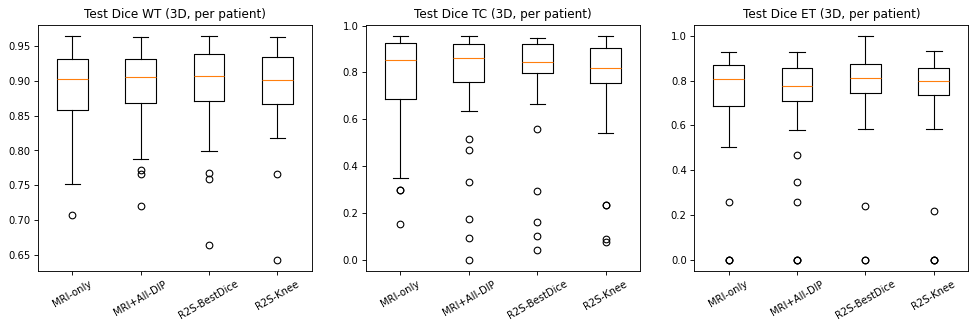

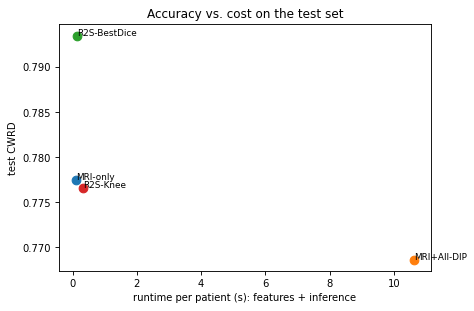

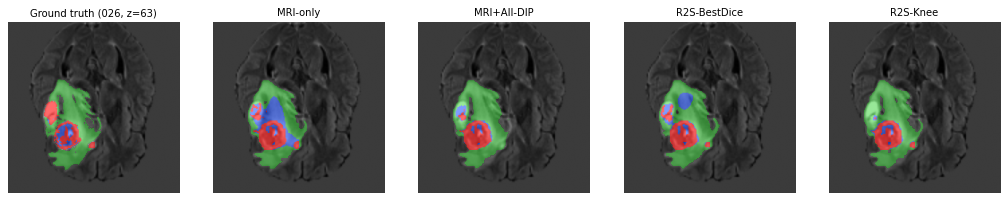

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for r, rn in enumerate(REGIONS):
    ax[r].boxplot([TEST[TEST.model == n][f"dice_{rn}"] for n in FINAL])
    ax[r].set_xticks(range(1, len(FINAL) + 1)); ax[r].set_xticklabels(list(FINAL))
    ax[r].set_title(f"Test Dice {rn} (3D, per patient)"); ax[r].tick_params(axis="x", rotation=30)
show_save(fig, "p7_test_dice_boxplots")

fig, ax = plt.subplots(figsize=(6, 4))
for n in FINAL:
    ax.scatter(agg.loc[n, "runtime_s_per_patient"], agg.loc[n, "CWRD_mean"], s=60); ax.annotate(n, (agg.loc[n, "runtime_s_per_patient"], agg.loc[n, "CWRD_mean"]), fontsize=8)
ax.set_xlabel("runtime per patient (s): features + inference"); ax.set_ylabel("test CWRD"); ax.set_title("Accuracy vs. cost on the test set")
show_save(fig, "p7_accuracy_vs_runtime")

if QUAL is not None:
    names = list(QUAL["preds"]); fig, ax = plt.subplots(1, len(names) + 1, figsize=(3.2 * (len(names) + 1), 3.4))
    def overlay(a, lab, title):
        a.imshow(np.rot90(QUAL["flair"]), cmap="gray"); a.imshow(np.rot90(label_rgba(lab))); a.set_title(title, fontsize=9); a.axis("off")
    overlay(ax[0], QUAL["gt"], f"Ground truth ({QUAL['case'][-3:]}, z={QUAL['z']})")
    for a, n in zip(ax[1:], names): overlay(a, QUAL["preds"][n], n)
    show_save(fig, "p7_qualitative")

# Phase 8 — Paper-ready outputs

All numbers used in the paper are in `/kaggle/working/results`, all figures in `/kaggle/working/figures`. The cell below writes LaTeX versions of the main tables and zips everything into `paper_assets.zip` (download it from the *Output* panel).

**Suggested paper structure**
1. *Introduction* – DIP features encode radiological knowledge; feeding them to a CNN costs compute; nobody knows which ones matter → multi-objective feature-channel selection.
2. *Related work* – BraTS & U-Net; hand-crafted features in segmentation; evolutionary multi-objective optimisation / NSGA-II; surrogate-assisted evolutionary algorithms.
3. *Method* – feature bank (Phase 3 table), relevance/novelty/redundancy analysis, CWRD objective, R²S-NSGA-II (algorithm box with the three components), proxy evaluation with common random numbers.
4. *Experimental setup* – data, split, pre-processing, U-Net, budgets, hardware (Phase 0 config).
5. *Results* – RQ1: final table + Wilcoxon (Phase 7); RQ2: Pareto fronts and feature frequency (Phase 5); RQ3: hypervolume curves (Phase 5); RQ4: ablations (Phase 6).
6. *Discussion & limitations* – 2D model, subset of patients, proxy fidelity (report the Spearman ρ), single dataset.

In [39]:
def to_latex_safe(df, path):
    try:
        df.to_latex(path, float_format="%.4f")
    except Exception as e:
        print("LaTeX export skipped for", path.name, "-", e)

to_latex_safe(FSTAT.drop(columns=["mu", "sd"]), RES / "tab_features.tex")
to_latex_safe(OPT_SUMMARY, RES / "tab_optimizers.tex")
to_latex_safe(ABL_G, RES / "tab_group_ablation.tex")
to_latex_safe(show, RES / "tab_final_test.tex")
to_latex_safe(STATS, RES / "tab_wilcoxon.tex")
json.dump(CFG, open(RES / "config_used.json", "w"), indent=1, default=str)

import zipfile
with zipfile.ZipFile(WORK / "paper_assets.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for d in (RES, FIG):
        for f in d.iterdir():
            z.write(f, f"{d.name}/{f.name}")
print("Wrote", WORK / "paper_assets.zip")
print(f"Total unique proxy evaluations: {len(ALL_KEYS)} | total notebook time: {(time.time()-T_START)/60:.1f} min")

Wrote /kaggle/working/paper_assets.zip
Total unique proxy evaluations: 322 | total notebook time: 147.5 min
